# Topology-Aware Attention U-Net: Multi-Task Retinal Vessel + Artery–Vein Segmentation, CIMT Classification and CIMT Regression

### Q1 journal notebook — publication-quality figures (600 dpi, Times New Roman 12 pt bold) and tables

| Task | Output | Type |
|---|---|---|
| **Task 1** | CIMT Classification | Binary (Normal / Thickened) |
| **Task 2** | CIMT Regression | Continuous thickness (mm) |
| **Task 3** | Vessel Segmentation | Binary mask + **topology-aware** losses (soft-clDice, thin/branch BCE) |
| **Task 4** | **Artery–Vein Segmentation** | Multi-class (Background / Artery / Vein) |

**Figures (auto-numbered)**  
1 Dataset overview · 2 Architecture · 3 Test performance (ROC / PR / scatter / Bland–Altman / calibration) · 4 Qualitative vessel + A/V · 5 Topology quantitative · 6 Training curves

**Tables (auto-numbered)**  
1 Dataset characteristics · 2 Implementation details · 3 Model complexity · 4 Main test results (95 % CI) · 5 Subgroup analysis · 6 Topology / thin-vessel / A/V metrics

All fonts: **Times New Roman, 12 pt, bold**. Every figure exported as 600 dpi PNG + vector PDF + 600 dpi TIFF (LZW).

**Backbone: Attention U-Net** (Oktay et al.) with Attention Gates on skip connections.

## 1. Setup


In [1]:
import os, re, glob, json, time, random, math, warnings, copy, zipfile, shutil, subprocess, sys
import numpy as np, pandas as pd
from PIL import Image
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, Patch
from matplotlib.lines import Line2D
import seaborn as sns
from IPython.display import display, HTML

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             accuracy_score, f1_score, precision_score, recall_score, matthews_corrcoef,
                             brier_score_loss, confusion_matrix, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda | torch 2.11.0+cu130
GPU: Tesla T4


## 2. Config and switches


In [2]:
CFG = dict(
    images_dir = "/kaggle/input/datasets/rofikbme/fundus-image/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset",
    masks_dir  = "/kaggle/input/datasets/rofikbme/fundus-image/predicted_masks_5806",
    csv_path   = "/kaggle/input/datasets/rofikbme/fundus-image/data_info.csv",
    av_masks_dir = "/kaggle/input/datasets/amimulhasan/fundus-imagel/Fundus_A and V/Fundus_A and V",
    out_dir    = "/kaggle/working",
    img_size   = 512,
    batch_size = 8,
    epochs     = 30,
    lr         = 1e-4,
    weight_decay = 1e-5,
    num_workers = 2,
    base_ch    = 32,          # Attention U-Net base channels
    # loss weights
    lam        = 0.5,
    w_cl       = 0.5,
    w_wb       = 0.5,
    cl_iters   = 10,
    thin_boost = 2.0,
    branch_boost = 4.0,
    w_seg = 1.0, w_cls = 1.0, w_reg = 1.0, w_av = 1.0,
    amp        = True,
    seed       = 42,
    debug      = False,
)

RUN_TRAINING  = True
CKPT_DIR      = CFG["out_dir"]
GENDER_NAMES  = {0: "Gender 0", 1: "Gender 1"}
CLASS_NAMES   = {0: "Class 0", 1: "Class 1"}
AV_CLASS_NAMES = {0: "Background", 1: "Artery", 2: "Vein"}

os.makedirs(CFG["out_dir"], exist_ok=True)
set_seed(CFG["seed"])
USE_AMP = bool(CFG["amp"] and device.type == "cuda")
if CFG["debug"]:
    CFG.update(epochs=2, img_size=128, batch_size=4)

def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP)
print(CFG)


{'images_dir': '/kaggle/input/datasets/rofikbme/fundus-image/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset', 'masks_dir': '/kaggle/input/datasets/rofikbme/fundus-image/predicted_masks_5806', 'csv_path': '/kaggle/input/datasets/rofikbme/fundus-image/data_info.csv', 'av_masks_dir': '/kaggle/input/datasets/amimulhasan/fundus-imagel/Fundus_A and V/Fundus_A and V', 'out_dir': '/kaggle/working', 'img_size': 512, 'batch_size': 8, 'epochs': 30, 'lr': 0.0001, 'weight_decay': 1e-05, 'num_workers': 2, 'base_ch': 32, 'lam': 0.5, 'w_cl': 0.5, 'w_wb': 0.5, 'cl_iters': 10, 'thin_boost': 2.0, 'branch_boost': 4.0, 'w_seg': 1.0, 'w_cls': 1.0, 'w_reg': 1.0, 'w_av': 1.0, 'amp': True, 'seed': 42, 'debug': False}


## 3. Journal formatting helpers (Times New Roman 12 pt bold, 600 dpi)


In [3]:
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
FIG_DPI, SAVE_TIFF = 600, True
Image.MAX_IMAGE_PIXELS = None
FS = 12

sns.set_theme(style="ticks", context="notebook", palette="colorblind")
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif", "Nimbus Roman", "serif"],
    "font.size": FS, "font.weight": "bold",
    "axes.titlesize": FS, "axes.titleweight": "bold",
    "axes.labelsize": FS, "axes.labelweight": "bold",
    "xtick.labelsize": FS, "ytick.labelsize": FS,
    "legend.fontsize": FS, "legend.title_fontsize": FS, "legend.frameon": False,
    "figure.titlesize": FS, "figure.titleweight": "bold",
    "axes.linewidth": 1.5, "xtick.major.width": 1.5, "ytick.major.width": 1.5,
    "xtick.major.size": 5, "ytick.major.size": 5, "lines.linewidth": 2.0,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.pad_inches": 0.05,
    "savefig.facecolor": "white", "figure.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "mathtext.fontset": "stix", "mathtext.default": "bf",
})
PAL = sns.color_palette("colorblind")

FIG_DIR = os.path.join(CFG["out_dir"], "journal_figures")
TAB_DIR = os.path.join(CFG["out_dir"], "journal_tables")
for _d in (FIG_DIR, TAB_DIR):
    os.makedirs(_d, exist_ok=True)
FIG_REGISTRY, TAB_REGISTRY = [], []

def _slot(registry, stem):
    for i, r in enumerate(registry):
        if r["stem"] == stem:
            return i + 1, i
    return len(registry) + 1, None

def say(text):
    display(HTML(f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:6px 0">{text}</p>'))

def ttl(ax, tag, text):
    ax.set_title(f"({tag}) {text}", loc="left", fontsize=FS, fontweight="bold", fontfamily="serif")

def save_fig(fig, stem, caption, dpi=None):
    n, old = _slot(FIG_REGISTRY, stem)
    dpi = dpi or FIG_DPI
    base = os.path.join(FIG_DIR, f"Fig{n:02d}_{stem}")
    fig.savefig(base + ".png", dpi=dpi)
    fig.savefig(base + ".pdf")
    tif = None
    if SAVE_TIFF:
        try:
            fig.savefig(base + ".tiff", dpi=dpi, pil_kwargs={"compression": "tiff_lzw"})
            tif = base + ".tiff"
        except Exception as e:
            print("  (TIFF export skipped:", type(e).__name__, e, ")")
    rec = dict(no=n, label=f"Fig. {n}", stem=stem, caption=caption,
               png=base + ".png", pdf=base + ".pdf", tiff=tif)
    if old is None:
        FIG_REGISTRY.append(rec)
    else:
        FIG_REGISTRY[old] = rec
    plt.show()
    display(HTML(
        f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:4px 0 18px 0">'
        f'Fig. {n}. {caption}</p>'))

def _table_css(align):
    return [
        {"selector": "", "props": [("border-collapse", "collapse"),
                                   ("border-top", "2px solid currentColor"),
                                   ("border-bottom", "2px solid currentColor"),
                                   ("margin", "4px 0 6px 0"),
                                   ("font-family", "Times New Roman, serif")]},
        {"selector": "th", "props": [("font-size", "12pt"), ("font-weight", "bold"),
                                     ("text-align", "center"),
                                     ("border-bottom", "1.5px solid currentColor"),
                                     ("padding", "5px 14px"),
                                     ("background-color", "transparent"),
                                     ("font-family", "Times New Roman, serif")]},
        {"selector": "td", "props": [("font-size", "12pt"), ("font-weight", "bold"),
                                     ("text-align", align), ("padding", "4px 14px"),
                                     ("border", "none"),
                                     ("font-family", "Times New Roman, serif")]},
    ]

def show_table(df, stem, caption, index=False, precision=4, note=None, align="center",
               best_max=(), best_min=()):
    n, old = _slot(TAB_REGISTRY, stem)
    base = os.path.join(TAB_DIR, f"Table{n:02d}_{stem}")
    df.to_csv(base + ".csv", index=index)
    try:
        df.to_latex(base + ".tex", index=index, escape=True,
                    caption=caption.replace("%", r"\%"), label=f"tab:{stem}",
                    float_format=lambda v: f"{v:.{precision}f}")
    except Exception as e:
        print("  (LaTeX export skipped:", type(e).__name__, ")")
    rec = dict(no=n, label=f"Table {n}", stem=stem, caption=caption, df=df.copy(),
               index=index, precision=precision, note=note,
               csv=base + ".csv", tex=base + ".tex")
    if old is None:
        TAB_REGISTRY.append(rec)
    else:
        TAB_REGISTRY[old] = rec
    display(HTML(
        f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:12px 0 2px 0">'
        f'Table {n}. {caption}</p>'))
    sty = df.style
    if not index:
        sty = sty.hide(axis="index")
    sty = sty.format(precision=precision, na_rep="–").set_table_styles(_table_css(align))
    if best_max:
        sty = sty.highlight_max(subset=list(best_max), props="text-decoration: underline;")
    if best_min:
        sty = sty.highlight_min(subset=list(best_min), props="text-decoration: underline;")
    display(sty)
    if note:
        display(HTML(
            f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:2px 0 14px 0">'
            f'{note}</p>'))

def fmt_ci(m, lo, hi, d=4):
    return f"{m:.{d}f} ({lo:.{d}f}–{hi:.{d}f})"

from contextlib import contextmanager
@contextmanager
def safe(name):
    try:
        yield
    except Exception as e:
        import traceback
        traceback.print_exc()
        print(f"\n[WARNING] section '{name}' failed and was skipped: {type(e).__name__}: {e}")

print("Journal style ready: Times New Roman | 12 pt bold | 600 dpi | figures ->", FIG_DIR)


Journal style ready: Times New Roman | 12 pt bold | 600 dpi | figures -> /kaggle/working/journal_figures


## 4. Data (Table 1, Fig. 1)


(5806, 7)


,image_name,thickness,label,True_age,age,gender,group
0,2491006_R.png,0.8,0,63,0.684932,0,1
1,2491006_L.png,0.8,0,63,0.684932,0,1
2,3730004_R.png,1.2,1,61,0.657534,1,1
3,3730004_L.png,1.2,1,61,0.657534,1,1
4,3730006_R.png,1.2,1,64,0.698630,1,1


patients train/val/test = 2603/200/100 | overlap tv=0 tt=0 vt=0
images train/val/test = 5206 400 200
{'age_mu': 48.09873223203996, 'age_sd': 12.819887685260232, 't_mu': 0.9951325393776411, 't_sd': 0.18354104606772081}
label counts (train): {1: 3808, 0: 1398}


Split,Patients,Images,"Age, years (mean ± SD)","Gender 1, n (%)","Class 1, n (%)","CIMT, mm (mean ± SD)"
Training,2603,5206,48.1 ± 12.8,3374 (64.8%),3808 (73.1%),1.00 ± 0.18
Validation,200,400,46.7 ± 13.3,224 (56.0%),200 (50.0%),0.92 ± 0.21
Test,100,200,46.4 ± 14.5,126 (63.0%),100 (50.0%),0.91 ± 0.19
Total,2903,5806,47.9 ± 12.9,3724 (64.1%),4108 (70.8%),0.99 ± 0.19


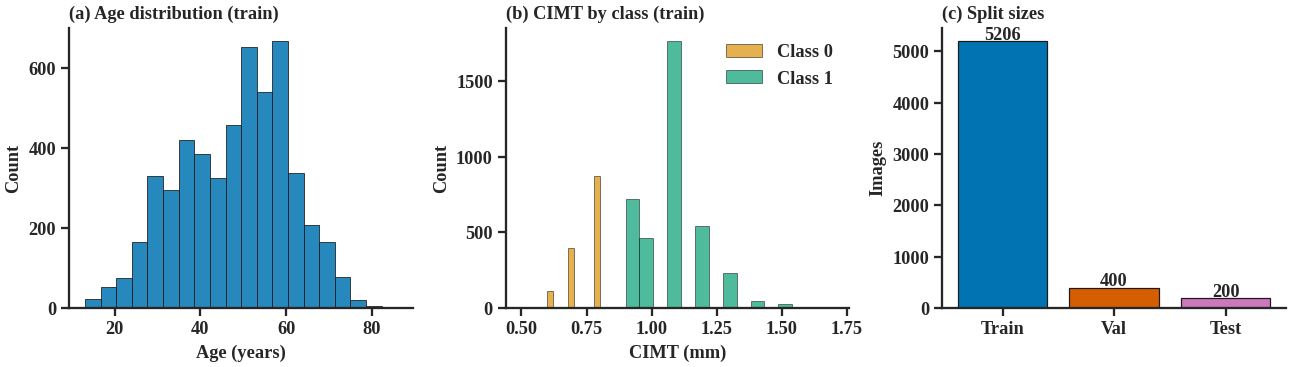

In [4]:

# ---- sanity-check the input paths early, with a readable message ----
for _k in ("images_dir", "masks_dir", "csv_path"):
    if not os.path.exists(CFG[_k]):
        raise FileNotFoundError(f"CFG['{_k}'] does not exist: {CFG[_k]}\nEdit the path in the Config cell.")
if not os.path.isdir(CFG["av_masks_dir"]):
    print("[WARNING] A/V mask folder not found -> Task 4 will be skipped (has_av = 0 for all images).")

def get_patient_id(base_name):
    return re.sub(r'(_L|_R|_OD|_OS)$', '', base_name, flags=re.IGNORECASE)

df = pd.read_csv(CFG["csv_path"])
print(df.shape)
display(df.head())

df["patient"] = df["image_name"].apply(lambda x: get_patient_id(os.path.splitext(str(x))[0]))
train_df = df[df["group"] == 1].reset_index(drop=True)
val_df   = df[df["group"] == 2].reset_index(drop=True)
test_df  = df[df["group"] == 3].reset_index(drop=True)

p_tr, p_va, p_te = set(train_df["patient"]), set(val_df["patient"]), set(test_df["patient"])
assert len(p_tr & p_va) == 0 and len(p_tr & p_te) == 0 and len(p_va & p_te) == 0
print(f"patients train/val/test = {len(p_tr)}/{len(p_va)}/{len(p_te)} | overlap tv=0 tt=0 vt=0")
print(f"images train/val/test = {len(train_df)} {len(val_df)} {len(test_df)}")

AGE_COL = "True_age" if "True_age" in df.columns else "age"
SCALER = dict(
    age_mu = float(train_df[AGE_COL].mean()),
    age_sd = float(train_df[AGE_COL].std() + 1e-8),
    t_mu   = float(train_df["thickness"].mean()),
    t_sd   = float(train_df["thickness"].std() + 1e-8),
)
print(SCALER)
print("label counts (train):", train_df["label"].value_counts().to_dict())

def _summ(split_df, name):
    n_pat = split_df["patient"].nunique()
    n_img = len(split_df)
    age_m, age_s = split_df[AGE_COL].mean(), split_df[AGE_COL].std()
    g1 = int((split_df["gender"] == 1).sum())
    c1 = int((split_df["label"] == 1).sum())
    t_m, t_s = split_df["thickness"].mean(), split_df["thickness"].std()
    return {
        "Split": name, "Patients": n_pat, "Images": n_img,
        "Age, years (mean ± SD)": f"{age_m:.1f} ± {age_s:.1f}",
        "Gender 1, n (%)": f"{g1} ({100 * g1 / max(n_img,1):.1f}%)",
        "Class 1, n (%)": f"{c1} ({100 * c1 / max(n_img,1):.1f}%)",
        "CIMT, mm (mean ± SD)": f"{t_m:.2f} ± {t_s:.2f}",
    }

tab1 = pd.DataFrame([_summ(train_df, "Training"), _summ(val_df, "Validation"),
                     _summ(test_df, "Test"), _summ(df, "Total")])
show_table(tab1, "dataset_characteristics",
           "Characteristics of the fundus-image dataset and the patient-level train / validation / test split.",
           note="Both eyes of a patient are always in the same split (verified, no patient overlap). CIMT = carotid intima-media thickness.")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].hist(train_df[AGE_COL], bins=20, color=PAL[0], alpha=0.85, edgecolor="k", linewidth=0.6)
axes[0].set_xlabel("Age (years)"); axes[0].set_ylabel("Count")
ttl(axes[0], "a", "Age distribution (train)")
for lab, col in [(0, PAL[1]), (1, PAL[2])]:
    sub = train_df[train_df["label"] == lab]["thickness"]
    axes[1].hist(sub, bins=15, alpha=0.7, color=col, label=CLASS_NAMES.get(lab, str(lab)), edgecolor="k", linewidth=0.5)
axes[1].set_xlabel("CIMT (mm)"); axes[1].set_ylabel("Count"); axes[1].legend(frameon=False)
ttl(axes[1], "b", "CIMT by class (train)")
sizes = [len(train_df), len(val_df), len(test_df)]
axes[2].bar(["Train", "Val", "Test"], sizes, color=[PAL[0], PAL[3], PAL[4]], edgecolor="k", linewidth=0.8)
axes[2].set_ylabel("Images")
for i, v in enumerate(sizes):
    axes[2].text(i, v + 30, str(v), ha="center", fontweight="bold", fontsize=FS)
ttl(axes[2], "c", "Split sizes")
plt.tight_layout()
save_fig(fig, "dataset_overview",
         "Dataset overview. (a) Age distribution in the training set. (b) CIMT distribution by disease class. (c) Number of images per split.")


## 5. Dataset and data loaders


In [5]:
def _find_file(folder, base, suffixes):
    """Return the first existing file folder/base+suffix (tries several extensions)."""
    for sfx in suffixes:
        p = os.path.join(folder, base + sfx)
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(f"No file for '{base}' in {folder} (tried {suffixes})")


def _load_av_mask(av_dir, base, size):
    if av_dir is None or not os.path.isdir(av_dir):
        return None
    candidates = [
        os.path.join(av_dir, base + "_av.png"),
        os.path.join(av_dir, base + "_AV.png"),
        os.path.join(av_dir, base + ".png"),
    ]
    for p in candidates:
        if os.path.isfile(p):
            m = np.asarray(Image.open(p).resize((size, size), Image.NEAREST))
            if m.ndim == 3:
                r, g, b = m[..., 0].astype(float), m[..., 1].astype(float), m[..., 2].astype(float)
                out = np.zeros(m.shape[:2], dtype=np.int64)
                out[(r > 120) & (r > g) & (r > b)] = 1
                out[(b > 120) & (b > r) & (b > g)] = 2
                return out
            m = m.astype(np.float32)
            if m.max() > 2:
                m = m / 255.0
            out = np.zeros_like(m, dtype=np.int64)
            out[m > 0.6] = 2
            out[(m > 0.2) & (m <= 0.6)] = 1
            return out
    art_p = [os.path.join(av_dir, base + "_artery.png"),
             os.path.join(av_dir, "artery", base + ".png"),
             os.path.join(av_dir, "Artery", base + ".png")]
    vein_p = [os.path.join(av_dir, base + "_vein.png"),
              os.path.join(av_dir, "vein", base + ".png"),
              os.path.join(av_dir, "Vein", base + ".png")]
    art = next((p for p in art_p if os.path.isfile(p)), None)
    vein = next((p for p in vein_p if os.path.isfile(p)), None)
    if art is None and vein is None:
        return None
    out = np.zeros((size, size), dtype=np.int64)
    if art is not None:
        a = np.asarray(Image.open(art).convert("L").resize((size, size), Image.NEAREST)) > 127
        out[a] = 1
    if vein is not None:
        v = np.asarray(Image.open(vein).convert("L").resize((size, size), Image.NEAREST)) > 127
        out[v] = 2
    return out


class MTDataset(Dataset):
    def __init__(self, images_dir, masks_dir, av_masks_dir, df, img_size=512, augment=False, scaler=None):
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.av_masks_dir = av_masks_dir
        self.df = df.reset_index(drop=True)
        self.img_size = img_size
        self.augment = augment
        self.sc = scaler if scaler is not None else SCALER
        n_av = 0
        for i in range(min(80, len(self.df))):
            base = os.path.splitext(str(self.df.iloc[i]["image_name"]))[0]
            if _load_av_mask(av_masks_dir, base, 64) is not None:
                n_av += 1
        print(f"  A/V mask probe (first 80): {n_av}/80 found")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        base = os.path.splitext(str(row["image_name"]))[0]
        s = self.img_size
        img_path = _find_file(self.images_dir, base, (".png", ".jpg", ".jpeg", ".tif", ".tiff"))
        mask_path = _find_file(self.masks_dir, base, ("_mask.png", "_mask.jpg", ".png", ".jpg"))
        img = Image.open(img_path).convert("RGB").resize((s, s), Image.BILINEAR)
        mask = Image.open(mask_path).convert("L").resize((s, s), Image.NEAREST)
        av = _load_av_mask(self.av_masks_dir, base, s)

        if self.augment:
            if random.random() < 0.5:
                img = img.transpose(Image.FLIP_LEFT_RIGHT)
                mask = mask.transpose(Image.FLIP_LEFT_RIGHT)
                if av is not None:
                    av = np.ascontiguousarray(np.fliplr(av))
            if random.random() < 0.5:
                a = random.uniform(-15, 15)
                img = img.rotate(a, resample=Image.BILINEAR)
                mask = mask.rotate(a, resample=Image.NEAREST)
                if av is not None:
                    av = np.asarray(Image.fromarray(av.astype(np.uint8)).rotate(a, resample=Image.NEAREST))

        img_np = np.asarray(img, dtype=np.float32) / 255.0
        mask_np = (np.asarray(mask, dtype=np.float32) / 255.0 > 0.5).astype(np.float32)
        if av is None:
            av_np = np.zeros((s, s), dtype=np.int64)
            has_av = 0.0
        else:
            av_np = av.astype(np.int64)
            has_av = 1.0

        if self.augment and random.random() < 0.3:
            rng = np.random.default_rng()
            img_np = np.clip(img_np + rng.normal(0, 0.02, img_np.shape), 0, 1).astype(np.float32)

        age = (float(row[AGE_COL]) - self.sc["age_mu"]) / self.sc["age_sd"]
        clin = torch.tensor([age, float(row["gender"])], dtype=torch.float32)
        thick = (float(row["thickness"]) - self.sc["t_mu"]) / self.sc["t_sd"]
        return (
            torch.from_numpy(img_np).permute(2, 0, 1).contiguous(),
            torch.from_numpy(mask_np).unsqueeze(0),
            torch.from_numpy(av_np).long(),
            torch.tensor(has_av, dtype=torch.float32),
            clin,
            torch.tensor(float(row["label"]), dtype=torch.float32),
            torch.tensor(thick, dtype=torch.float32),
        )


def _seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)


def make_ds_loader(df, augment, shuffle):
    ds = MTDataset(CFG["images_dir"], CFG["masks_dir"], CFG["av_masks_dir"],
                   df, CFG["img_size"], augment, SCALER)
    g = torch.Generator()
    g.manual_seed(CFG["seed"])
    dl = DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle, drop_last=augment,
                    num_workers=CFG["num_workers"], pin_memory=(device.type == "cuda"),
                    worker_init_fn=_seed_worker, generator=g)
    return ds, dl

train_ds, train_loader = make_ds_loader(train_df, True, True)
val_ds,   val_loader   = make_ds_loader(val_df, False, False)
test_ds,  test_loader  = make_ds_loader(test_df, False, False)
print(f"train={len(train_ds)} val={len(val_ds)} test={len(test_ds)}")


  A/V mask probe (first 80): 80/80 found
  A/V mask probe (first 80): 80/80 found
  A/V mask probe (first 80): 80/80 found
train=5206 val=400 test=200


## 6. Model: Attention U-Net Multi-Task (exactly matching the provided diagram)


In [6]:
# ============================================================
# Attention Gate (exactly as in the diagram)
# ============================================================
class AttentionGate(nn.Module):
    """
    Attention Gate from Oktay et al.
    Gating signal (from decoder) + Input features (from encoder skip)
    → Wg, Wx → Add → ReLU → Psi → Sigmoid → Resampler → α
    Output = α ⊙ Input Features
    """
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        # g: gating signal from coarser scale (decoder)
        # x: skip connection features from encoder
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        if g1.shape[2:] != x1.shape[2:]:
            g1 = F.interpolate(g1, size=x1.shape[2:], mode="bilinear", align_corners=False)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        # Resampler is already handled by the sigmoid + broadcast multiply
        return x * psi, psi


# ============================================================
# Basic Conv Block (Conv + BN + ReLU) × 2
# ============================================================
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)


# ============================================================
# Clinical MLP (for multi-task)
# ============================================================
class ClinicalMLP(nn.Module):
    def __init__(self, in_dim=2, hidden=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.LeakyReLU(0.01, inplace=True),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.01, inplace=True))
    def forward(self, x):
        return self.net(x)


# ============================================================
# Attention U-Net Multi-Task
# ============================================================
class AttentionUNetMultiTask(nn.Module):
    def __init__(self, in_ch=3, base_ch=32, clinical_dim=2, clinical_hidden=32,
                 fc_dim=128, use_clinical=True, n_av_classes=3):
        super().__init__()
        self.use_clinical = use_clinical
        self.clinical_hidden = clinical_hidden
        self.n_av_classes = n_av_classes

        # Encoder channels: base, 2×, 4×, 8×, 16×
        c1, c2, c3, c4, c5 = base_ch, base_ch*2, base_ch*4, base_ch*8, base_ch*16

        # ---------- Encoder ----------
        self.enc1 = ConvBlock(in_ch, c1)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(c1, c2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = ConvBlock(c2, c3)
        self.pool3 = nn.MaxPool2d(2)
        self.enc4 = ConvBlock(c3, c4)
        self.pool4 = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(c4, c5)

        # ---------- Attention Gates ----------
        # g = up-sampled decoder features (same channels as the skip), x = encoder skip features
        self.att4 = AttentionGate(F_g=c4, F_l=c4, F_int=c4//2)
        self.att3 = AttentionGate(F_g=c3, F_l=c3, F_int=c3//2)
        self.att2 = AttentionGate(F_g=c2, F_l=c2, F_int=c2//2)
        self.att1 = AttentionGate(F_g=c1, F_l=c1, F_int=c1//2)

        # ---------- Decoder ----------
        self.up4 = nn.ConvTranspose2d(c5, c4, kernel_size=2, stride=2)
        self.dec4 = ConvBlock(c4 + c4, c4)

        self.up3 = nn.ConvTranspose2d(c4, c3, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(c3 + c3, c3)

        self.up2 = nn.ConvTranspose2d(c3, c2, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(c2 + c2, c2)

        self.up1 = nn.ConvTranspose2d(c2, c1, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(c1 + c1, c1)

        # ---------- Segmentation Heads ----------
        self.seg_head = nn.Conv2d(c1, 1, kernel_size=1)
        self.av_head  = nn.Conv2d(c1, n_av_classes, kernel_size=1)

        # ---------- Clinical + Classification / Regression ----------
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.clinical_mlp = ClinicalMLP(clinical_dim, clinical_hidden)
        self.shared_fc = nn.Sequential(
            nn.Linear(c5 + clinical_hidden, fc_dim),
            nn.LeakyReLU(0.01, inplace=True),
            nn.Dropout(0.3)
        )
        self.cls_head = nn.Linear(fc_dim, 1)
        self.reg_head = nn.Linear(fc_dim, 1)

    def forward(self, x, clinical=None):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))
        b  = self.bottleneck(self.pool4(e4))

        # Decoder + Attention Gates (as in diagram)
        d4 = self.up4(b)
        e4_att, _ = self.att4(g=d4, x=e4)
        d4 = self.dec4(torch.cat([d4, e4_att], dim=1))

        d3 = self.up3(d4)
        e3_att, _ = self.att3(g=d3, x=e3)
        d3 = self.dec3(torch.cat([d3, e3_att], dim=1))

        d2 = self.up2(d3)
        e2_att, _ = self.att2(g=d2, x=e2)
        d2 = self.dec2(torch.cat([d2, e2_att], dim=1))

        d1 = self.up1(d2)
        e1_att, _ = self.att1(g=d1, x=e1)
        d1 = self.dec1(torch.cat([d1, e1_att], dim=1))

        # Heads
        seg = self.seg_head(d1)
        av  = self.av_head(d1)

        # Classification & Regression from bottleneck + clinical
        cls_logit = reg_pred = None
        if clinical is not None:
            pooled = self.gap(b).flatten(1)
            if self.use_clinical:
                cf = self.clinical_mlp(clinical)
            else:
                cf = pooled.new_zeros(pooled.shape[0], self.clinical_hidden)
            h = self.shared_fc(torch.cat([pooled, cf], dim=1))
            cls_logit = self.cls_head(h).squeeze(1)
            reg_pred  = self.reg_head(h).squeeze(1)

        return dict(seg=seg, av=av, deep=[seg], cls=cls_logit, reg=reg_pred, att={})


# Instantiate
model = AttentionUNetMultiTask(
    in_ch=3,
    base_ch=CFG["base_ch"],
    clinical_dim=2,
    clinical_hidden=32,
    fc_dim=128,
    use_clinical=True,
    n_av_classes=3
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {n_params:,}")

with torch.no_grad():
    model.eval()
    o = model(torch.randn(2, 3, min(CFG["img_size"], 128), min(CFG["img_size"], 128), device=device),
              torch.randn(2, 2, device=device))
print("seg:", tuple(o["seg"].shape), "| av:", tuple(o["av"].shape),
      "| cls:", tuple(o["cls"].shape), "| reg:", tuple(o["reg"].shape))


Total parameters: 7,923,042
seg: (2, 1, 128, 128) | av: (2, 3, 128, 128) | cls: (2,) | reg: (2,)


## 7. Architecture figure (Fig. 2) – matching the provided diagram


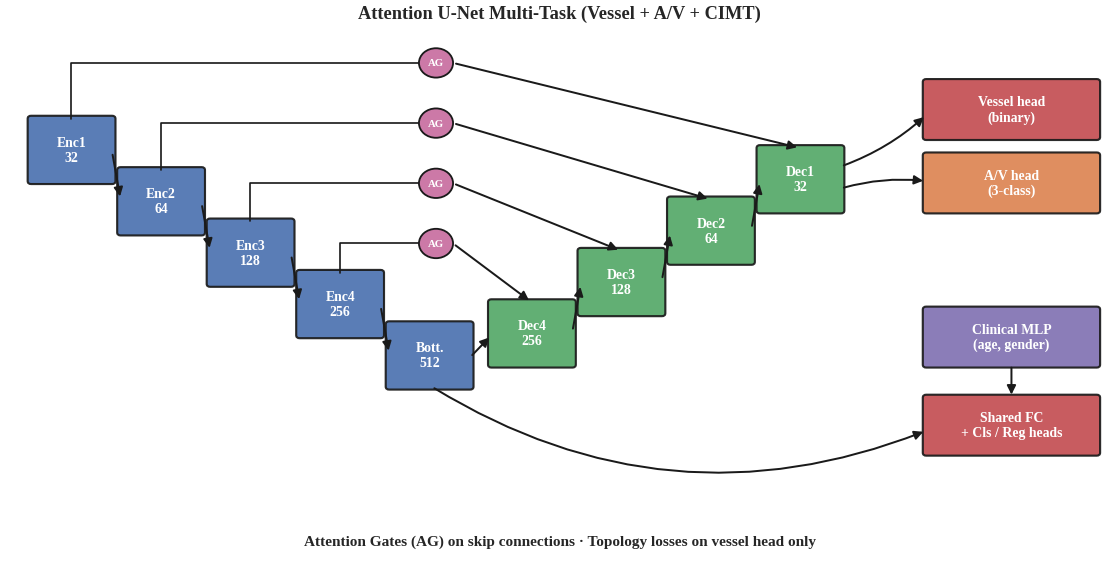

In [7]:
def draw_architecture():
    b = CFG["base_ch"]; chs = [b, b * 2, b * 4, b * 8, b * 16]
    fig, ax = plt.subplots(figsize=(13, 6.5))
    ax.set_xlim(0, 13); ax.set_ylim(0, 7.5); ax.axis("off")
    colors = dict(enc="#4C72B0", dec="#55A868", head="#C44E52", clin="#8172B2", av="#DD8452", att="#CC79A7")
    def box(x, y, w, h, txt, fc):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04",
                                    fc=fc, ec="k", lw=1.4, alpha=0.92))
        ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center",
                fontsize=9, fontweight="bold", color="white", fontfamily="serif")
    def arrow(p0, p1, rad=0.0):
        ax.annotate("", xy=p1, xytext=p0,
                    arrowprops=dict(arrowstyle="-|>", lw=1.3, color="k", connectionstyle=f"arc3,rad={rad}"))
    # Encoder (top-left -> bottom) ; last box = bottleneck
    enc_xy = [(0.3 + i * 1.05, 5.4 - i * 0.7) for i in range(5)]
    for i, (x, y) in enumerate(enc_xy):
        name = f"Enc{i + 1}" if i < 4 else "Bott."
        box(x, y, 0.95, 0.85, f"{name}\n{chs[i]}", colors["enc"])
        if i < 4:
            arrow((x + 0.95, y + 0.4), (enc_xy[i + 1][0], enc_xy[i + 1][1] + 0.45))
    # Decoder (bottom -> top-right)
    dec_xy = [(5.7 + i * 1.05, 2.9 + i * 0.7) for i in range(4)]
    for i, (x, y) in enumerate(dec_xy):
        box(x, y, 0.95, 0.85, f"Dec{4 - i}\n{chs[3 - i]}", colors["dec"])
        if i < 3:
            arrow((x + 0.95, y + 0.45), (dec_xy[i + 1][0], dec_xy[i + 1][1] + 0.4))
    arrow((enc_xy[4][0] + 0.95, enc_xy[4][1] + 0.4), (dec_xy[0][0], dec_xy[0][1] + 0.4))
    # Attention gates on skip connections (encoder level k -> decoder level k)
    for i in range(4):
        ex, ey = enc_xy[3 - i]; dx, dy = dec_xy[i]
        cx, cy = (ex + 0.95 + dx) / 2, ey + 1.25 + i * 0.12
        ax.plot([ex + 0.47, ex + 0.47, cx - 0.2], [ey + 0.85, cy, cy], "k-", lw=1.1)
        ax.add_patch(Circle((cx, cy), 0.2, fc=colors["att"], ec="k", lw=1.2, zorder=3))
        ax.text(cx, cy, "AG", ha="center", va="center", fontsize=7, fontweight="bold", color="white", zorder=4)
        arrow((cx + 0.2, cy), (dx + 0.47, dy + 0.85))
    # Heads
    box(10.8, 6.0, 2.0, 0.75, "Vessel head\n(binary)", colors["head"])
    box(10.8, 5.0, 2.0, 0.75, "A/V head\n(3-class)", colors["av"])
    arrow((dec_xy[3][0] + 0.95, dec_xy[3][1] + 0.6), (10.8, 6.3), 0.1)
    arrow((dec_xy[3][0] + 0.95, dec_xy[3][1] + 0.3), (10.8, 5.4), -0.1)
    box(10.8, 2.9, 2.0, 0.75, "Clinical MLP\n(age, gender)", colors["clin"])
    box(10.8, 1.7, 2.0, 0.75, "Shared FC\n+ Cls / Reg heads", colors["head"])
    arrow((enc_xy[4][0] + 0.5, enc_xy[4][1]), (10.8, 2.0), 0.25)
    arrow((11.8, 2.9), (11.8, 2.45))
    ax.text(6.5, 0.45,
            "Attention Gates (AG) on skip connections · Topology losses on vessel head only",
            ha="center", fontsize=10, fontweight="bold", fontfamily="serif")
    ax.set_title("Attention U-Net Multi-Task (Vessel + A/V + CIMT)",
                 fontweight="bold", fontfamily="serif", fontsize=FS)
    save_fig(fig, "architecture",
             "Network architecture. Attention U-Net encoder–decoder with Attention Gates on skip connections. "
             "Produces binary vessel mask (Task 3, topology-aware) and 3-class A/V mask (Task 4). "
             "Bottleneck features + clinical variables feed classification and regression heads.")

draw_architecture()


## 8. Implementation details (Table 2) and model complexity (Table 3)


In [8]:
# ---------------- Table 2: implementation details ----------------
impl = pd.DataFrame([
    ("Backbone", f"Attention U-Net (Oktay et al.), base channels = {CFG['base_ch']}, 4 attention-gated skips"),
    ("Input size", f"{CFG['img_size']} × {CFG['img_size']} RGB"),
    ("Optimiser", f"AdamW, lr = {CFG['lr']}, weight decay = {CFG['weight_decay']}, cosine schedule"),
    ("Batch size / epochs", f"{CFG['batch_size']} / {CFG['epochs']} (early stopping, patience 10)"),
    ("Mixed precision", str(USE_AMP)),
    ("Augmentation", "H-flip, ±15° rotation, Gaussian noise (train only)"),
    ("Segmentation loss", f"Dice + {CFG['w_cl']}·soft-clDice + {CFG['w_wb']}·topology-weighted BCE "
                          f"(thin ×{CFG['thin_boost']}, branch ×{CFG['branch_boost']}; skeleton iters = {CFG['cl_iters']})"),
    ("A/V loss", f"(1−{CFG['lam']})·CE + {CFG['lam']}·Dice (foreground classes), masked to images with A/V labels"),
    ("Classification / regression loss", "BCE with pos_weight / Smooth-L1 on standardised thickness"),
    ("Task weights (seg/cls/reg/AV)", f"{CFG['w_seg']} / {CFG['w_cls']} / {CFG['w_reg']} / {CFG['w_av']}"),
    ("Model selection", "Best composite validation score (AUC, Dice, soft-clDice, A/V Dice, 1−MAE/SD)"),
    ("Seed / device", f"{CFG['seed']} / {device}"),
], columns=["Item", "Setting"])
show_table(impl, "implementation_details", "Implementation details.", align="left")

# ---------------- Table 3: model complexity ----------------
def component_params(m):
    P = lambda *mods: sum(p.numel() for mod in mods for p in mod.parameters())
    parts = [
        ("Encoder", P(m.enc1, m.enc2, m.enc3, m.enc4, m.bottleneck)),
        ("Attention Gates", P(m.att1, m.att2, m.att3, m.att4)),
        ("Decoder", P(m.up1, m.up2, m.up3, m.up4, m.dec1, m.dec2, m.dec3, m.dec4)),
        ("Vessel head", P(m.seg_head)),
        ("A/V head", P(m.av_head)),
        ("Clinical + shared FC + cls/reg", P(m.clinical_mlp, m.shared_fc, m.cls_head, m.reg_head)),
    ]
    return pd.DataFrame(parts, columns=["Component", "Parameters"])

def measure_flops_latency(m, size, n_runs=20):
    m.eval()
    x = torch.randn(1, 3, size, size, device=device); c = torch.randn(1, 2, device=device)
    gflops = float("nan")
    try:
        from torch.utils.flop_counter import FlopCounterMode
        with torch.no_grad(), FlopCounterMode(display=False) as fc:
            m(x, c)
        gflops = fc.get_total_flops() / 2 / 1e9      # MACs ≈ FLOPs/2 (reported as GMACs)
    except Exception as e:
        print("  (FLOP counting skipped:", type(e).__name__, ")")
    with torch.no_grad():
        for _ in range(3): m(x, c)
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(n_runs): m(x, c)
        if device.type == "cuda": torch.cuda.synchronize()
    return gflops, (time.time() - t0) / n_runs * 1000

cp = component_params(model)
gmacs, lat_ms = measure_flops_latency(model, CFG["img_size"])
cp["Parameters (M)"] = (cp["Parameters"] / 1e6).round(4)
cp["Share (%)"] = (100 * cp["Parameters"] / cp["Parameters"].sum()).round(1)
tot = pd.DataFrame([{"Component": "Total", "Parameters": int(cp["Parameters"].sum()),
                     "Parameters (M)": round(cp["Parameters"].sum() / 1e6, 4), "Share (%)": 100.0}])
tab3 = pd.concat([cp, tot], ignore_index=True)[["Component", "Parameters (M)", "Share (%)"]]
show_table(tab3, "model_complexity", "Model complexity of the proposed multi-task Attention U-Net.",
           align="left", precision=4,
           note=f"Computed at {CFG['img_size']}×{CFG['img_size']}: {gmacs:.1f} GMACs, "
                f"{lat_ms:.1f} ms / image (batch 1, {device.type.upper()}).")
n_params = int(cp["Parameters"].sum())
print("Total parameters:", f"{n_params:,}")


Item,Setting
Backbone,"Attention U-Net (Oktay et al.), base channels = 32, 4 attention-gated skips"
Input size,512 × 512 RGB
Optimiser,"AdamW, lr = 0.0001, weight decay = 1e-05, cosine schedule"
Batch size / epochs,"8 / 30 (early stopping, patience 10)"
Mixed precision,True
Augmentation,"H-flip, ±15° rotation, Gaussian noise (train only)"
Segmentation loss,"Dice + 0.5·soft-clDice + 0.5·topology-weighted BCE (thin ×2.0, branch ×4.0; skeleton iters = 10)"
A/V loss,"(1−0.5)·CE + 0.5·Dice (foreground classes), masked to images with A/V labels"
Classification / regression loss,BCE with pos_weight / Smooth-L1 on standardised thickness
Task weights (seg/cls/reg/AV),1.0 / 1.0 / 1.0 / 1.0


Component,Parameters (M),Share (%)
Encoder,4.7142,59.5000
Attention Gates,0.0887,1.1000
Decoder,3.0488,38.5000
Vessel head,0.0000,0.0000
A/V head,0.0001,0.0000
Clinical + shared FC + cls/reg,0.0712,0.9000
Total,7.9230,100.0000


Total parameters: 7,923,042


## 9. Losses (vessel topology + multi-class A/V + CIMT) and metrics

Vessel: Dice + soft-clDice + thin/branch-weighted BCE. A/V: CE + Dice (only on images with A/V labels). CIMT: weighted BCE (classification) + Smooth-L1 (regression).

In [9]:
# ============================================================
# Losses: vessel topology (soft-clDice, thin/branch-weighted BCE) + multi-class A/V + CIMT tasks
# ============================================================
def soft_erode(x):
    p1 = -F.max_pool2d(-x, (3, 1), (1, 1), (1, 0))
    p2 = -F.max_pool2d(-x, (1, 3), (1, 1), (0, 1))
    return torch.min(p1, p2)

def soft_dilate(x):
    return F.max_pool2d(x, (3, 3), (1, 1), (1, 1))

def soft_open(x):
    return soft_dilate(soft_erode(x))

def soft_skel(x, iters=10):
    """Differentiable skeleton (Shit et al., clDice)."""
    x1 = soft_open(x)
    skel = F.relu(x - x1)
    for _ in range(iters):
        x = soft_erode(x)
        x1 = soft_open(x)
        delta = F.relu(x - x1)
        skel = skel + F.relu(delta - skel * delta)
    return skel


class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__(); self.s = smooth
    def forward(self, logits, target):
        p = torch.sigmoid(logits).flatten(1); t = target.flatten(1)
        d = (2 * (p * t).sum(1) + self.s) / (p.sum(1) + t.sum(1) + self.s)
        return (1 - d).mean()


class SoftclDiceLoss(nn.Module):
    def __init__(self, iters=10, smooth=1.0):
        super().__init__(); self.iters, self.s = iters, smooth
    def forward(self, logits, target):
        p = torch.sigmoid(logits)
        sp, st = soft_skel(p, self.iters), soft_skel(target, self.iters)
        d = (1, 2, 3)
        tprec = ((sp * target).sum(d) + self.s) / (sp.sum(d) + self.s)
        tsens = ((st * p).sum(d) + self.s) / (st.sum(d) + self.s)
        cl = 2 * tprec * tsens / (tprec + tsens + 1e-8)
        return (1 - cl).mean()


class TopoWeightedBCE(nn.Module):
    """BCE with extra weight on thin vessels (mask minus its opening) and branch points."""
    def __init__(self, thin_boost=2.0, branch_boost=4.0, open_k=5, iters=10):
        super().__init__()
        self.tb, self.bb, self.k, self.iters = thin_boost, branch_boost, open_k, iters
        self.register_buffer("nb_kernel", torch.ones(1, 1, 3, 3))

    @torch.no_grad()
    def weight_map(self, t):
        k, pad = self.k, self.k // 2
        er = -F.max_pool2d(-t, k, 1, pad)
        op = F.max_pool2d(er, k, 1, pad)
        thin = F.relu(t - op)
        skel = (soft_skel(t, self.iters) > 0.5).float()
        nb = F.conv2d(skel, self.nb_kernel.to(t.dtype), padding=1)
        branch = F.max_pool2d(skel * (nb >= 4).float(), 5, 1, 2)
        return 1.0 + self.tb * thin + self.bb * branch

    def forward(self, logits, target):
        w = self.weight_map(target)
        l = F.binary_cross_entropy_with_logits(logits, target, reduction="none")
        return (w * l).sum() / w.sum()


class MultiClassDiceLoss(nn.Module):
    """Soft Dice over foreground classes (1..C-1); samples without A/V labels are masked out."""
    def __init__(self, n_classes=3, smooth=1.0):
        super().__init__(); self.n, self.s = n_classes, smooth
    def forward(self, logits, target, valid):
        p = F.softmax(logits, 1)
        oh = F.one_hot(target, self.n).permute(0, 3, 1, 2).float()
        d = (2, 3)
        dice = (2 * (p * oh).sum(d) + self.s) / (p.sum(d) + oh.sum(d) + self.s)   # (B, C)
        per = 1 - dice[:, 1:].mean(1)
        return (per * valid).sum() / valid.sum().clamp(min=1.0)


class MultiTaskLoss(nn.Module):
    def __init__(self, lam, w_seg, w_cls, w_reg, w_av, pos_weight=None, cl_iters=10,
                 thin_boost=2.0, branch_boost=4.0, w_cl=0.5, w_wb=0.5):
        super().__init__()
        self.lam, self.w_seg, self.w_cls, self.w_reg, self.w_av = lam, w_seg, w_cls, w_reg, w_av
        self.w_cl, self.w_wb = w_cl, w_wb
        self.dice = DiceLoss()
        self.cldice = SoftclDiceLoss(cl_iters)
        self.wbce = TopoWeightedBCE(thin_boost, branch_boost, iters=cl_iters)
        self.av_dice = MultiClassDiceLoss(3)
        self.register_buffer("pos_weight", pos_weight if pos_weight is not None else torch.ones(1))

    def forward(self, out, mask, av, has_av, y_cls, y_reg):
        seg_logit = out["seg"].float()
        l_dice = self.dice(seg_logit, mask)
        l_cl = self.cldice(seg_logit, mask)
        l_wb = self.wbce(seg_logit, mask)
        l_seg = l_dice + self.w_cl * l_cl + self.w_wb * l_wb

        av_logit = out["av"].float()
        if has_av.sum() > 0:
            ce = F.cross_entropy(av_logit, av, reduction="none").mean((1, 2))
            l_ce = (ce * has_av).sum() / has_av.sum()
            l_av = (1 - self.lam) * l_ce + self.lam * self.av_dice(av_logit, av, has_av)
        else:
            l_av = av_logit.sum() * 0.0

        l_cls = F.binary_cross_entropy_with_logits(out["cls"].float(), y_cls, pos_weight=self.pos_weight)
        l_reg = F.smooth_l1_loss(out["reg"].float(), y_reg)

        total = self.w_seg * l_seg + self.w_cls * l_cls + self.w_reg * l_reg + self.w_av * l_av
        parts = dict(total=total.item(), seg=l_seg.item(), dice=l_dice.item(), cldice=l_cl.item(),
                     wbce=l_wb.item(), av=l_av.item(), cls=l_cls.item(), reg=l_reg.item())
        return total, parts


pos = int((train_df["label"] == 1).sum())
neg = int((train_df["label"] == 0).sum())
pos_weight = torch.tensor([neg / max(pos, 1)], device=device, dtype=torch.float32)

criterion = MultiTaskLoss(
    CFG["lam"], CFG["w_seg"], CFG["w_cls"], CFG["w_reg"], CFG["w_av"],
    pos_weight=pos_weight, cl_iters=CFG["cl_iters"],
    thin_boost=CFG["thin_boost"], branch_boost=CFG["branch_boost"],
    w_cl=CFG["w_cl"], w_wb=CFG["w_wb"]).to(device)

# quick smoke test of the loss on one real batch
_b = next(iter(val_loader))
_img, _m, _av, _hav, _cl, _y, _t = [x.to(device) for x in _b]
with torch.no_grad():
    _o = model(_img, _cl)
    _, _p = criterion(_o, _m, _av, _hav, _y, _t)
print("loss smoke test:", {k: round(v, 4) for k, v in _p.items()})
del _b, _img, _m, _av, _hav, _cl, _y, _t, _o


loss smoke test: {'total': 3.4952, 'seg': 1.5301, 'dice': 0.8438, 'cldice': 0.7074, 'wbce': 0.665, 'av': 1.0468, 'cls': 0.2423, 'reg': 0.676}


In [10]:
# ============================================================
# Evaluation metrics (numpy): overlap, topology, thin vessels, branch points, A/V
# ============================================================
from scipy import ndimage as ndi
from skimage.morphology import skeletonize, disk

_S8 = np.ones((3, 3), dtype=int)

def _dice(a, b):
    s = a.sum() + b.sum()
    return 1.0 if s == 0 else 2.0 * (a & b).sum() / s

def seg_metrics_np(pred, gt):
    """pred, gt: boolean (H, W). Returns dict of overlap + topology metrics."""
    pred, gt = pred.astype(bool), gt.astype(bool)
    tp = (pred & gt).sum(); fp = (pred & ~gt).sum(); fn = (~pred & gt).sum(); tn = (~pred & ~gt).sum()
    m = dict(dice=_dice(pred, gt), iou=tp / max(tp + fp + fn, 1),
             sens=tp / max(tp + fn, 1), spec=tn / max(tn + fp, 1), prec=tp / max(tp + fp, 1))
    sp, sg = skeletonize(pred), skeletonize(gt)
    tprec = (sp & gt).sum() / max(sp.sum(), 1)
    tsens = (sg & pred).sum() / max(sg.sum(), 1)
    m["cldice"] = 2 * tprec * tsens / max(tprec + tsens, 1e-8)
    # thin vessels = GT minus its opening with a disk(2) (≈ width < 5 px)
    thin = gt & ~ndi.binary_opening(gt, structure=disk(2))
    m["thin_recall"] = (thin & ndi.binary_dilation(pred, structure=disk(1))).sum() / thin.sum() if thin.sum() > 0 else np.nan
    # branch points on the GT skeleton, hit if predicted skeleton lies within 3 px
    nb = ndi.convolve(sg.astype(int), _S8, mode="constant")
    bp = sg & (nb >= 4)
    if bp.sum() > 0 and sp.sum() > 0:
        dt = ndi.distance_transform_edt(~sp)
        m["branch_recall"] = float((dt[bp] <= 3).mean())
    else:
        m["branch_recall"] = np.nan
    # Betti-0 (connected components) absolute error
    m["betti0_err"] = abs(ndi.label(pred, _S8)[1] - ndi.label(gt, _S8)[1])
    return m

def av_metrics_np(pred, gt):
    """pred, gt: integer (H, W) in {0,1,2}."""
    a = _dice(pred == 1, gt == 1); v = _dice(pred == 2, gt == 2)
    return dict(av_artery=a, av_vein=v, av_mean=(a + v) / 2)


## 10. Training

AdamW + cosine schedule, mixed precision, gradient clipping, early stopping on a composite validation score. Set `RUN_TRAINING = False` in the Config cell to reload the saved checkpoint instead.

### 10a. Re-use the selected Attention U-Net run (added cell)

Training is stochastic on GPU (AMP, data-loader workers), so two runs of identical code give slightly different test numbers (e.g. test accuracy 0.83 vs 0.885 at almost identical AUC 0.947 vs 0.949; the gap comes mainly from the validation-chosen Youden threshold). To report one consistent set of results, the checkpoint of the selected run (best epoch 21, test AUC 0.9486, accuracy 0.885) is re-used: the cell below finds it under `/kaggle/input`, verifies epoch and score, switches `RUN_TRAINING` off and saves a provenance file. Everything downstream (Table 4, Fig. 3, Sections 17-27) is then computed from this one model. Nothing in Sections 1-16 is edited.

In [11]:
# ============================================================
# 10a. Re-use the selected (best) Attention U-Net run
# ============================================================
# Architecture, losses, split and seed are identical in every run, but GPU / AMP non-determinism makes two trainings
# differ slightly. The run selected for the paper (best epoch 21, val score 0.7887; test AUC 0.9486, Acc 0.885,
# F1 0.881) is re-used here, so that Table 4 and every later section (17-27) come from ONE consistent model.
# Attach that run's output (its attention_unet_multitask_av_best.pth, + training_history.csv) as a Kaggle input.
# If no checkpoint is found, the notebook simply trains as before (about 3.5 h) - unless STRICT_REUSE is True.
import hashlib

REUSE_BEST_RUN     = True
STRICT_REUSE       = True                       # stop if a checkpoint is found but is not the selected run
BEST_RUN_CKPT_NAME = "attention_unet_multitask_av_best.pth"
BEST_RUN_EXPECTED  = dict(epoch=21, score=0.7887)   # logged by the selected run
BEST_RUN_CKPT_DIR  = None                       # optional: folder that holds the checkpoint (and training_history.csv)

def _ckpt_info(path):
    c = torch.load(path, map_location="cpu", weights_only=False)
    return int(c.get("epoch", -1)), float(c.get("score", float("nan"))), c.get("cfg", {})

def _sha(path, n=12):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for blk in iter(lambda: f.read(1 << 20), b""):
            h.update(blk)
    return h.hexdigest()[:n]

if REUSE_BEST_RUN:
    _dst = os.path.join(CFG["out_dir"], BEST_RUN_CKPT_NAME)
    if BEST_RUN_CKPT_DIR:
        _cands = [os.path.join(BEST_RUN_CKPT_DIR, BEST_RUN_CKPT_NAME)]
    else:
        _cands = glob.glob(os.path.join("/kaggle/input", "**", BEST_RUN_CKPT_NAME), recursive=True)
    if os.path.exists(_dst) and _dst not in _cands:
        _cands.append(_dst)
    _cands = [p for p in _cands if os.path.isfile(p)]

    _chosen, _seen = None, []
    for _p in _cands:
        try:
            _ep, _sc, _cf = _ckpt_info(_p)
        except Exception as _e:
            print(f"  cannot read {_p}: {_e}"); continue
        _seen.append((_p, _ep, _sc))
        if _ep == BEST_RUN_EXPECTED["epoch"] and abs(_sc - BEST_RUN_EXPECTED["score"]) < 5e-4:
            _chosen = (_p, _ep, _sc, _cf); break

    if _chosen is not None:
        _p, _ep, _sc, _cf = _chosen
        os.makedirs(CFG["out_dir"], exist_ok=True)
        if os.path.abspath(_p) != os.path.abspath(_dst):
            shutil.copy2(_p, _dst)
        _hsrc = os.path.join(os.path.dirname(_p), "training_history.csv")
        if os.path.isfile(_hsrc) and os.path.abspath(_hsrc) != os.path.abspath(os.path.join(CFG["out_dir"], "training_history.csv")):
            shutil.copy2(_hsrc, os.path.join(CFG["out_dir"], "training_history.csv"))
        for _k in ("img_size", "base_ch"):
            if _cf and _cf.get(_k) != CFG[_k]:
                raise RuntimeError(f"Checkpoint was trained with {_k}={_cf.get(_k)} but CFG['{_k}']={CFG[_k]}.")
        RUN_TRAINING = False
        _prov = dict(checkpoint=_p, sha256_12=_sha(_dst), epoch=_ep, val_score=round(_sc, 4), training_skipped=True)
        with open(os.path.join(CFG["out_dir"], "run_provenance.json"), "w") as f:
            json.dump(_prov, f, indent=2)
        print(f"Selected run found -> RUN_TRAINING = False\n  {_p}\n  epoch {_ep} | val score {_sc:.4f} | sha256 {_prov['sha256_12']}")
    elif _seen and STRICT_REUSE:
        raise RuntimeError("Checkpoint(s) found but none matches the selected run (epoch %d, score %.4f): %s. "
                           "Attach the output of the selected run, or set STRICT_REUSE = False to use/train anyway."
                           % (BEST_RUN_EXPECTED["epoch"], BEST_RUN_EXPECTED["score"], _seen))
    else:
        if _seen:
            print("Checkpoint(s) found but not the selected run:", _seen)
        print("No checkpoint of the selected run usable -> the model will be TRAINED below "
              "(results will vary slightly from run to run). To reproduce the selected run exactly, add its Kaggle "
              "output as an input and re-run, or set BEST_RUN_CKPT_DIR.")
print("RUN_TRAINING =", RUN_TRAINING)

No checkpoint of the selected run usable -> the model will be TRAINED below (results will vary slightly from run to run). To reproduce the selected run exactly, add its Kaggle output as an input and re-run, or set BEST_RUN_CKPT_DIR.
RUN_TRAINING = True


In [12]:
# ============================================================
# Training utilities
# ============================================================
def make_grad_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)

def to_dev(batch):
    return [b.to(device, non_blocking=True) for b in batch]

def soft_cldice_score(prob, gt, iters=10, s=1.0):
    """Per-sample clDice from soft skeletons (fast, GPU) – used only for validation monitoring."""
    sp, st = soft_skel(prob, iters), soft_skel(gt, iters)
    d = (1, 2, 3)
    tprec = ((sp * gt).sum(d) + s) / (sp.sum(d) + s)
    tsens = ((st * prob).sum(d) + s) / (st.sum(d) + s)
    return 2 * tprec * tsens / (tprec + tsens + 1e-8)

@torch.no_grad()
def evaluate_val(model, loader):
    model.eval()
    L, n = 0.0, 0
    cls_p, cls_y, reg_p, reg_y, dices, cls_, avs = [], [], [], [], [], [], []
    for batch in loader:
        img, mask, av, has_av, clin, y, t = to_dev(batch)
        with autocast_ctx():
            o = model(img, clin)
        loss, _ = criterion(o, mask, av, has_av, y, t)
        L += loss.item() * img.size(0); n += img.size(0)
        prob = torch.sigmoid(o["seg"].float()); pred = (prob > 0.5).float()
        inter = (pred * mask).sum((1, 2, 3)); den = pred.sum((1, 2, 3)) + mask.sum((1, 2, 3))
        dices.append(((2 * inter + 1) / (den + 1)).cpu()); cls_.append(soft_cldice_score(prob, mask).cpu())
        ap = o["av"].argmax(1)
        a = [(2 * ((ap == c) & (av == c)).sum((1, 2)) + 1) / ((ap == c).sum((1, 2)) + (av == c).sum((1, 2)) + 1) for c in (1, 2)]
        av_d = ((a[0] + a[1]) / 2)
        avs.append(av_d[has_av > 0].cpu())
        cls_p.append(torch.sigmoid(o["cls"].float()).cpu()); cls_y.append(y.cpu())
        reg_p.append(o["reg"].float().cpu()); reg_y.append(t.cpu())
    cls_p, cls_y = torch.cat(cls_p).numpy(), torch.cat(cls_y).numpy()
    reg_p, reg_y = torch.cat(reg_p).numpy(), torch.cat(reg_y).numpy()
    auc = roc_auc_score(cls_y, cls_p) if len(np.unique(cls_y)) > 1 else 0.5
    mae_mm = float(np.abs(reg_p - reg_y).mean() * SCALER["t_sd"])
    av_all = torch.cat(avs) if len(avs) and sum(len(a) for a in avs) else torch.tensor([float("nan")])
    res = dict(val_loss=L / max(n, 1), val_auc=auc, val_mae_mm=mae_mm,
               val_dice=float(torch.cat(dices).mean()), val_cldice=float(torch.cat(cls_).mean()),
               val_av=float(np.nanmean(av_all.numpy())) if not torch.isnan(av_all).all() else 0.0)
    res["score"] = float(np.mean([res["val_auc"], res["val_dice"], res["val_cldice"], res["val_av"],
                                  max(0.0, 1 - mae_mm / SCALER["t_sd"])]))
    return res


def train_model(model, epochs, patience=10):
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=CFG["lr"] * 0.01)
    scaler = make_grad_scaler()
    hist, best, bad = [], -1.0, 0
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); agg = {}; nb = 0
        for batch in train_loader:
            img, mask, av, has_av, clin, y, t = to_dev(batch)
            opt.zero_grad(set_to_none=True)
            with autocast_ctx():
                o = model(img, clin)
            loss, parts = criterion(o, mask, av, has_av, y, t)     # losses are computed in fp32
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update()
            for k, v in parts.items(): agg[k] = agg.get(k, 0.0) + v
            nb += 1
        sched.step()
        row = {f"train_{k}": v / max(nb, 1) for k, v in agg.items()}
        row.update(evaluate_val(model, val_loader)); row["epoch"] = ep
        row["lr"] = opt.param_groups[0]["lr"]; row["time_s"] = time.time() - t0
        hist.append(row)
        improved = row["score"] > best
        if improved:
            best, bad = row["score"], 0
            torch.save(dict(model=model.state_dict(), epoch=ep, score=best, cfg=CFG, scaler=SCALER), best_ckpt)
        else:
            bad += 1
        print(f"ep {ep:02d}/{epochs} | loss {row['train_total']:.3f} | val AUC {row['val_auc']:.3f} "
              f"Dice {row['val_dice']:.3f} clDice {row['val_cldice']:.3f} A/V {row['val_av']:.3f} "
              f"MAE {row['val_mae_mm']:.3f} mm | score {row['score']:.4f}{' *' if improved else ''} | {row['time_s']:.0f}s")
        pd.DataFrame(hist).to_csv(os.path.join(CFG["out_dir"], "training_history.csv"), index=False)
        if bad >= patience:
            print(f"Early stopping at epoch {ep} (no improvement for {patience} epochs)."); break
    return pd.DataFrame(hist)


best_ckpt = os.path.join(CFG["out_dir"], "attention_unet_multitask_av_best.pth")
hist_csv = os.path.join(CFG["out_dir"], "training_history.csv")

if RUN_TRAINING:
    history = train_model(model, CFG["epochs"])
else:
    history = pd.read_csv(hist_csv) if os.path.exists(hist_csv) else pd.DataFrame()

ck = torch.load(best_ckpt, map_location=device, weights_only=False)
model.load_state_dict(ck["model"]); model.eval()
print(f"Loaded best checkpoint: epoch {ck['epoch']} (score {ck['score']:.4f})")


ep 01/30 | loss 2.325 | val AUC 0.840 Dice 0.862 clDice 0.873 A/V 0.625 MAE 0.163 mm | score 0.6627 * | 604s
ep 02/30 | loss 1.471 | val AUC 0.860 Dice 0.890 clDice 0.902 A/V 0.764 MAE 0.139 mm | score 0.7317 * | 395s
ep 03/30 | loss 1.128 | val AUC 0.867 Dice 0.909 clDice 0.911 A/V 0.824 MAE 0.141 mm | score 0.7488 * | 396s
ep 04/30 | loss 1.002 | val AUC 0.867 Dice 0.915 clDice 0.910 A/V 0.842 MAE 0.135 mm | score 0.7603 * | 396s
ep 05/30 | loss 0.950 | val AUC 0.869 Dice 0.915 clDice 0.919 A/V 0.865 MAE 0.133 mm | score 0.7687 * | 396s
ep 06/30 | loss 0.921 | val AUC 0.860 Dice 0.921 clDice 0.919 A/V 0.876 MAE 0.142 mm | score 0.7602 | 396s
ep 07/30 | loss 0.902 | val AUC 0.868 Dice 0.924 clDice 0.920 A/V 0.882 MAE 0.136 mm | score 0.7706 * | 397s
ep 08/30 | loss 0.891 | val AUC 0.867 Dice 0.922 clDice 0.921 A/V 0.885 MAE 0.134 mm | score 0.7736 * | 397s
ep 09/30 | loss 0.881 | val AUC 0.868 Dice 0.925 clDice 0.925 A/V 0.892 MAE 0.141 mm | score 0.7679 | 396s
ep 10/30 | loss 0.873 |

## 11. Test evaluation (Table 4, Fig. 3)

The threshold is chosen on validation only; confidence intervals come from a patient-level bootstrap.

In [13]:
# ============================================================
# Inference on val (for the decision threshold) and test (all results)
# ============================================================
@torch.no_grad()
def run_inference(model, loader, keep_maps=False):
    model.eval()
    out = dict(cls_prob=[], reg_z=[], seg=[], av=[], gt_mask=[], gt_av=[], has_av=[])
    for batch in loader:
        img, mask, av, has_av, clin = [b.to(device) for b in batch[:5]]
        with autocast_ctx():
            o = model(img, clin)
        out["cls_prob"].append(torch.sigmoid(o["cls"].float()).cpu())
        out["reg_z"].append(o["reg"].float().cpu())
        if keep_maps:
            out["seg"].append((torch.sigmoid(o["seg"].float()) * 255).round().byte().cpu())
            out["av"].append(o["av"].argmax(1).byte().cpu())
            out["gt_mask"].append(mask.byte().cpu()); out["gt_av"].append(av.byte().cpu()); out["has_av"].append(has_av.cpu())
    return {k: torch.cat(v).numpy() for k, v in out.items() if len(v)}

val_inf = run_inference(model, val_loader)
fpr_v, tpr_v, thr_v = roc_curve(val_df["label"].values, val_inf["cls_prob"])
THRESH = float(thr_v[np.argmax(tpr_v - fpr_v)])             # Youden-J threshold chosen on validation only
print(f"Decision threshold (Youden J on validation): {THRESH:.3f}")

test_inf = run_inference(model, test_loader, keep_maps=True)

te = test_df[["image_name", "patient", "gender", AGE_COL, "label", "thickness"]].copy().reset_index(drop=True)
te["cls_prob"] = test_inf["cls_prob"]
te["pred_label"] = (te["cls_prob"] >= THRESH).astype(int)
te["reg_mm"] = test_inf["reg_z"] * SCALER["t_sd"] + SCALER["t_mu"]
te["has_av"] = test_inf["has_av"] > 0

rows = []
for i in range(len(te)):
    pm = test_inf["seg"][i, 0] > 127
    gm = test_inf["gt_mask"][i, 0] > 0
    r = seg_metrics_np(pm, gm)
    if te.loc[i, "has_av"]:
        r.update(av_metrics_np(test_inf["av"][i].astype(np.int64), test_inf["gt_av"][i].astype(np.int64)))
    else:
        r.update(av_artery=np.nan, av_vein=np.nan, av_mean=np.nan)
    rows.append(r)
te = pd.concat([te, pd.DataFrame(rows)], axis=1)
te.to_csv(os.path.join(CFG["out_dir"], "test_predictions.csv"), index=False)
print("test images:", len(te), "| with A/V ground truth:", int(te["has_av"].sum()))
display(te.drop(columns=["image_name"]).describe().T.round(4))


Decision threshold (Youden J on validation): 0.514
test images: 200 | with A/V ground truth: 200


,count,mean,std,min,25%,50%,75%,max
gender,200.0,0.6300,0.4840,0.0000,0.0000,1.0000,1.0000,1.0000
True_age,200.0,46.3500,14.5031,14.0000,35.7500,47.5000,58.0000,73.0000
label,200.0,0.5000,0.5013,0.0000,0.0000,0.5000,1.0000,1.0000
thickness,200.0,0.9140,0.1923,0.5000,0.8000,0.8500,1.1000,1.5000
cls_prob,200.0,0.4748,0.3026,0.0149,0.1960,0.4340,0.7904,0.9351
pred_label,200.0,0.4750,0.5006,0.0000,0.0000,0.0000,1.0000,1.0000
reg_mm,200.0,0.9283,0.1338,0.6030,0.8277,0.9366,1.0532,1.1409
dice,200.0,0.9311,0.0123,0.8658,0.9270,0.9340,0.9385,0.9497
iou,200.0,0.8713,0.0210,0.7633,0.8639,0.8762,0.8841,0.9042
sens,200.0,0.9459,0.0164,0.8482,0.9411,0.9497,0.9554,0.9703


In [14]:
# ============================================================
# Patient-level bootstrap (95 % CI) -> Table 4 (main results)
# ============================================================
N_BOOT = 1000
pat_codes, pat_uniq = pd.factorize(te["patient"])
pat_idx = [np.where(pat_codes == k)[0] for k in range(len(pat_uniq))]

def stats_fn(idx):
    d = te.iloc[idx]
    y, p, yh = d["label"].values, d["cls_prob"].values, d["pred_label"].values
    s = {}
    two = len(np.unique(y)) > 1
    s["AUC"] = roc_auc_score(y, p) if two else np.nan
    s["AP"] = average_precision_score(y, p) if two else np.nan
    s["Accuracy"] = accuracy_score(y, yh)
    s["F1"] = f1_score(y, yh, zero_division=0)
    s["Precision"] = precision_score(y, yh, zero_division=0)
    s["Sensitivity"] = recall_score(y, yh, zero_division=0)
    tn = ((y == 0) & (yh == 0)).sum(); fp = ((y == 0) & (yh == 1)).sum()
    s["Specificity"] = tn / max(tn + fp, 1)
    s["MCC"] = matthews_corrcoef(y, yh) if len(np.unique(yh)) > 1 and two else 0.0
    s["Brier"] = brier_score_loss(y, p)
    t, tp_ = d["thickness"].values, d["reg_mm"].values
    s["MAE (mm)"] = mean_absolute_error(t, tp_)
    s["RMSE (mm)"] = math.sqrt(mean_squared_error(t, tp_))
    s["R2"] = r2_score(t, tp_)
    s["Pearson r"] = np.corrcoef(t, tp_)[0, 1] if len(d) > 2 else np.nan
    for k, c in [("Dice", "dice"), ("IoU", "iou"), ("clDice", "cldice"), ("Sensitivity (seg)", "sens"),
                 ("Specificity (seg)", "spec"), ("Thin-vessel recall", "thin_recall"),
                 ("Branch-point recall", "branch_recall"), ("Betti-0 error", "betti0_err"),
                 ("A/V Dice – artery", "av_artery"), ("A/V Dice – vein", "av_vein"), ("A/V Dice – mean", "av_mean")]:
        s[k] = np.nanmean(d[c].values) if np.isfinite(d[c].values).any() else np.nan
    return s

def bootstrap_ci(n_boot=N_BOOT, seed=CFG["seed"]):
    rng = np.random.default_rng(seed)
    point = stats_fn(np.arange(len(te)))
    draws = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(pat_idx), len(pat_idx))
        draws.append(stats_fn(np.concatenate([pat_idx[k] for k in pick])))
    D = pd.DataFrame(draws)
    lo, hi = np.nanpercentile(D, 2.5, axis=0), np.nanpercentile(D, 97.5, axis=0)
    return point, dict(zip(D.columns, lo)), dict(zip(D.columns, hi))

point, ci_lo, ci_hi = bootstrap_ci()

def rows_for(task, names, d=4):
    return [(task, n, fmt_ci(point[n], ci_lo[n], ci_hi[n], d)) for n in names]

tab4 = pd.DataFrame(
    rows_for("Task 1: CIMT classification", ["AUC", "AP", "Accuracy", "F1", "Sensitivity", "Specificity", "MCC", "Brier"]) +
    rows_for("Task 2: CIMT regression", ["MAE (mm)", "RMSE (mm)", "R2", "Pearson r"]) +
    rows_for("Task 3: Vessel segmentation", ["Dice", "IoU", "clDice", "Sensitivity (seg)", "Specificity (seg)"]) +
    rows_for("Task 4: A/V segmentation", ["A/V Dice – artery", "A/V Dice – vein", "A/V Dice – mean"]),
    columns=["Task", "Metric", "Test result (95% CI)"])
show_table(tab4, "main_test_results", "Main test results with 95 % patient-level bootstrap confidence intervals.",
           align="left",
           note=f"{N_BOOT} bootstrap resamples of patients (both eyes kept together). Classification threshold = {THRESH:.3f} "
                f"(Youden J on the validation set). A/V metrics use the {int(te['has_av'].sum())} test images with A/V ground truth.")


Task,Metric,Test result (95% CI)
Task 1: CIMT classification,AUC,0.9472 (0.9058–0.9818)
Task 1: CIMT classification,AP,0.9508 (0.9028–0.9839)
Task 1: CIMT classification,Accuracy,0.8950 (0.8349–0.9500)
Task 1: CIMT classification,F1,0.8923 (0.8208–0.9515)
Task 1: CIMT classification,Sensitivity,0.8700 (0.7700–0.9513)
Task 1: CIMT classification,Specificity,0.9200 (0.8431–0.9818)
Task 1: CIMT classification,MCC,0.7910 (0.6627–0.9001)
Task 1: CIMT classification,Brier,0.1031 (0.0772–0.1314)
Task 2: CIMT regression,MAE (mm),0.0989 (0.0831–0.1139)
Task 2: CIMT regression,RMSE (mm),0.1263 (0.1076–0.1456)


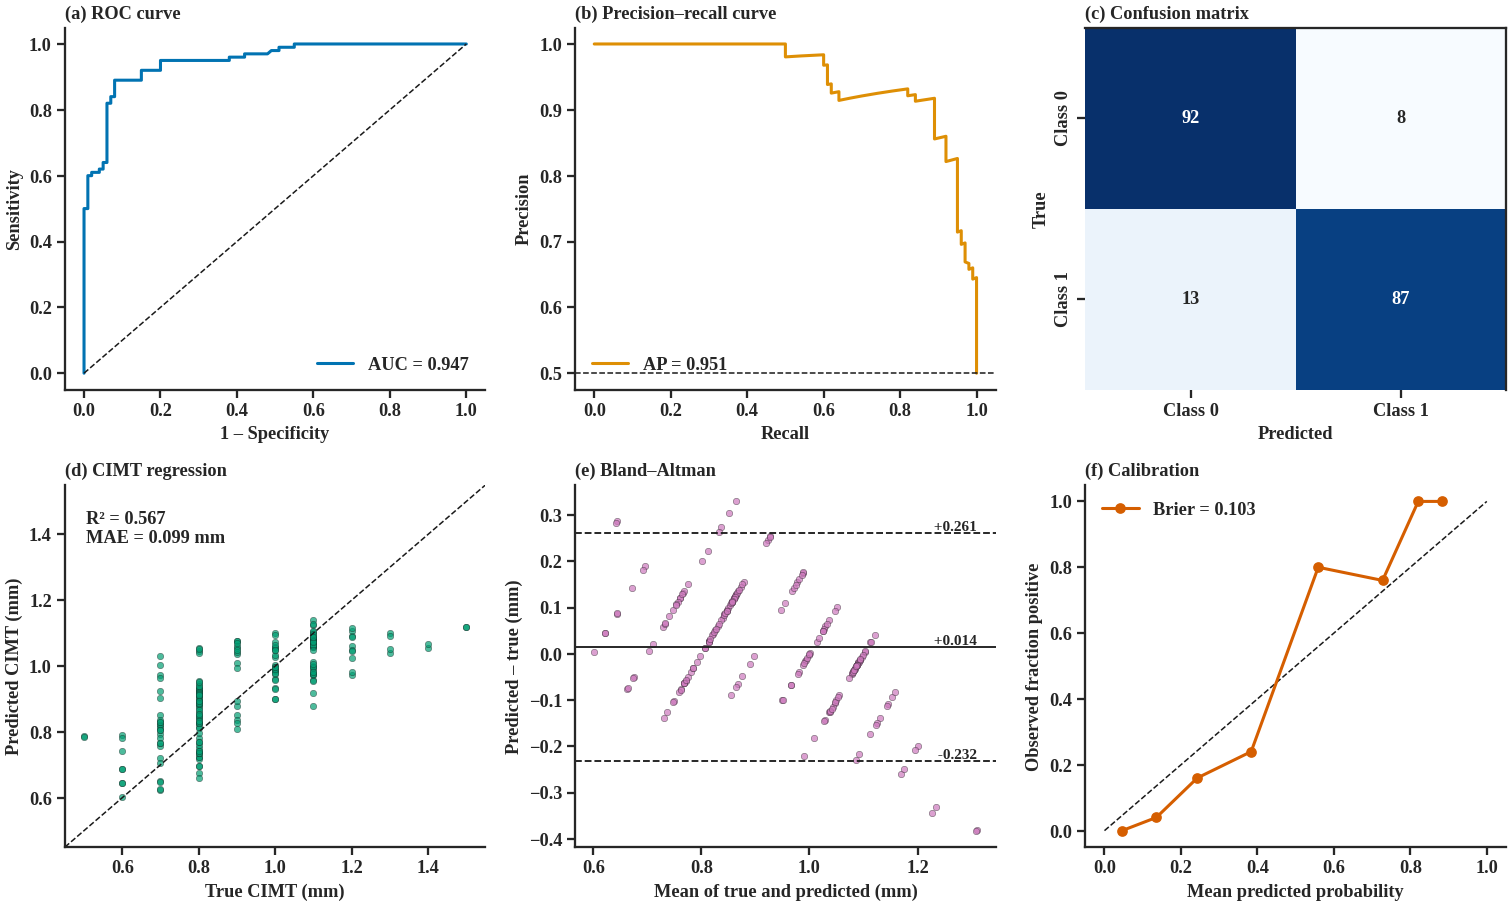

In [15]:
# ============================================================
# Fig. 3 – test performance
# ============================================================
y, p = te["label"].values, te["cls_prob"].values
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))

fpr, tpr, _ = roc_curve(y, p)
axes[0, 0].plot(fpr, tpr, color=PAL[0], label=f"AUC = {point['AUC']:.3f}")
axes[0, 0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0, 0].set_xlabel("1 – Specificity"); axes[0, 0].set_ylabel("Sensitivity"); axes[0, 0].legend(loc="lower right")
ttl(axes[0, 0], "a", "ROC curve")

pr, rc, _ = precision_recall_curve(y, p)
axes[0, 1].plot(rc, pr, color=PAL[1], label=f"AP = {point['AP']:.3f}")
axes[0, 1].axhline(y.mean(), color="k", ls="--", lw=1)
axes[0, 1].set_xlabel("Recall"); axes[0, 1].set_ylabel("Precision"); axes[0, 1].legend(loc="lower left")
ttl(axes[0, 1], "b", "Precision–recall curve")

cm = confusion_matrix(y, te["pred_label"].values, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0, 2],
            annot_kws=dict(fontsize=FS, fontweight="bold"),
            xticklabels=[CLASS_NAMES[0], CLASS_NAMES[1]], yticklabels=[CLASS_NAMES[0], CLASS_NAMES[1]])
axes[0, 2].set_xlabel("Predicted"); axes[0, 2].set_ylabel("True")
axes[0, 2].spines[["top", "right"]].set_visible(True)
ttl(axes[0, 2], "c", "Confusion matrix")

t, tp_ = te["thickness"].values, te["reg_mm"].values
axes[1, 0].scatter(t, tp_, s=18, alpha=0.7, color=PAL[2], edgecolor="k", linewidth=0.3)
lim = [min(t.min(), tp_.min()) - 0.05, max(t.max(), tp_.max()) + 0.05]
axes[1, 0].plot(lim, lim, "k--", lw=1); axes[1, 0].set_xlim(lim); axes[1, 0].set_ylim(lim)
axes[1, 0].set_xlabel("True CIMT (mm)"); axes[1, 0].set_ylabel("Predicted CIMT (mm)")
axes[1, 0].text(0.05, 0.93, f"R² = {point['R2']:.3f}\nMAE = {point['MAE (mm)']:.3f} mm", transform=axes[1, 0].transAxes,
                va="top", fontsize=FS, fontweight="bold")
ttl(axes[1, 0], "d", "CIMT regression")

mean_, diff = (t + tp_) / 2, tp_ - t
bias, sd = diff.mean(), diff.std(ddof=1)
axes[1, 1].scatter(mean_, diff, s=18, alpha=0.7, color=PAL[4], edgecolor="k", linewidth=0.3)
for v, ls in [(bias, "-"), (bias + 1.96 * sd, "--"), (bias - 1.96 * sd, "--")]:
    axes[1, 1].axhline(v, color="k", ls=ls, lw=1.2)
    axes[1, 1].text(mean_.max(), v, f" {v:+.3f}", va="bottom", ha="right", fontsize=10, fontweight="bold")
axes[1, 1].set_xlabel("Mean of true and predicted (mm)"); axes[1, 1].set_ylabel("Predicted – true (mm)")
ttl(axes[1, 1], "e", "Bland–Altman")

nb_ = 8 if len(y) >= 160 else 5
fp_, mp_ = calibration_curve(y, p, n_bins=nb_, strategy="quantile")
axes[1, 2].plot([0, 1], [0, 1], "k--", lw=1)
axes[1, 2].plot(mp_, fp_, "o-", color=PAL[3], label=f"Brier = {point['Brier']:.3f}")
axes[1, 2].set_xlabel("Mean predicted probability"); axes[1, 2].set_ylabel("Observed fraction positive")
axes[1, 2].legend(loc="upper left")
ttl(axes[1, 2], "f", "Calibration")
plt.tight_layout()
save_fig(fig, "test_performance",
         "Test-set performance. (a) ROC and (b) precision–recall curves for CIMT classification; (c) confusion matrix at the "
         "validation-selected threshold; (d) predicted vs. true CIMT; (e) Bland–Altman plot (solid = bias, dashed = ±1.96 SD); "
         "(f) calibration curve.")


## 12. Subgroup analysis (Table 5)

In [16]:
# ============================================================
# Table 5 – subgroup analysis
# ============================================================
age_cut = float(train_df[AGE_COL].median())
groups = [
    (f"{GENDER_NAMES[0]}", te["gender"] == 0), (f"{GENDER_NAMES[1]}", te["gender"] == 1),
    (f"Age ≤ {age_cut:.0f} y", te[AGE_COL] <= age_cut), (f"Age > {age_cut:.0f} y", te[AGE_COL] > age_cut),
    (CLASS_NAMES[0], te["label"] == 0), (CLASS_NAMES[1], te["label"] == 1),
]
rows = []
for name, msk in groups:
    d = te[msk.values]
    if len(d) == 0:
        continue
    two = d["label"].nunique() > 1
    rows.append({
        "Subgroup": name, "Images": len(d), "Patients": d["patient"].nunique(),
        "AUC": roc_auc_score(d["label"], d["cls_prob"]) if two else np.nan,
        "Accuracy": accuracy_score(d["label"], d["pred_label"]),
        "MAE (mm)": mean_absolute_error(d["thickness"], d["reg_mm"]),
        "Dice": d["dice"].mean(), "clDice": d["cldice"].mean(),
        "A/V Dice": d["av_mean"].mean() if d["av_mean"].notna().any() else np.nan,
    })
tab5 = pd.DataFrame(rows)
show_table(tab5, "subgroup_analysis", "Subgroup analysis on the test set.", precision=3, align="center",
           note="AUC is undefined (–) inside single-class subgroups. Age split at the training-set median.")


Subgroup,Images,Patients,AUC,Accuracy,MAE (mm),Dice,clDice,A/V Dice
Gender 0,74,37,0.895,0.851,0.104,0.931,0.954,0.915
Gender 1,126,63,0.964,0.921,0.096,0.931,0.954,0.914
Age ≤ 50 y,108,54,0.842,0.907,0.092,0.932,0.954,0.914
Age > 50 y,92,46,0.762,0.880,0.107,0.930,0.953,0.915
Class 0,100,50,–,0.920,0.106,0.931,0.954,0.913
Class 1,100,50,–,0.870,0.092,0.931,0.954,0.915


## 13. Qualitative results (Fig. 4)

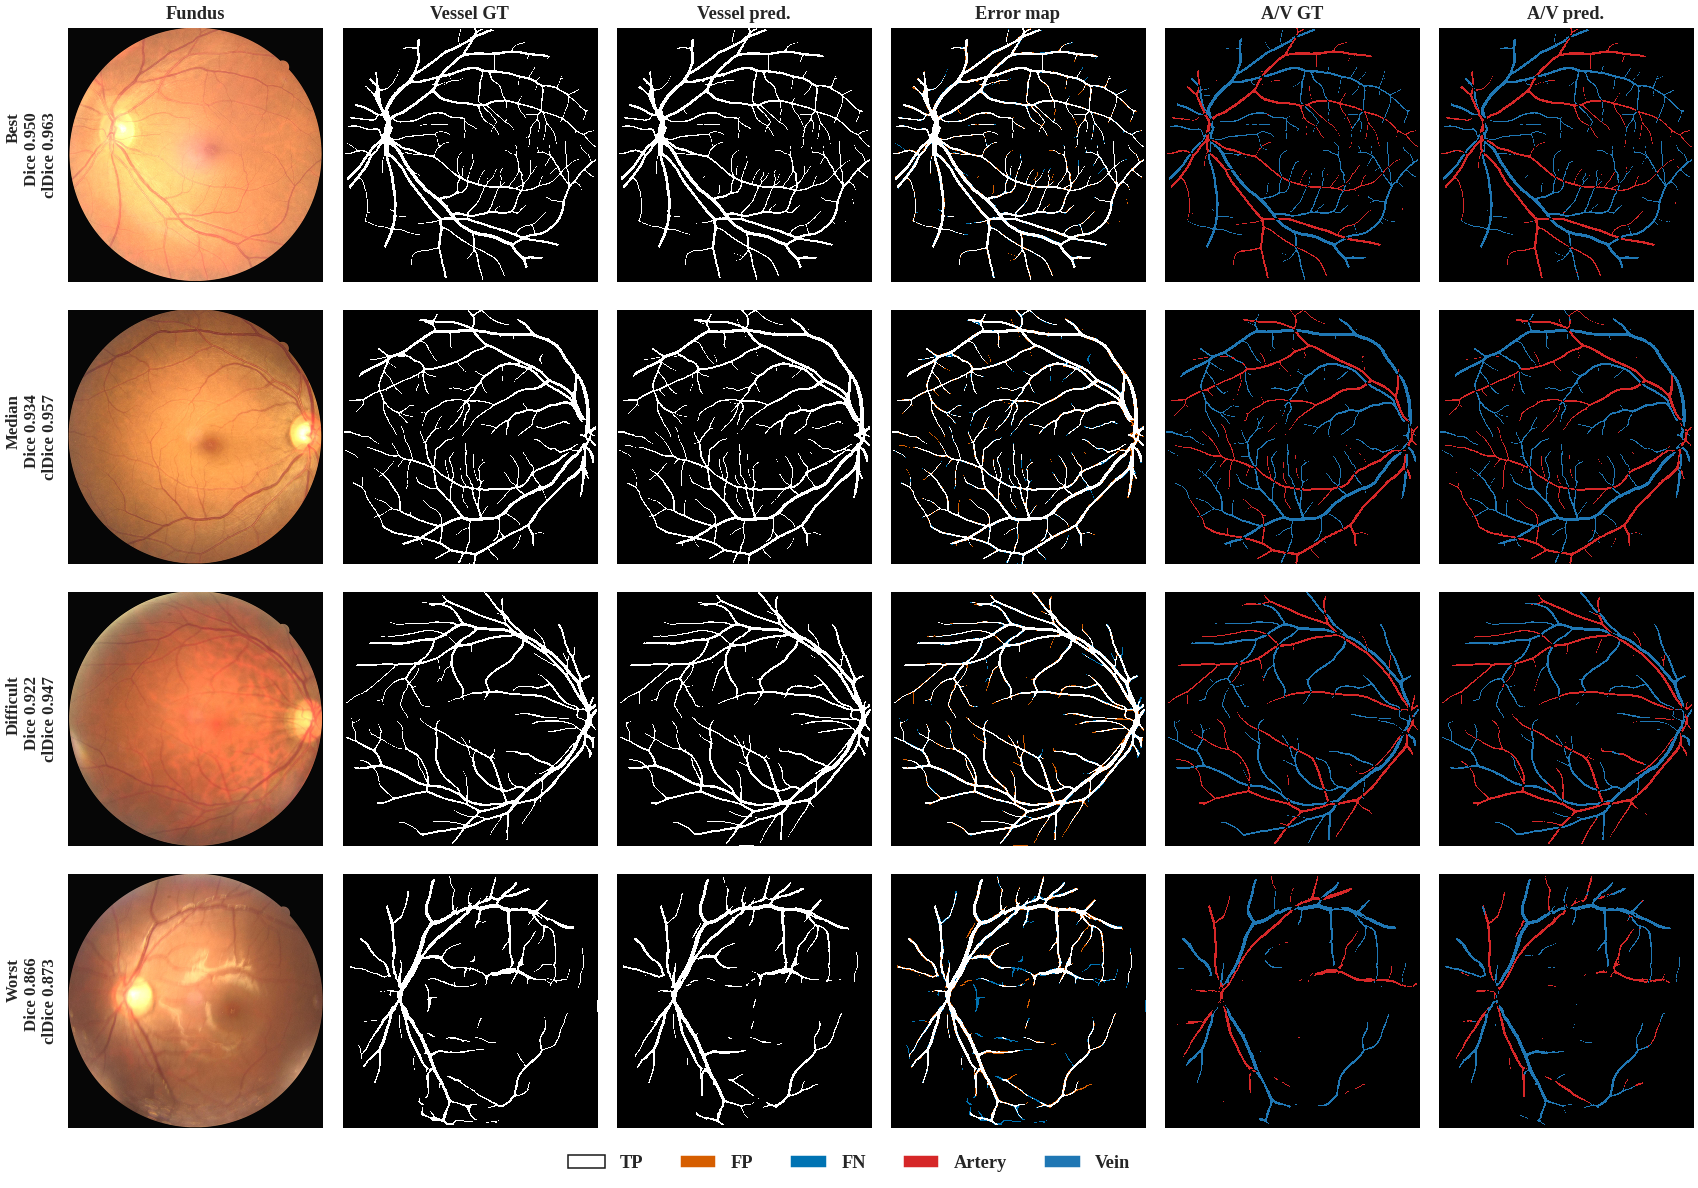

In [17]:
# ============================================================
# Fig. 4 – qualitative vessel + A/V results (best / median / difficult / worst by Dice)
# ============================================================
AV_RGB = np.array([[0, 0, 0], [214, 39, 40], [31, 119, 180]], dtype=np.uint8)   # bg, artery(red), vein(blue)

cand = te[te["has_av"]].sort_values("dice", ascending=False)
if len(cand) < 4:
    cand = te.sort_values("dice", ascending=False)
pick_pos = [0, len(cand) // 2, int(len(cand) * 0.85), len(cand) - 1]
picks = [cand.index[i] for i in pick_pos]
tags = ["Best", "Median", "Difficult", "Worst"]

fig, axes = plt.subplots(4, 6, figsize=(16, 11))
heads = ["Fundus", "Vessel GT", "Vessel pred.", "Error map", "A/V GT", "A/V pred."]
for r, (i, tg) in enumerate(zip(picks, tags)):
    img = (test_ds[i][0].permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    pm, gm = test_inf["seg"][i, 0] > 127, test_inf["gt_mask"][i, 0] > 0
    err = np.zeros((*pm.shape, 3), dtype=np.float32)
    err[pm & gm] = (1, 1, 1); err[pm & ~gm] = (0.84, 0.37, 0.0); err[~pm & gm] = (0.0, 0.45, 0.70)
    panels = [img, gm, pm, err, AV_RGB[test_inf["gt_av"][i]], AV_RGB[test_inf["av"][i]]]
    for c, pnl in enumerate(panels):
        ax = axes[r, c]
        ax.imshow(pnl, cmap="gray" if pnl.ndim == 2 else None, interpolation="nearest"); ax.axis("off")
        if r == 0:
            ax.set_title(heads[c], fontsize=FS, fontweight="bold")
    axes[r, 0].text(-0.04, 0.5, f"{tg}\nDice {te.loc[i, 'dice']:.3f}\nclDice {te.loc[i, 'cldice']:.3f}",
                    transform=axes[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=11, fontweight="bold")
    if not te.loc[i, "has_av"]:
        axes[r, 4].text(0.5, 0.5, "no A/V GT", transform=axes[r, 4].transAxes, ha="center", color="w", fontweight="bold")
leg = [Patch(fc="w", ec="k", label="TP"), Patch(fc=(0.84, 0.37, 0), label="FP"), Patch(fc=(0, 0.45, 0.70), label="FN"),
       Patch(fc=AV_RGB[1] / 255, label="Artery"), Patch(fc=AV_RGB[2] / 255, label="Vein")]
fig.legend(handles=leg, loc="lower center", ncol=5, frameon=False, fontsize=FS)
plt.tight_layout(rect=(0.02, 0.03, 1, 1))
save_fig(fig, "qualitative_results",
         "Qualitative test results for four cases ranked by Dice (best, median, difficult, worst). Columns: fundus image, vessel "
         "ground truth, vessel prediction, error map (white = TP, orange = FP, blue = FN), A/V ground truth and A/V prediction "
         "(red = artery, blue = vein).")


## 14. Topology, thin-vessel and A/V metrics (Fig. 5, Table 6)

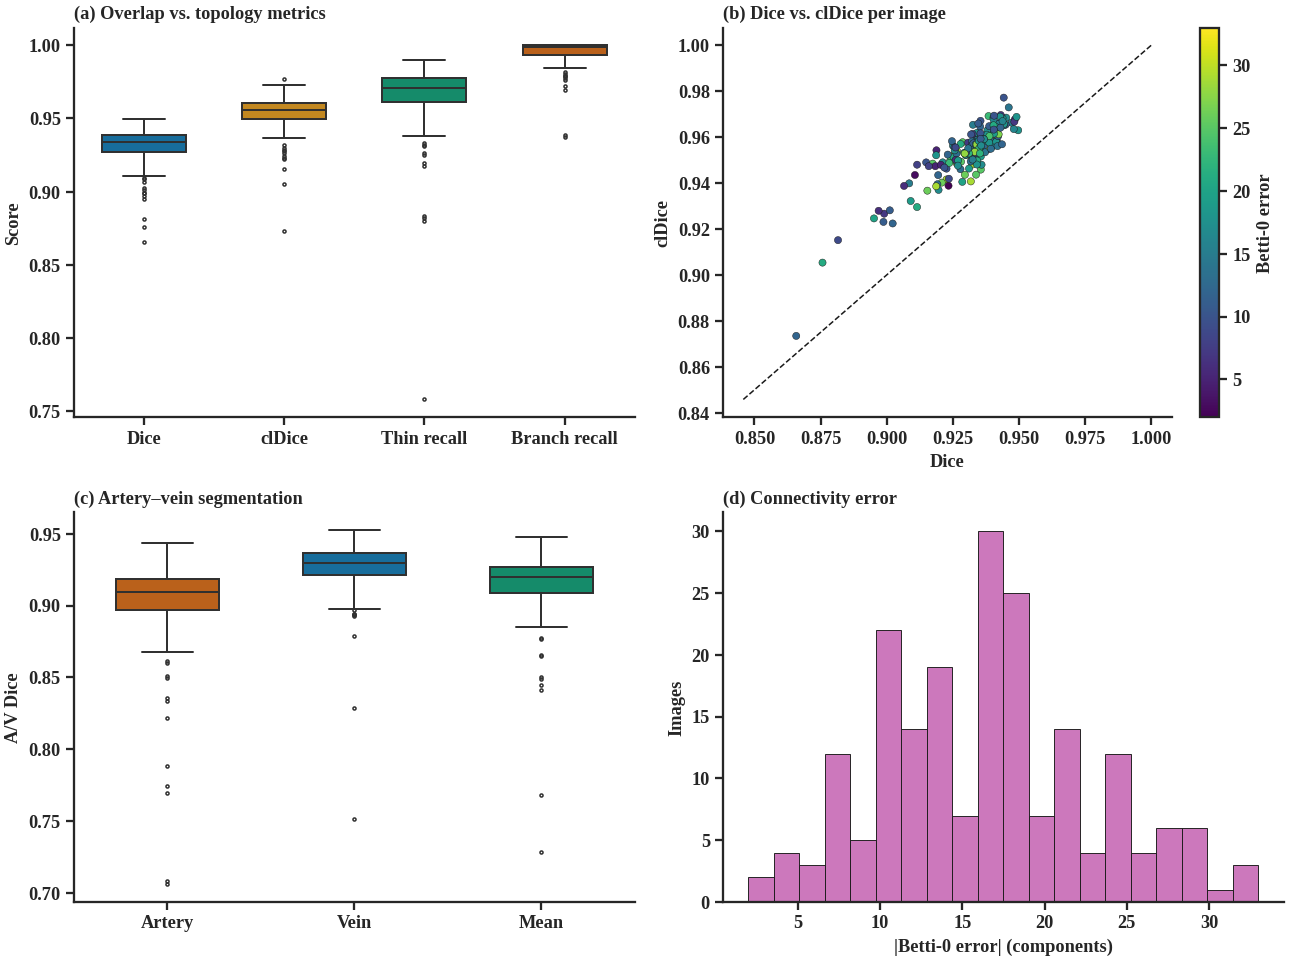

Group,Metric,Test result (95% CI)
Overlap,Dice,0.9311 (0.9288–0.9332)
Overlap,IoU,0.8713 (0.8674–0.8749)
Topology,clDice,0.954 (0.952–0.956)
Topology,Betti-0 error,16.460 (15.515–17.345)
Thin vessels / branches,Thin-vessel recall,0.9660 (0.9624–0.9690)
Thin vessels / branches,Branch-point recall,0.9957 (0.9946–0.9967)
Artery–vein,A/V Dice – artery,0.9021 (0.8968–0.9065)
Artery–vein,A/V Dice – vein,0.9264 (0.9235–0.9288)
Artery–vein,A/V Dice – mean,0.9143 (0.9104–0.9176)


In [18]:
# ============================================================
# Fig. 5 + Table 6 – topology / thin-vessel / A/V metrics
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
long = te.melt(value_vars=["dice", "cldice", "thin_recall", "branch_recall"], var_name="Metric", value_name="Value")
long["Metric"] = long["Metric"].map({"dice": "Dice", "cldice": "clDice", "thin_recall": "Thin recall", "branch_recall": "Branch recall"})
sns.boxplot(data=long, x="Metric", y="Value", palette=PAL[:4], ax=axes[0, 0], width=0.6, fliersize=2,
            linewidth=1.3)
axes[0, 0].set_xlabel(""); axes[0, 0].set_ylabel("Score"); ttl(axes[0, 0], "a", "Overlap vs. topology metrics")

sc = axes[0, 1].scatter(te["dice"], te["cldice"], c=te["betti0_err"], cmap="viridis", s=22, edgecolor="k", linewidth=0.3)
cb = plt.colorbar(sc, ax=axes[0, 1]); cb.set_label("Betti-0 error", fontweight="bold", fontsize=FS)
lo_ = min(te["dice"].min(), te["cldice"].min()) - 0.02
axes[0, 1].plot([lo_, 1], [lo_, 1], "k--", lw=1)
axes[0, 1].set_xlabel("Dice"); axes[0, 1].set_ylabel("clDice"); ttl(axes[0, 1], "b", "Dice vs. clDice per image")

av_long = te[te["has_av"]].melt(value_vars=["av_artery", "av_vein", "av_mean"], var_name="Class", value_name="Dice")
av_long["Class"] = av_long["Class"].map({"av_artery": "Artery", "av_vein": "Vein", "av_mean": "Mean"})
if len(av_long):
    sns.boxplot(data=av_long, x="Class", y="Dice", palette=[PAL[3], PAL[0], PAL[2]], ax=axes[1, 0], width=0.55,
                fliersize=2, linewidth=1.3)
axes[1, 0].set_xlabel(""); axes[1, 0].set_ylabel("A/V Dice"); ttl(axes[1, 0], "c", "Artery–vein segmentation")

axes[1, 1].hist(te["betti0_err"], bins=20, color=PAL[4], edgecolor="k", linewidth=0.6)
axes[1, 1].set_xlabel("|Betti-0 error| (components)"); axes[1, 1].set_ylabel("Images")
ttl(axes[1, 1], "d", "Connectivity error")
plt.tight_layout()
save_fig(fig, "topology_quantitative",
         "Quantitative topology analysis on the test set. (a) Dice, clDice, thin-vessel recall and branch-point recall; "
         "(b) per-image Dice vs. clDice coloured by Betti-0 error; (c) A/V Dice per class; (d) distribution of connected-component error.")

tab6 = pd.DataFrame(
    rows_for("Overlap", ["Dice", "IoU"]) +
    rows_for("Topology", ["clDice", "Betti-0 error"], d=3) +
    rows_for("Thin vessels / branches", ["Thin-vessel recall", "Branch-point recall"]) +
    rows_for("Artery–vein", ["A/V Dice – artery", "A/V Dice – vein", "A/V Dice – mean"]),
    columns=["Group", "Metric", "Test result (95% CI)"])
show_table(tab6, "topology_thin_av_metrics", "Topology, thin-vessel, branch-point and artery–vein metrics on the test set.",
           align="left",
           note="Thin vessels = GT pixels removed by a radius-2 morphological opening; branch recall = fraction of GT skeleton "
                "branch points with a predicted skeleton pixel within 3 px.")


## 15. Training curves (Fig. 6)

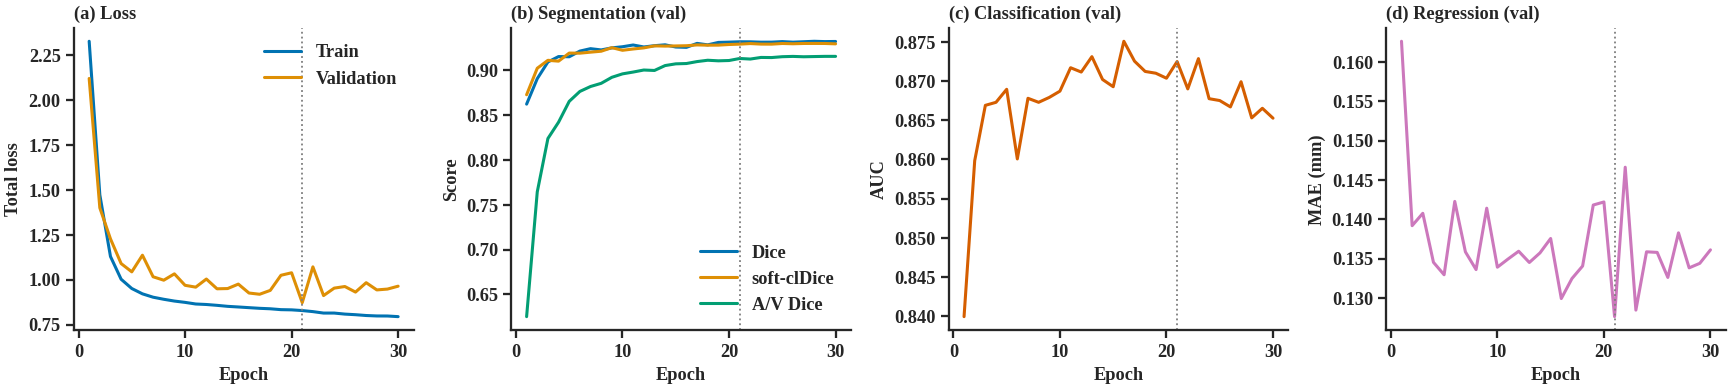

In [19]:
# ============================================================
# Fig. 6 – training curves
# ============================================================
if len(history):
    h = history
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
    axes[0].plot(h["epoch"], h["train_total"], label="Train"); axes[0].plot(h["epoch"], h["val_loss"], label="Validation")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Total loss"); axes[0].legend(); ttl(axes[0], "a", "Loss")
    axes[1].plot(h["epoch"], h["val_dice"], label="Dice"); axes[1].plot(h["epoch"], h["val_cldice"], label="soft-clDice")
    axes[1].plot(h["epoch"], h["val_av"], label="A/V Dice")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Score"); axes[1].legend(); ttl(axes[1], "b", "Segmentation (val)")
    axes[2].plot(h["epoch"], h["val_auc"], color=PAL[3]); axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("AUC")
    ttl(axes[2], "c", "Classification (val)")
    axes[3].plot(h["epoch"], h["val_mae_mm"], color=PAL[4]); axes[3].set_xlabel("Epoch"); axes[3].set_ylabel("MAE (mm)")
    ttl(axes[3], "d", "Regression (val)")
    for a in axes:
        a.axvline(int(ck["epoch"]), color="gray", ls=":", lw=1.2)
    plt.tight_layout()
    save_fig(fig, "training_curves",
             f"Training curves. (a) Total loss; (b) validation Dice, soft-clDice and A/V Dice; (c) validation AUC; "
             f"(d) validation MAE. Dotted line = selected checkpoint (epoch {int(ck['epoch'])}).")
else:
    print("No training history available (RUN_TRAINING=False and no training_history.csv) – Fig. 6 skipped.")


## 16. Q1 checklist and export

In [20]:
# ============================================================
# Q1 checklist + export
# ============================================================
n_png = len(glob.glob(os.path.join(FIG_DIR, "*.png")))
checks = [
    ("Patient-level split without overlap", len(p_tr & p_va) == 0 and len(p_tr & p_te) == 0 and len(p_va & p_te) == 0),
    ("Decision threshold chosen on validation only", True),
    ("95 % patient-level bootstrap CIs reported", len(tab4) > 0),
    ("Subgroup analysis (gender / age / class)", len(tab5) > 0),
    ("Topology + thin-vessel + A/V metrics", len(tab6) > 0),
    ("All figures exported (PNG 600 dpi + PDF + TIFF)", len(FIG_REGISTRY) >= 6 and n_png >= 6),
    ("All tables exported (CSV + LaTeX)", len(TAB_REGISTRY) >= 6),
    ("Fixed random seed", True),
]
chk = pd.DataFrame([(a, "✔" if b else "✘") for a, b in checks], columns=["Item", "Status"])
show_table(chk, "q1_checklist", "Reproducibility and reporting checklist.", align="left")

summary = pd.DataFrame([{**{k: point[k] for k in ["AUC", "Accuracy", "F1", "MAE (mm)", "R2", "Dice", "clDice",
                                                    "Thin-vessel recall", "Branch-point recall", "A/V Dice – mean"]},
                         "params_M": n_params / 1e6}],
                       index=["Attention-UNet Multi-Task + A/V (test)"])
display(summary.round(4))
summary.to_csv(os.path.join(CFG["out_dir"], "summary_test.csv"))
with open(os.path.join(CFG["out_dir"], "test_metrics_ci.json"), "w") as f:
    json.dump({k: dict(value=float(point[k]), lo=float(ci_lo[k]), hi=float(ci_hi[k])) for k in point}, f, indent=2)

zip_path = os.path.join(CFG["out_dir"], "journal_package.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for d_ in (FIG_DIR, TAB_DIR):
        for fn in sorted(os.listdir(d_)):
            z.write(os.path.join(d_, fn), os.path.join(os.path.basename(d_), fn))
    for fn in ("test_predictions.csv", "training_history.csv", "summary_test.csv", "test_metrics_ci.json"):
        fp = os.path.join(CFG["out_dir"], fn)
        if os.path.exists(fp): z.write(fp, fn)
print("Package:", zip_path, f"({os.path.getsize(zip_path) / 1e6:.1f} MB)")
for r in FIG_REGISTRY: print(r["label"], "-", r["stem"])
for r in TAB_REGISTRY: print(r["label"], "-", r["stem"])


Item,Status
Patient-level split without overlap,✔
Decision threshold chosen on validation only,✔
95 % patient-level bootstrap CIs reported,✔
Subgroup analysis (gender / age / class),✔
Topology + thin-vessel + A/V metrics,✔
All figures exported (PNG 600 dpi + PDF + TIFF),✔
All tables exported (CSV + LaTeX),✔
Fixed random seed,✔


,AUC,Accuracy,F1,MAE (mm),R2,Dice,clDice,Thin-vessel recall,Branch-point recall,A/V Dice – mean,params_M
Attention-UNet Multi-Task + A/V (test),0.9472,0.895,0.8923,0.0989,0.5668,0.9311,0.9538,0.966,0.9957,0.9143,7.923


Package: /kaggle/working/journal_package.zip (26.9 MB)
Fig. 1 - dataset_overview
Fig. 2 - architecture
Fig. 3 - test_performance
Fig. 4 - qualitative_results
Fig. 5 - topology_quantitative
Fig. 6 - training_curves
Table 1 - dataset_characteristics
Table 2 - implementation_details
Table 3 - model_complexity
Table 4 - main_test_results
Table 5 - subgroup_analysis
Table 6 - topology_thin_av_metrics
Table 7 - q1_checklist


### Summary

- **Backbone**: Attention U-Net (Oktay et al.) with attention gates on all four skip connections.
- **4 tasks**: topology-aware vessel segmentation, artery–vein segmentation, CIMT classification, CIMT regression.
- **Outputs**: 6 figures (PNG 600 dpi / PDF / TIFF), 6 tables (CSV / LaTeX), `journal_package.zip`.

---
# Extension for the Q1 journal (added cells only)

Everything above (Sections 1–16) is **unchanged**; the only addition there is Section 10a, which re-uses the checkpoint of the selected run. The cells below only *add* material and re-use the trained objects that already exist in this notebook (`model`, `te`, `point`, `ci_lo`, `ci_hi`, `THRESH`, `test_inf`, `test_loader`, `n_params` …). **Attention U-Net is the proposed model**; Swin-UNet and the other backbones are the comparison models.

| Section | Content |
|---|---|
| 17 | Cross-model comparison table (proposed Attention U-Net vs Swin-UNet, ResUNet++, DCNU-AttUNet, Standard U-Net, DeepLabV3+) and **all confusion matrices in one figure** |
| 18 | Head-to-head Attention U-Net vs Swin-UNet with 95 % CIs, differences, complexity and forest plot |
| 19 | Rank table, dot plots, accuracy–complexity trade-off |
| 20 | Pixel-level vessel metrics, A/V per-class metrics, A/V confusion matrix, pixel ROC |
| 21 | Diagnostic metrics with CI, threshold sensitivity, decision-curve analysis |
| 22 | Regression agreement (Lin's CCC, limits of agreement), patient-level performance, calibration (ECE, slope, intercept) |
| 23 | Explainability: **attention-gate maps** of the four gates + Grad-CAM for the CIMT classifier |
| 24 | Robustness to noise, brightness, contrast and blur |
| 25 | **Ablation study** (7 re-trained variants, CIs, paired bootstrap, figures; time-budgeted for 11 h, resumable) |
| 26 / 26b | Optional paired test vs Swin-UNet; limitations and extended reporting checklist |
| 27 | Extended export (figures, tables, captions, zip) |

Every figure is exported as 600 dpi PNG + PDF + TIFF and every table as CSV + LaTeX through the same `save_fig` / `show_table` helpers as before, so the numbering simply continues (Fig. 7 onward, Table 8 onward).

## 17. Cross-model comparison (proposed Attention U-Net vs. Swin-UNet and other backbones)

| Model | Backbone highlights |
|---|---|
| **Attention U-Net (this work)** | Attention gates on all four skip connections |
| Swin-UNet | Hierarchical Swin Transformer encoder–decoder |
| ResUNet++ | Residual blocks + SE + ASPP + attention gates |
| DCNU-AttUNet | Deformable conv + SPP + attention gates |
| Standard U-Net | Classic encoder–decoder (no DCN / SPP / AG) |
| DeepLabV3+ | ResNet-50 + atrous spatial pyramid pooling |

* **Attention U-Net row = measured live in this notebook** (point estimates from `point`).
* Baseline rows are the **test-set point estimates copied from their own notebooks** (identical patient-level split, 200 test images). Swin-UNet values come from its notebook outputs (Table 4 there); the four other baselines from their reported summaries.
* Classification threshold: Youden index on validation for Attention U-Net and Swin-UNet, fixed 0.5 for the remaining models (as in their notebooks).
* `–` = metric not reported by that model's notebook.

In [21]:
# ============================================================
# 17.0  Guard + cross-model comparison table
# ============================================================
_need = ["model", "te", "point", "ci_lo", "ci_hi", "THRESH", "test_inf", "test_loader", "n_params",
         "show_table", "save_fig", "ttl", "say", "safe", "pat_idx", "CFG", "FS", "PAL", "AGE_COL"]
_missing = [v for v in _need if v not in globals()]
assert not _missing, f"Run Sections 1-16 first. Missing: {_missing}"

from scipy import stats as sps
from sklearn.metrics import cohen_kappa_score

N_BOOT_X = globals().get("N_BOOT", 1000)          # bootstrap resamples used by the extension

COLS = ["Model", "Params (M)", "AUC", "Accuracy", "Sensitivity", "Specificity", "F1",
        "MAE (mm)", "RMSE (mm)", "R²", "Vessel Dice", "Vessel IoU", "clDice", "A/V mean Dice"]

PROPOSED = "Attention U-Net (this work)"
att_row = (PROPOSED, n_params / 1e6, point["AUC"], point["Accuracy"], point["Sensitivity"], point["Specificity"],
           point["F1"], point["MAE (mm)"], point["RMSE (mm)"], point["R2"], point["Dice"], point["IoU"],
           point["clDice"], point["A/V Dice – mean"])

# ---- baselines: test-set point estimates copied from their own notebooks (same split, n = 200) ----
BASELINE_ROWS = [
    #  Model          params   AUC     Acc     Se      Sp      F1      MAE     RMSE    R2      Dice    IoU     clDice  A/V
    ("Swin-UNet",     27.167, 0.9437, 0.8900, 0.8700, 0.9100, 0.8878, 0.1068, 0.1372, 0.4885, 0.9074, 0.8308, 0.9270, 0.8768),
    ("ResUNet++",      4.400, 0.9433, 0.8600, None,   None,   None,   0.1077, 0.1375, 0.4864, 0.9186, 0.8497, None,   0.9003),
    ("DCNU-AttUNet",   2.496, 0.9442, 0.8400, None,   None,   None,   0.1081, 0.1390, 0.4748, 0.9156, 0.8447, None,   0.9063),
    ("Standard U-Net",13.467, 0.9463, 0.8700, None,   None,   None,   0.1078, 0.1385, 0.4792, 0.9237, 0.8585, None,   0.8959),
    ("DeepLabV3+",    40.910, 0.9242, 0.8450, None,   None,   None,   0.1037, 0.1325, 0.5230, 0.9074, 0.8307, None,   0.8563),
]
cmp_df = pd.DataFrame([att_row] + BASELINE_ROWS, columns=COLS)
for _c in COLS[1:]:
    cmp_df[_c] = pd.to_numeric(cmp_df[_c], errors="coerce")

# ---- consistency check: live Attention U-Net vs the values quoted for it in the Swin-UNet notebook ----
_quoted = {"AUC": 0.9486, "Accuracy": 0.8850, "MAE (mm)": 0.0997, "R²": 0.5635, "Vessel Dice": 0.9310,
           "clDice": 0.9538, "A/V mean Dice": 0.9138}
for _k, _v in _quoted.items():
    _live = float(cmp_df.loc[0, _k])
    print(f"  [{'OK ' if abs(_live - _v) < 5e-4 else 'DIFF'}] {_k:14s} live = {_live:.4f} | quoted in Swin notebook = {_v:.4f}")
print("  (DIFF only means this run differs from the run quoted there, e.g. after re-training.)")

show_table(cmp_df, "cross_model_comparison",
           "Cross-model comparison on the held-out test set (200 images, patient-level split); the proposed model is Attention U-Net.",
           precision=4, align="center",
           best_max=["AUC", "Accuracy", "Sensitivity", "Specificity", "F1", "R²", "Vessel Dice", "Vessel IoU", "clDice", "A/V mean Dice"],
           best_min=["MAE (mm)", "RMSE (mm)"],
           note="Underlined = best value per column. – = not reported by that model's notebook. Threshold: Youden index on validation "
                "(Attention U-Net, Swin-UNet) or 0.5 (other models). Point estimates; see Section 18 for confidence intervals.")

print("\nBest model per metric:")
for _m, _hib in [("AUC", True), ("Accuracy", True), ("F1", True), ("MAE (mm)", False), ("RMSE (mm)", False), ("R²", True),
                 ("Vessel Dice", True), ("Vessel IoU", True), ("clDice", True), ("A/V mean Dice", True)]:
    _s = cmp_df[["Model", _m]].dropna()
    _b = _s.loc[_s[_m].idxmax() if _hib else _s[_m].idxmin()]
    print(f"  {_m:14s} -> {_b['Model']} ({_b[_m]:.4f})")

  [DIFF] AUC            live = 0.9472 | quoted in Swin notebook = 0.9486
  [DIFF] Accuracy       live = 0.8950 | quoted in Swin notebook = 0.8850
  [DIFF] MAE (mm)       live = 0.0989 | quoted in Swin notebook = 0.0997
  [DIFF] R²             live = 0.5668 | quoted in Swin notebook = 0.5635
  [OK ] Vessel Dice    live = 0.9311 | quoted in Swin notebook = 0.9310
  [OK ] clDice         live = 0.9538 | quoted in Swin notebook = 0.9538
  [OK ] A/V mean Dice  live = 0.9143 | quoted in Swin notebook = 0.9138
  (DIFF only means this run differs from the run quoted there, e.g. after re-training.)


Model,Params (M),AUC,Accuracy,Sensitivity,Specificity,F1,MAE (mm),RMSE (mm),R²,Vessel Dice,Vessel IoU,clDice,A/V mean Dice
Attention U-Net (this work),7.9230,0.9472,0.8950,0.8700,0.9200,0.8923,0.0989,0.1263,0.5668,0.9311,0.8713,0.9538,0.9143
Swin-UNet,27.1670,0.9437,0.8900,0.8700,0.9100,0.8878,0.1068,0.1372,0.4885,0.9074,0.8308,0.9270,0.8768
ResUNet++,4.4000,0.9433,0.8600,–,–,–,0.1077,0.1375,0.4864,0.9186,0.8497,–,0.9003
DCNU-AttUNet,2.4960,0.9442,0.8400,–,–,–,0.1081,0.1390,0.4748,0.9156,0.8447,–,0.9063
Standard U-Net,13.4670,0.9463,0.8700,–,–,–,0.1078,0.1385,0.4792,0.9237,0.8585,–,0.8959
DeepLabV3+,40.9100,0.9242,0.8450,–,–,–,0.1037,0.1325,0.5230,0.9074,0.8307,–,0.8563



Best model per metric:
  AUC            -> Attention U-Net (this work) (0.9472)
  Accuracy       -> Attention U-Net (this work) (0.8950)
  F1             -> Attention U-Net (this work) (0.8923)
  MAE (mm)       -> Attention U-Net (this work) (0.0989)
  RMSE (mm)      -> Attention U-Net (this work) (0.1263)
  R²             -> Attention U-Net (this work) (0.5668)
  Vessel Dice    -> Attention U-Net (this work) (0.9311)
  Vessel IoU     -> Attention U-Net (this work) (0.8713)
  clDice         -> Attention U-Net (this work) (0.9538)
  A/V mean Dice  -> Attention U-Net (this work) (0.9143)


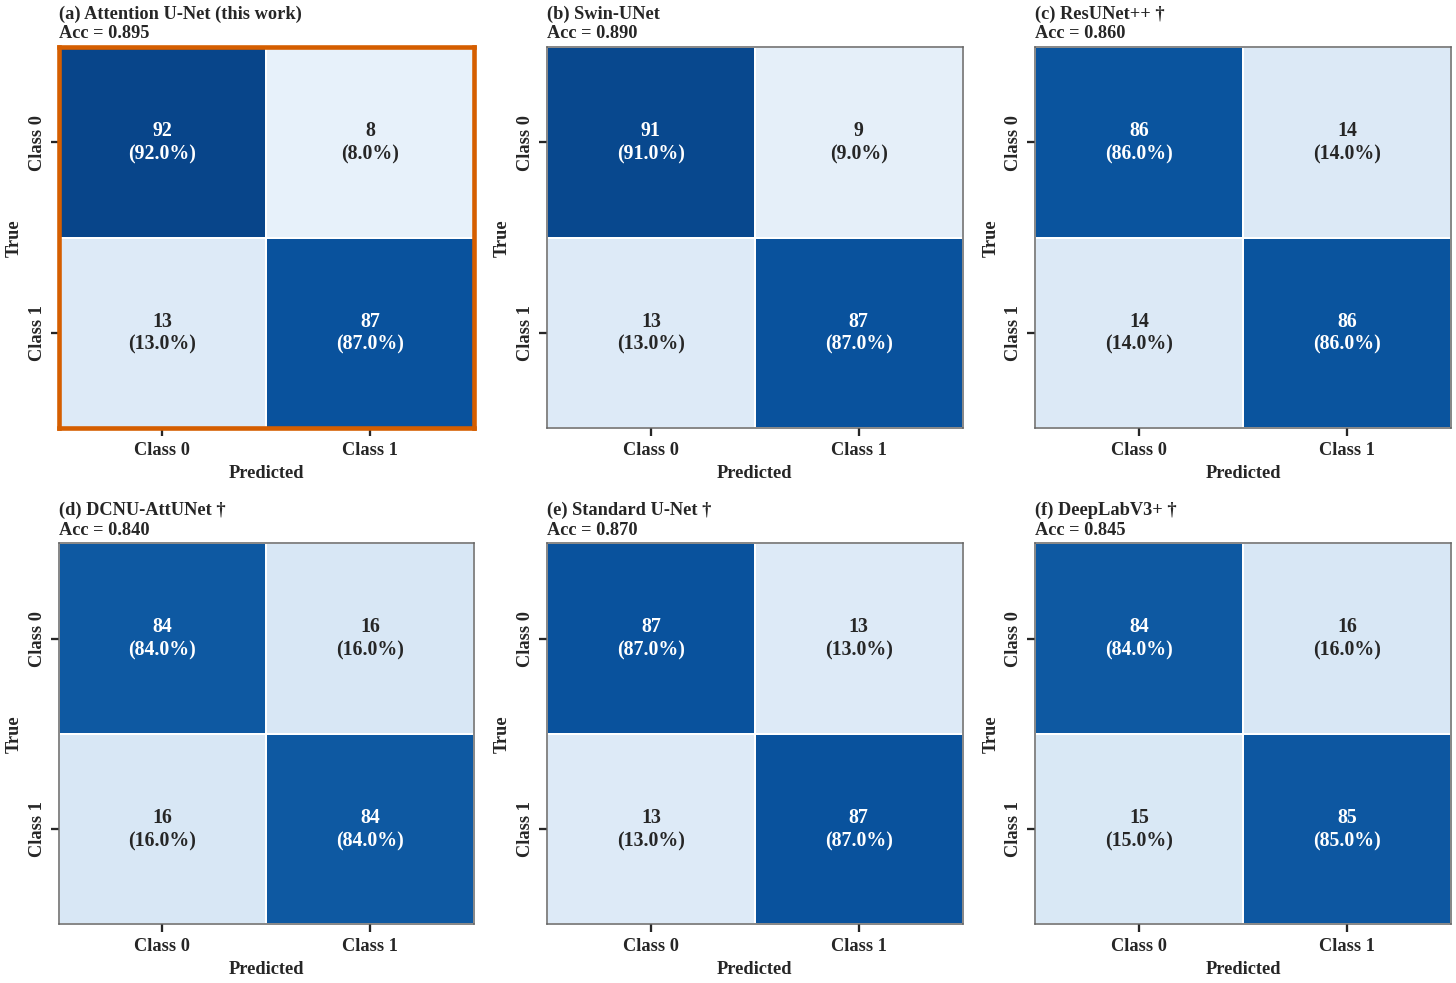

Model,TN,FP,FN,TP,Accuracy,Sensitivity,Specificity,F1,Source
Attention U-Net (this work),92,8,13,87,0.8950,0.8700,0.9200,0.8923,exact
Swin-UNet,91,9,13,87,0.8900,0.8700,0.9100,0.8878,exact
ResUNet++,86,14,14,86,0.8600,–,–,–,reconstructed †
DCNU-AttUNet,84,16,16,84,0.8400,–,–,–,reconstructed †
Standard U-Net,87,13,13,87,0.8700,–,–,–,reconstructed †
DeepLabV3+,84,16,15,85,0.8450,–,–,–,reconstructed †


In [22]:
# ============================================================
# 17.1  Confusion matrices of ALL models in ONE figure (CIMT classification, test set)
# ============================================================
with safe("confusion_all"):
    y_t = te["label"].values.astype(int)
    yh_t = te["pred_label"].values.astype(int)
    cm_att = confusion_matrix(y_t, yh_t, labels=[0, 1])                 # computed directly from this notebook
    if not np.array_equal(cm_att.sum(1), [100, 100]):
        print("[WARNING] the test set is not 100 + 100 -> the reconstructed baseline matrices below assume a balanced set.")

    # Order of every matrix: [[TN, FP], [FN, TP]]
    cms = {
        PROPOSED:                   cm_att,                                # exact (live)
        "Swin-UNet":                np.array([[91,  9], [13, 87]]),        # exact: from reported Se = 0.87, Sp = 0.91 (100 + 100)
        "ResUNet++ †":         np.array([[86, 14], [14, 86]]),        # reconstructed: Acc = 0.86 (Se = Sp assumed)
        "DCNU-AttUNet †":      np.array([[84, 16], [16, 84]]),        # reconstructed: Acc = 0.84
        "Standard U-Net †":    np.array([[87, 13], [13, 87]]),        # reconstructed: Acc = 0.87
        "DeepLabV3+ †":        np.array([[84, 16], [15, 85]]),        # reconstructed: Acc = 0.845
    }
    cls_lab = [CLASS_NAMES[0], CLASS_NAMES[1]]
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 9.2))
    for k, (ax, (name, cm_)) in enumerate(zip(axes.ravel(), cms.items())):
        pct = cm_ / np.maximum(cm_.sum(1, keepdims=True), 1) * 100
        lab = np.array([[f"{cm_[i, j]}\n({pct[i, j]:.1f}%)" for j in range(2)] for i in range(2)])
        sns.heatmap(cm_, annot=lab, fmt="", cmap="Blues", cbar=False, ax=ax, vmin=0, vmax=100,
                    annot_kws=dict(fontsize=FS + 1, fontweight="bold"),
                    xticklabels=cls_lab, yticklabels=cls_lab, linewidths=1.0, linecolor="white")
        acc_ = np.trace(cm_) / cm_.sum()
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        ax.set_title(f"({'abcdef'[k]}) {name}\nAcc = {acc_:.3f}", loc="left", fontsize=FS, fontweight="bold")
        for sp_ in ax.spines.values():
            sp_.set_visible(True); sp_.set_linewidth(3.0 if k == 0 else 1.0); sp_.set_color(PAL[3] if k == 0 else "0.4")
    plt.tight_layout()
    save_fig(fig, "confusion_matrices_all_models",
             "Confusion matrices of all six multi-task models on the held-out test set (CIMT binary classification, 100 Class 0 + 100 Class 1). "
             "Each cell shows the count and the row-wise percentage; the proposed Attention U-Net is outlined in bold orange. "
             "Attention U-Net: computed directly from this notebook's test predictions; Swin-UNet: exact, from its reported sensitivity and specificity. "
             "† Reconstructed from the reported accuracy on the balanced test set (sensitivity = specificity assumed where only accuracy was reported).")

    rows_ = []
    for name, cm_ in cms.items():
        tn, fp, fn, tp = [int(v) for v in cm_.ravel()]
        exact = ("†" not in name)
        rows_.append({"Model": name.replace(" †", ""), "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                      "Accuracy": (tp + tn) / cm_.sum(),
                      "Sensitivity": tp / (tp + fn) if exact else np.nan,
                      "Specificity": tn / (tn + fp) if exact else np.nan,
                      "F1": 2 * tp / (2 * tp + fp + fn) if exact else np.nan,
                      "Source": "exact" if exact else "reconstructed †"})
    show_table(pd.DataFrame(rows_), "confusion_counts", "Confusion-matrix counts and derived classification metrics of all models (test set).",
               precision=4, align="center", best_max=["Accuracy", "Sensitivity", "Specificity", "F1"],
               note="† reconstructed from the reported accuracy only, therefore sensitivity, specificity and F1 are not derived (–).")

## 18. Head-to-head: proposed Attention U-Net vs. Swin-UNet

Both models use the same data split, loss design, tasks and evaluation protocol, so every metric whose definition is identical in the two notebooks is compared below with **95 % patient-level bootstrap confidence intervals**. Thin-vessel recall and branch recall are *not* compared because the two notebooks define them differently (skeleton/opening-based here, width/neighbourhood-based there).

In [23]:
# ============================================================
# 18.1  Head-to-head table (Attention U-Net vs Swin-UNet) with 95 % CI and differences
# ============================================================
SWIN_CI = {   # value, lo, hi  -- Table 4 of the Swin-UNet notebook (patient-level bootstrap, 1000 resamples)
    "AUC": (0.9437, 0.8969, 0.9811), "Accuracy": (0.8900, 0.8300, 0.9450), "Sensitivity": (0.8700, 0.7778, 0.9479),
    "Specificity": (0.9100, 0.8333, 0.9792), "F1": (0.8878, 0.8243, 0.9445), "MCC": (0.7806, 0.6612, 0.8910),
    "Brier": (0.1030, 0.0720, 0.1383), "MAE (mm)": (0.1068, 0.0897, 0.1239), "RMSE (mm)": (0.1372, 0.1178, 0.1559),
    "R2": (0.4885, 0.3195, 0.5932), "Pearson r": (0.7397, 0.6777, 0.8012), "Dice": (0.9074, 0.9047, 0.9100),
    "IoU": (0.8308, 0.8264, 0.8351), "clDice": (0.9270, 0.9248, 0.9291),
    "A/V Dice – artery": (0.8606, 0.8549, 0.8654), "A/V Dice – vein": (0.8931, 0.8896, 0.8963),
    "A/V Dice – mean": (0.8768, 0.8726, 0.8809),
}
H2H = [  # (task, metric key, higher_is_better)
    ("CIMT classification", "AUC", True), ("CIMT classification", "Accuracy", True), ("CIMT classification", "Sensitivity", True),
    ("CIMT classification", "Specificity", True), ("CIMT classification", "F1", True), ("CIMT classification", "MCC", True),
    ("CIMT classification", "Brier", False),
    ("CIMT regression", "MAE (mm)", False), ("CIMT regression", "RMSE (mm)", False), ("CIMT regression", "R2", True),
    ("CIMT regression", "Pearson r", True),
    ("Vessel segmentation", "Dice", True), ("Vessel segmentation", "IoU", True), ("Vessel segmentation", "clDice", True),
    ("A/V segmentation", "A/V Dice – artery", True), ("A/V segmentation", "A/V Dice – vein", True), ("A/V segmentation", "A/V Dice – mean", True),
]
rows_ = []
for task, k, hib in H2H:
    a, alo, ahi = float(point[k]), float(ci_lo[k]), float(ci_hi[k])
    s, slo, shi = SWIN_CI[k]
    overlap = not (alo > shi or slo > ahi)
    better = "Attention U-Net" if ((a > s) == hib and a != s) else ("Swin-UNet" if a != s else "Tie")
    rows_.append({"Task": task, "Metric": k.replace("R2", "R²"),
                  "Attention U-Net (95% CI)": fmt_ci(a, alo, ahi), "Swin-UNet (95% CI)": fmt_ci(s, slo, shi),
                  "Δ (Att − Swin)": a - s, "Better": better, "CIs overlap": "yes" if overlap else "no"})
h2h = pd.DataFrame(rows_)
show_table(h2h, "head_to_head_att_vs_swin",
           "Head-to-head comparison of the proposed Attention U-Net with Swin-UNet on the test set (95% patient-level bootstrap CI).",
           precision=4, align="center",
           note="Δ = Attention U-Net − Swin-UNet (for Brier, MAE and RMSE a negative Δ favours Attention U-Net). "
                "'CIs overlap = yes' means the difference is not established by the intervals alone (200 images, 100 patients). "
                "Segmentation CIs are narrow because they describe the mean over 200 images.")

n_att = int((h2h["Better"] == "Attention U-Net").sum()); n_sw = int((h2h["Better"] == "Swin-UNet").sum())
print(f"Attention U-Net better on {n_att}/{len(h2h)} metrics, Swin-UNet on {n_sw}/{len(h2h)}.")
_clear = h2h[(h2h["CIs overlap"] == "no") & (h2h["Better"] == "Attention U-Net")]["Metric"].tolist()
print("Metrics where the 95% CIs do NOT overlap and Attention U-Net is better:", ", ".join(_clear) if _clear else "none")

# ---- complexity (as reported by each notebook) ----
_g = globals()
cx = pd.DataFrame([
    {"Model": PROPOSED, "Params (M)": n_params / 1e6,
     "Compute (as reported)": f"{_g['gmacs']:.1f} GMACs" if "gmacs" in _g and np.isfinite(_g["gmacs"]) else "–",
     "Latency (ms/img)": float(_g["lat_ms"]) if "lat_ms" in _g else np.nan, "Setting": f"512×512, batch 1, {device.type.upper()}"},
    {"Model": "Swin-UNet", "Params (M)": 27.167, "Compute (as reported)": "60.25 GFLOPs",
     "Latency (ms/img)": 46.45, "Setting": "512×512, batch 1, Tesla T4 fp32"},
])
show_table(cx, "complexity_att_vs_swin", "Model size and inference cost of the proposed Attention U-Net and Swin-UNet.",
           precision=3, align="center", best_min=["Params (M)", "Latency (ms/img)"],
           note="Compute and latency are quoted from each notebook; the FLOP counters and GPUs may differ, so treat them as indicative. "
                f"Attention U-Net has {27.167 / (n_params / 1e6):.1f}× fewer parameters than Swin-UNet.")

Task,Metric,Attention U-Net (95% CI),Swin-UNet (95% CI),Δ (Att − Swin),Better,CIs overlap
CIMT classification,AUC,0.9472 (0.9058–0.9818),0.9437 (0.8969–0.9811),0.0035,Attention U-Net,yes
CIMT classification,Accuracy,0.8950 (0.8349–0.9500),0.8900 (0.8300–0.9450),0.0050,Attention U-Net,yes
CIMT classification,Sensitivity,0.8700 (0.7700–0.9513),0.8700 (0.7778–0.9479),0.0000,Tie,yes
CIMT classification,Specificity,0.9200 (0.8431–0.9818),0.9100 (0.8333–0.9792),0.0100,Attention U-Net,yes
CIMT classification,F1,0.8923 (0.8208–0.9515),0.8878 (0.8243–0.9445),0.0045,Attention U-Net,yes
CIMT classification,MCC,0.7910 (0.6627–0.9001),0.7806 (0.6612–0.8910),0.0104,Attention U-Net,yes
CIMT classification,Brier,0.1031 (0.0772–0.1314),0.1030 (0.0720–0.1383),0.0001,Swin-UNet,yes
CIMT regression,MAE (mm),0.0989 (0.0831–0.1139),0.1068 (0.0897–0.1239),-0.0079,Attention U-Net,yes
CIMT regression,RMSE (mm),0.1263 (0.1076–0.1456),0.1372 (0.1178–0.1559),-0.0109,Attention U-Net,yes
CIMT regression,R²,0.5668 (0.4527–0.6547),0.4885 (0.3195–0.5932),0.0783,Attention U-Net,yes


Attention U-Net better on 15/17 metrics, Swin-UNet on 1/17.
Metrics where the 95% CIs do NOT overlap and Attention U-Net is better: Dice, IoU, clDice, A/V Dice – artery, A/V Dice – vein, A/V Dice – mean


Model,Params (M),Compute (as reported),Latency (ms/img),Setting
Attention U-Net (this work),7.923,49.4 GMACs,50.099,"512×512, batch 1, CUDA"
Swin-UNet,27.167,60.25 GFLOPs,46.450,"512×512, batch 1, Tesla T4 fp32"


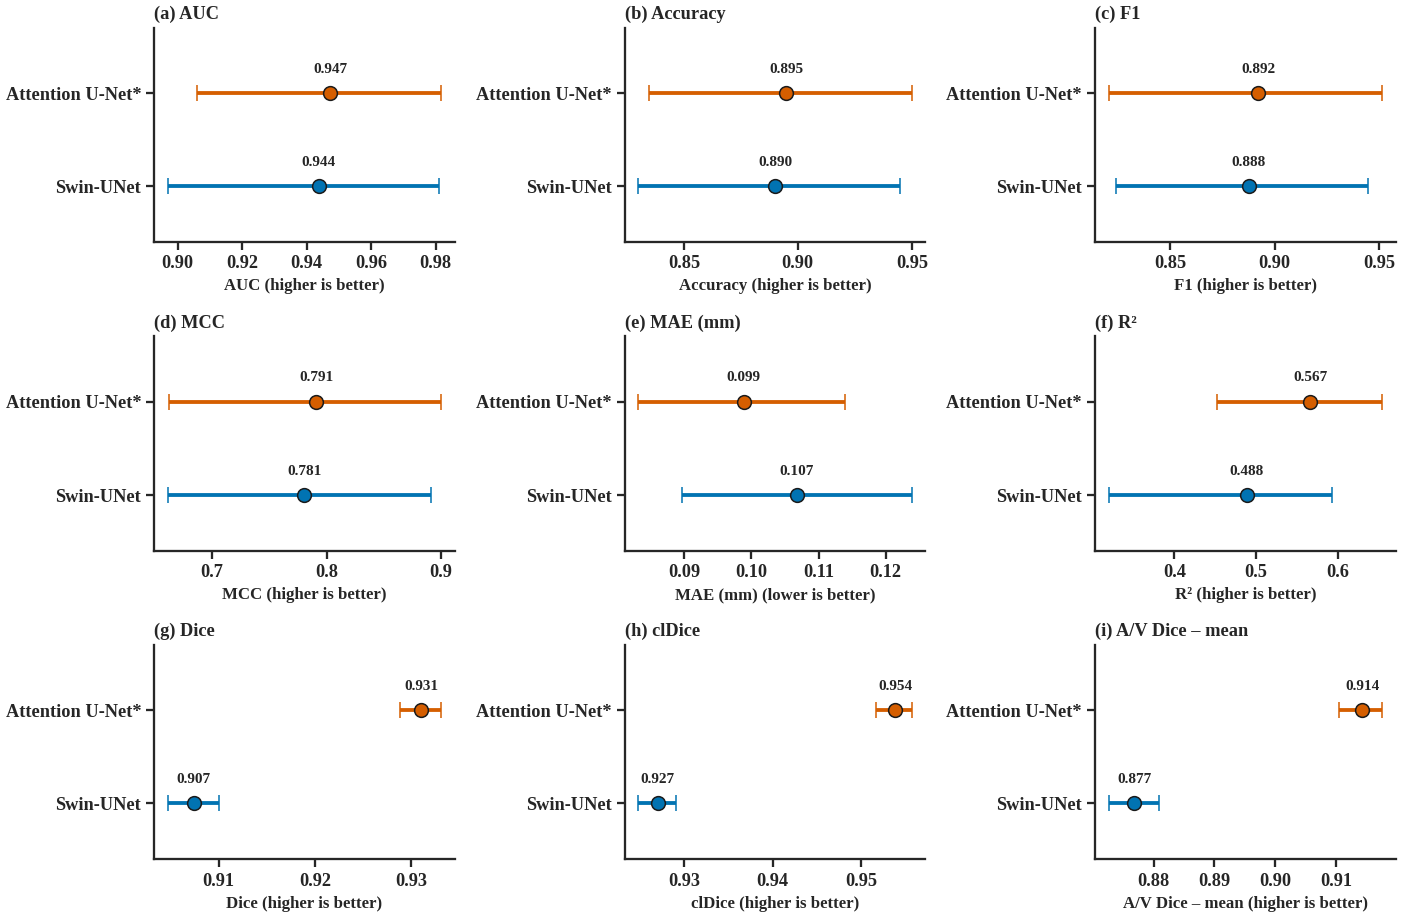

In [24]:
# ============================================================
# 18.2  Forest plot: Attention U-Net vs Swin-UNet (point estimate + 95 % CI per metric)
# ============================================================
with safe("forest_att_swin"):
    show = [("AUC", True), ("Accuracy", True), ("F1", True), ("MCC", True), ("MAE (mm)", False), ("R2", True),
            ("Dice", True), ("clDice", True), ("A/V Dice – mean", True)]
    fig, axes = plt.subplots(3, 3, figsize=(13, 8.6))
    for k_, (ax, (m, hib)) in enumerate(zip(axes.ravel(), show)):
        a, alo, ahi = float(point[m]), float(ci_lo[m]), float(ci_hi[m])
        s, slo, shi = SWIN_CI[m]
        for yy, (v, lo, hi, c, nm_) in enumerate([(s, slo, shi, PAL[0], "Swin-UNet"), (a, alo, ahi, PAL[3], "Attention U-Net*")]):
            ax.errorbar(v, yy, xerr=[[v - lo], [hi - v]], fmt="o", color=c, ecolor=c, elinewidth=2.5, capsize=5, ms=9,
                        markeredgecolor="k", zorder=3)
            ax.text(v, yy + 0.22, f"{v:.3f}", ha="center", fontsize=FS - 2)
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Swin-UNet", "Attention U-Net*"]); ax.set_ylim(-0.6, 1.7)
        ax.set_xlabel(m.replace("R2", "R²") + (" (higher is better)" if hib else " (lower is better)"), fontsize=FS - 1)
        ttl(ax, "abcdefghi"[k_], m.replace("R2", "R²"))
    plt.tight_layout()
    save_fig(fig, "forest_att_vs_swin",
             "Attention U-Net (proposed, *) versus Swin-UNet on the test set. Dots = point estimates, bars = 95% patient-level bootstrap CI. "
             "Overlapping bars indicate that the difference is not established by the intervals alone.")

## 19. Rank table, dot plots and accuracy–complexity trade-off

Model,AUC,Accuracy,R²,Vessel Dice,Vessel IoU,A/V mean Dice,MAE (mm),RMSE (mm),Mean rank,Overall
Attention U-Net (this work),1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1
Standard U-Net,2.00,3.00,5.00,2.00,2.00,4.00,5.00,5.00,3.50,2
ResUNet++,5.00,4.00,4.00,3.00,3.00,3.00,4.00,4.00,3.75,3
Swin-UNet,4.00,2.00,3.00,5.00,5.00,5.00,3.00,3.00,3.75,3
DeepLabV3+,6.00,5.00,2.00,5.00,6.00,6.00,2.00,2.00,4.25,5
DCNU-AttUNet,3.00,6.00,6.00,4.00,4.00,2.00,6.00,6.00,4.62,6


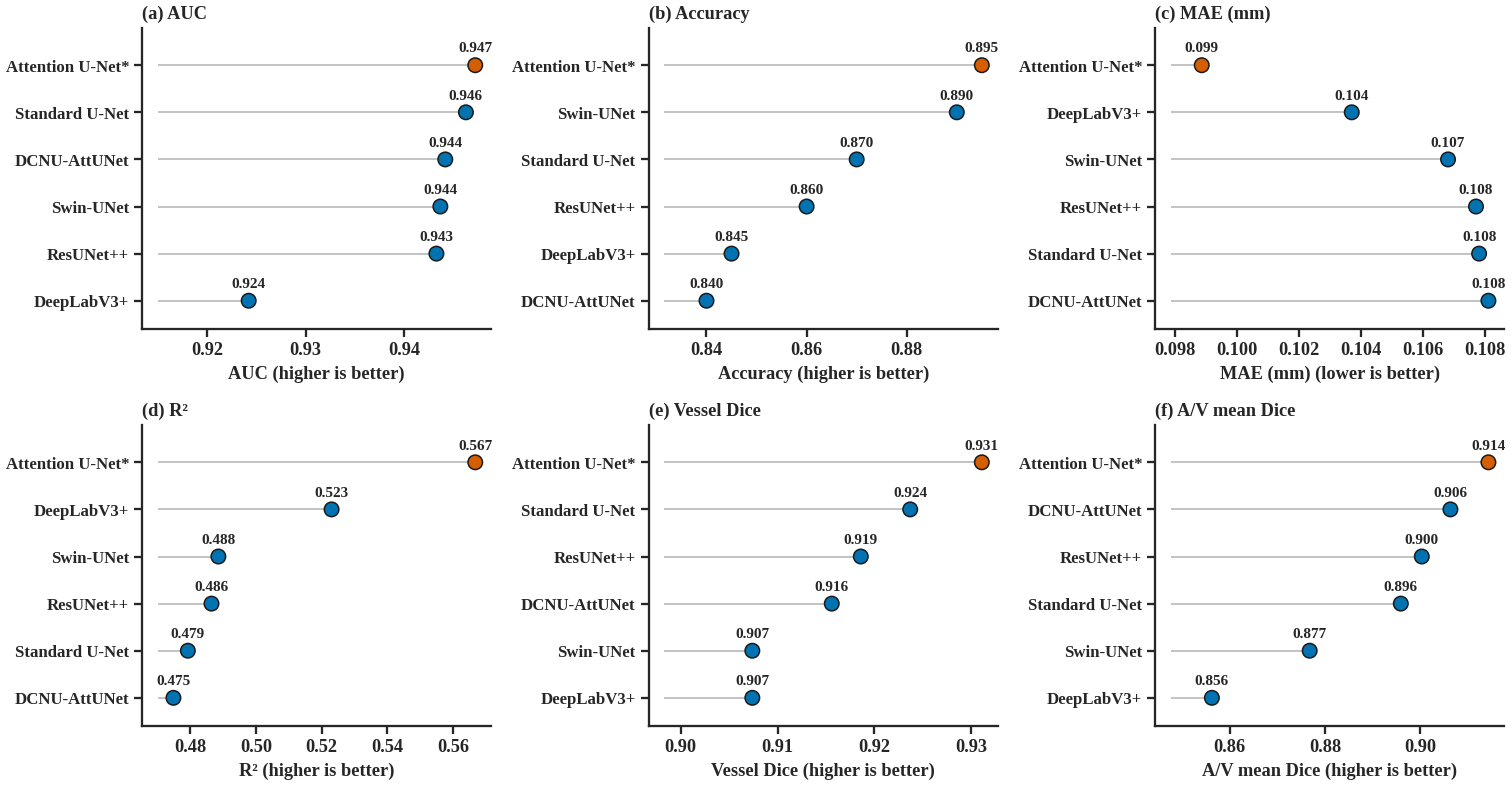

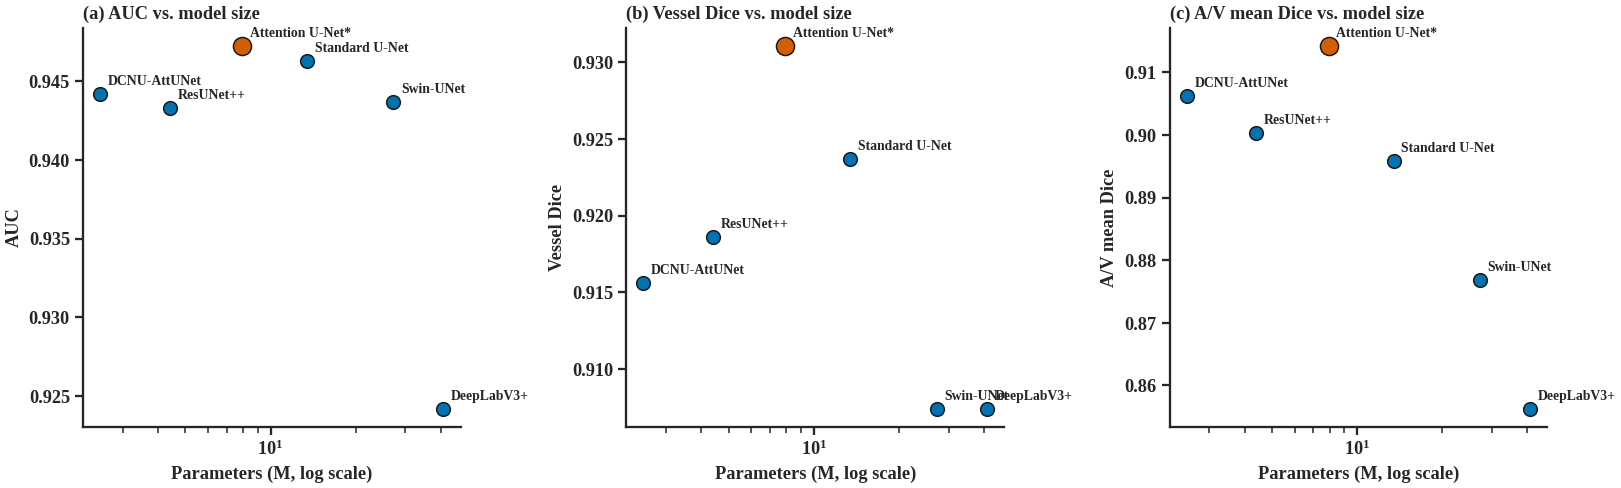

In [25]:
# ============================================================
# 19.1  Rank table + dot plots + trade-off (all six models)
# ============================================================
with safe("rank_table"):
    rank_cols = ["AUC", "Accuracy", "R²", "Vessel Dice", "Vessel IoU", "A/V mean Dice", "MAE (mm)", "RMSE (mm)"]
    rk = pd.DataFrame({"Model": cmp_df["Model"]})
    for c in rank_cols:
        rk[c] = cmp_df[c].rank(ascending=(c in ("MAE (mm)", "RMSE (mm)")), method="min")
    rk["Mean rank"] = rk[rank_cols].mean(axis=1)
    rk["Overall"] = rk["Mean rank"].rank(method="min").astype(int)
    show_table(rk.sort_values("Mean rank").reset_index(drop=True), "model_ranking",
               "Rank of each model per metric (1 = best) and mean rank over the eight metrics reported by all models.",
               precision=2, best_min=["Mean rank"],
               note="Only metrics available for every model are ranked (AUC, accuracy, R², Dice, IoU, A/V Dice, MAE, RMSE).")

with safe("dotplots"):
    mets = [("AUC", True), ("Accuracy", True), ("MAE (mm)", False), ("R²", True), ("Vessel Dice", True), ("A/V mean Dice", True)]
    fig, axes = plt.subplots(2, 3, figsize=(14, 7.4))
    for k_, (ax, (m, hib)) in enumerate(zip(axes.ravel(), mets)):
        s = cmp_df[["Model", m]].dropna().sort_values(m, ascending=not hib).reset_index(drop=True)
        yc = np.arange(len(s))[::-1]
        cols_ = [PAL[3] if "this work" in n else PAL[0] for n in s["Model"]]
        ax.hlines(yc, s[m].min() - 0.01 * abs(s[m].min()), s[m], color="0.75", lw=1.2)
        ax.scatter(s[m], yc, s=90, c=cols_, edgecolor="k", zorder=3)
        for xv, yv in zip(s[m], yc):
            ax.text(xv, yv + 0.28, f"{xv:.3f}", ha="center", fontsize=FS - 2)
        ax.set_yticks(yc); ax.set_yticklabels([n.replace(" (this work)", "*") for n in s["Model"]], fontsize=FS - 1)
        ax.set_xlabel(m + (" (higher is better)" if hib else " (lower is better)")); ax.set_ylim(-0.6, len(s) - 0.2)
        ttl(ax, "abcdef"[k_], m)
    plt.tight_layout()
    save_fig(fig, "cross_model_dotplots",
             "Cross-model comparison on the test set. Each panel shows one metric, models sorted from best (top) to worst (bottom); "
             "* = proposed Attention U-Net (orange). Dot plots are used instead of truncated bars so that small differences are not exaggerated.")

with safe("tradeoff"):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.7))
    for ax, (m, tag) in zip(axes, [("AUC", "a"), ("Vessel Dice", "b"), ("A/V mean Dice", "c")]):
        s = cmp_df[["Model", "Params (M)", m]].dropna()
        for _, r in s.iterrows():
            this = "this work" in r["Model"]
            ax.scatter(r["Params (M)"], r[m], s=140 if this else 80, color=PAL[3] if this else PAL[0], edgecolor="k", zorder=3)
            ax.annotate(r["Model"].replace(" (this work)", "*"), (r["Params (M)"], r[m]), textcoords="offset points",
                        xytext=(5, 6), fontsize=FS - 3)
        ax.set_xscale("log"); ax.set_xlabel("Parameters (M, log scale)"); ax.set_ylabel(m); ttl(ax, tag, f"{m} vs. model size")
    plt.tight_layout()
    save_fig(fig, "accuracy_vs_complexity",
             "Accuracy–complexity trade-off. (a) CIMT AUC, (b) vessel Dice and (c) A/V mean Dice versus the number of trainable parameters "
             "(logarithmic axis). * = proposed Attention U-Net.")

## 20. Pixel-level vessel metrics and artery–vein analysis

Retinal-vessel papers conventionally report pixel-level Se / Sp / Acc / AUC in addition to Dice. They are computed here from the stored test predictions (`test_inf`), pooling all test pixels (threshold 0.5).

Metric,Value
Sensitivity (recall),0.9473
Specificity,0.9908
Accuracy,0.9865
Precision,0.9179
F1-score (pixel-level Dice),0.9323
MCC,0.9250
AUC-ROC (pixel-level),0.9979


Class,Precision,Recall (Se),Dice,IoU
Background,0.9931,0.9934,0.9933,0.9866
Artery,0.9088,0.9020,0.9054,0.8272
Vein,0.9278,0.9274,0.9276,0.8649


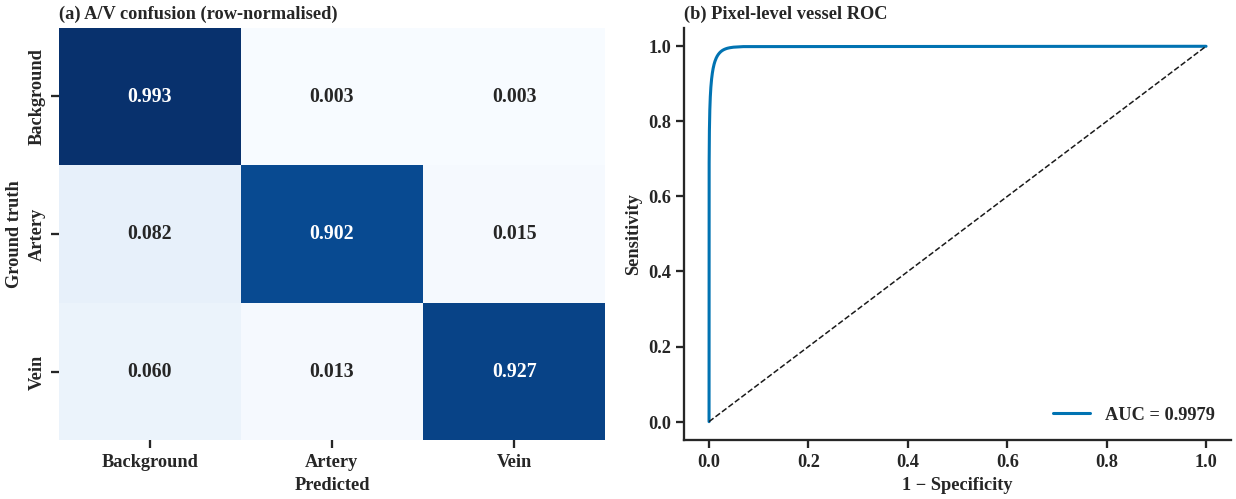

In [26]:
# ============================================================
# 20.1  Pixel-level vessel metrics, A/V per-class metrics, A/V confusion matrix, pixel ROC
# ============================================================
with safe("pixel_level"):
    seg_u8 = test_inf["seg"][:, 0]                        # (N, H, W) uint8 = probability * 255
    gt_b = test_inf["gt_mask"][:, 0] > 0
    pb = seg_u8 > 127
    tp_ = int(np.count_nonzero(pb & gt_b)); fp_ = int(np.count_nonzero(pb & ~gt_b))
    fn_ = int(np.count_nonzero(~pb & gt_b)); tn_ = int(np.count_nonzero(~pb & ~gt_b))
    pos_h = np.bincount(seg_u8[gt_b].ravel(), minlength=256).astype(np.float64)
    neg_h = np.bincount(seg_u8[~gt_b].ravel(), minlength=256).astype(np.float64)
    tpr_px = np.concatenate([[0], np.cumsum(pos_h[::-1]) / max(pos_h.sum(), 1)])
    fpr_px = np.concatenate([[0], np.cumsum(neg_h[::-1]) / max(neg_h.sum(), 1)])
    auc_px = float(np.trapezoid(tpr_px, fpr_px)) if hasattr(np, "trapezoid") else float(np.trapz(tpr_px, fpr_px))

    dv = lambda a, b: float(a / b) if b > 0 else float("nan")
    se = dv(tp_, tp_ + fn_); sp = dv(tn_, tn_ + fp_); acc = dv(tp_ + tn_, tp_ + tn_ + fp_ + fn_)
    pr_ = dv(tp_, tp_ + fp_); f1_ = dv(2 * tp_, 2 * tp_ + fp_ + fn_)
    den = float(np.sqrt(float(tp_ + fp_) * (tp_ + fn_) * (tn_ + fp_) * (tn_ + fn_)))
    mcc = dv(float(tp_) * tn_ - float(fp_) * fn_, den)
    t_px = pd.DataFrame([{"Metric": "Sensitivity (recall)", "Value": se}, {"Metric": "Specificity", "Value": sp},
                         {"Metric": "Accuracy", "Value": acc}, {"Metric": "Precision", "Value": pr_},
                         {"Metric": "F1-score (pixel-level Dice)", "Value": f1_}, {"Metric": "MCC", "Value": mcc},
                         {"Metric": "AUC-ROC (pixel-level)", "Value": auc_px}])
    show_table(t_px, "pixel_level_vessel", "Pixel-level vessel segmentation metrics on the test set (all pixels pooled).",
               precision=4, align="left",
               note="Pooled over all test pixels at the 0.5 probability threshold; AUC from a 256-bin probability histogram. "
                    "Reference = vessel masks supplied with the dataset.")

    has = test_inf["has_av"] > 0
    cm_av = np.zeros((3, 3), dtype=np.float64)
    for i in np.where(has)[0]:
        idx = (test_inf["gt_av"][i].astype(np.int64) * 3 + test_inf["av"][i].astype(np.int64)).ravel()
        cm_av += np.bincount(idx, minlength=9).reshape(3, 3)
    if cm_av.sum() > 0:
        rows_ = []
        for c in (0, 1, 2):
            tpc, fpc, fnc = cm_av[c, c], cm_av[:, c].sum() - cm_av[c, c], cm_av[c, :].sum() - cm_av[c, c]
            rows_.append({"Class": AV_CLASS_NAMES[c], "Precision": tpc / max(tpc + fpc, 1), "Recall (Se)": tpc / max(tpc + fnc, 1),
                          "Dice": 2 * tpc / max(2 * tpc + fpc + fnc, 1), "IoU": tpc / max(tpc + fpc + fnc, 1)})
        a_v = (cm_av[1, 1] + cm_av[2, 2]) / max(cm_av[1:, 1:].sum(), 1)
        show_table(pd.DataFrame(rows_), "av_per_class",
                   "Pixel-level artery–vein segmentation metrics per class (test images with A/V annotation).",
                   precision=4, best_max=["Precision", "Recall (Se)", "Dice", "IoU"],
                   note=f"Pooled pixels. Among GT vessel pixels that are predicted as a vessel, {100 * a_v:.2f}% receive the correct artery/vein class.")
        fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
        cmn = cm_av / np.maximum(cm_av.sum(1, keepdims=True), 1)
        names_ = list(AV_CLASS_NAMES.values())
        sns.heatmap(cmn, annot=True, fmt=".3f", cmap="Blues", cbar=False, vmin=0, vmax=1, ax=axes[0],
                    annot_kws=dict(fontsize=FS + 1, fontweight="bold"), xticklabels=names_, yticklabels=names_)
        axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Ground truth"); ttl(axes[0], "a", "A/V confusion (row-normalised)")
        axes[1].plot(fpr_px, tpr_px, color=PAL[0], label=f"AUC = {auc_px:.4f}")
        axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_xlabel("1 − Specificity"); axes[1].set_ylabel("Sensitivity")
        axes[1].legend(loc="lower right"); ttl(axes[1], "b", "Pixel-level vessel ROC")
        plt.tight_layout()
        save_fig(fig, "av_confusion_pixel_roc",
                 "(a) Row-normalised pixel confusion matrix of the artery–vein map (background / artery / vein). "
                 "(b) Pixel-level ROC curve of the vessel head on the test set.")
    del seg_u8, gt_b, pb

## 21. CIMT classification: diagnostic metrics, threshold sensitivity, decision curve

Metric,Estimate (95% CI)
Sensitivity,0.870 (0.770–0.951)
Specificity,0.920 (0.843–0.982)
PPV,0.916 (0.836–0.981)
NPV,0.876 (0.782–0.956)
Balanced accuracy,0.895 (0.831–0.950)
Cohen's kappa,0.790 (0.660–0.899)
LR+,10.875 (5.500–48.499)
LR−,0.141 (0.052–0.254)


Threshold,Sensitivity,Specificity,Accuracy,PPV,NPV,F1,Youden J
0.300,0.950,0.660,0.805,0.736,0.930,0.830,0.610
0.400,0.920,0.850,0.885,0.860,0.914,0.889,0.770
0.500,0.880,0.920,0.900,0.917,0.885,0.898,0.800
0.514,0.870,0.920,0.895,0.916,0.876,0.892,0.790
0.600,0.750,0.940,0.845,0.926,0.790,0.829,0.690
0.700,0.620,0.950,0.785,0.925,0.714,0.743,0.570
0.800,0.480,1.000,0.740,1.000,0.658,0.649,0.480


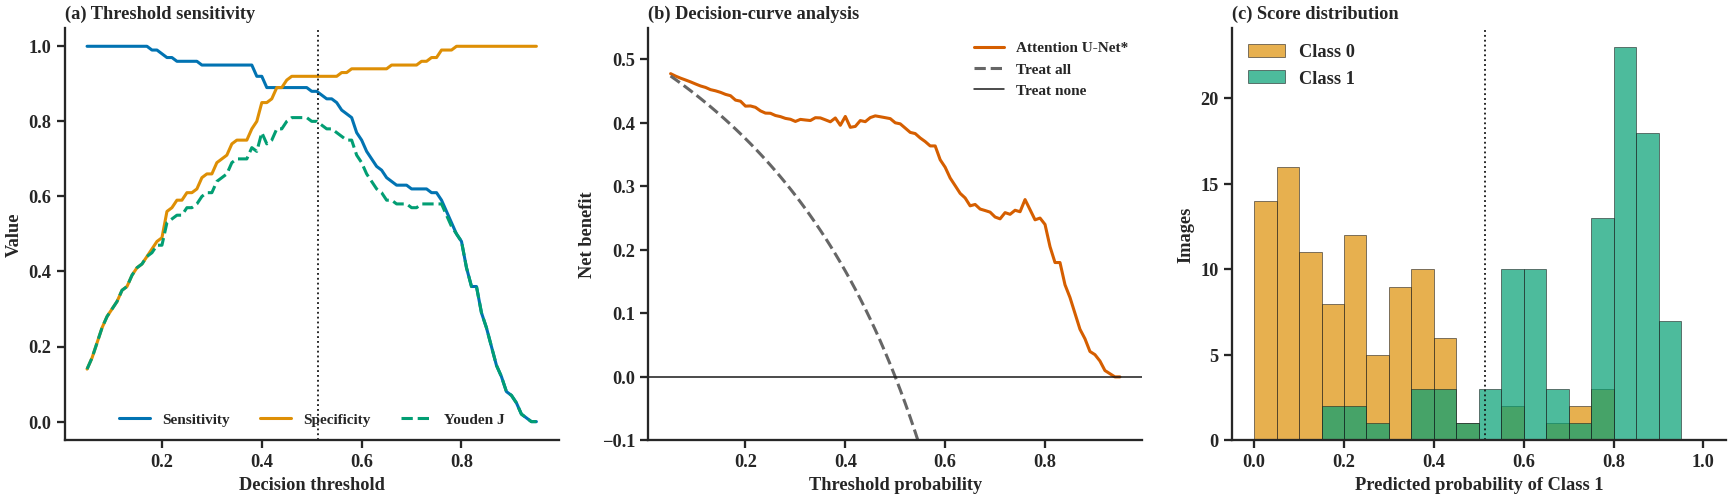

In [27]:
# ============================================================
# 21.1  Diagnostic metrics with patient-level bootstrap CI + threshold sensitivity
# ============================================================
y_te = te["label"].values.astype(int)
p_te = te["cls_prob"].values
pat_te = te["patient"].values

def cboot(fn, B=None, seed=None):
    # patient-level (cluster) bootstrap -> {metric: (point, lo, hi)}
    B = B or N_BOOT_X; rng = np.random.default_rng(seed or CFG["seed"])
    pt = fn(np.arange(len(te))); draws = {k: [] for k in pt}
    for _ in range(B):
        pick = rng.integers(0, len(pat_idx), len(pat_idx))
        try:
            r = fn(np.concatenate([pat_idx[k] for k in pick]))
        except Exception:
            continue
        for k, v in r.items():
            draws[k].append(v)
    out = {}
    for k, v in pt.items():
        a = np.asarray(draws[k], dtype=float)
        out[k] = (v, np.nanpercentile(a, 2.5), np.nanpercentile(a, 97.5)) if np.isfinite(a).any() else (v, np.nan, np.nan)
    return out

with safe("diagnostic_table"):
    def _diag(idx):
        yy, pp = y_te[idx], p_te[idx]; yh = (pp >= THRESH).astype(int)
        tn, fp, fn, tp = confusion_matrix(yy, yh, labels=[0, 1]).ravel()
        se, sp = tp / max(tp + fn, 1), tn / max(tn + fp, 1)
        kap = float(cohen_kappa_score(yy, yh)) if len(np.unique(yh)) > 1 and len(np.unique(yy)) > 1 else 0.0
        return {"Sensitivity": se, "Specificity": sp, "PPV": tp / max(tp + fp, 1), "NPV": tn / max(tn + fn, 1),
                "Balanced accuracy": (se + sp) / 2, "Cohen's kappa": kap,
                "LR+": se / max(1 - sp, 1e-6), "LR−": (1 - se) / max(sp, 1e-6)}
    bd = cboot(_diag)
    show_table(pd.DataFrame([{"Metric": k, "Estimate (95% CI)": fmt_ci(*v, d=3)} for k, v in bd.items()]), "diagnostic_metrics",
               "Diagnostic performance of the CIMT classifier at the validation-selected threshold (patient-level bootstrap, 95% CI).",
               align="left", note=f"Threshold = {THRESH:.3f}. PPV / NPV depend on the class prevalence of the test set ({100 * y_te.mean():.1f}% Class 1). "
                                  "LR+ / LR− = positive / negative likelihood ratio.")

    thr_list = sorted(set([round(t, 2) for t in np.arange(0.3, 0.81, 0.1)] + [0.5, round(THRESH, 3)]))
    rows_ = []
    for t in thr_list:
        yh = (p_te >= t).astype(int); tn, fp, fn, tp = confusion_matrix(y_te, yh, labels=[0, 1]).ravel()
        se, sp = tp / max(tp + fn, 1), tn / max(tn + fp, 1); pr = tp / max(tp + fp, 1)
        rows_.append({"Threshold": t, "Sensitivity": se, "Specificity": sp, "Accuracy": (tp + tn) / len(y_te), "PPV": pr,
                      "NPV": tn / max(tn + fn, 1), "F1": 2 * pr * se / max(pr + se, 1e-12), "Youden J": se + sp - 1})
    show_table(pd.DataFrame(rows_), "threshold_sensitivity", "Effect of the decision threshold on the CIMT classification metrics (test set).",
               precision=3, best_max=["Youden J", "F1"],
               note=f"The threshold used throughout the paper ({THRESH:.3f}) was fixed on the validation set, not tuned on the test set.")

with safe("decision_curve"):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    ts = np.linspace(0.05, 0.95, 91)
    se_c = [((p_te >= t) & (y_te == 1)).sum() / max((y_te == 1).sum(), 1) for t in ts]
    sp_c = [((p_te < t) & (y_te == 0)).sum() / max((y_te == 0).sum(), 1) for t in ts]
    axes[0].plot(ts, se_c, color=PAL[0], label="Sensitivity"); axes[0].plot(ts, sp_c, color=PAL[1], label="Specificity")
    axes[0].plot(ts, np.array(se_c) + np.array(sp_c) - 1, color=PAL[2], ls="--", label="Youden J")
    axes[0].axvline(THRESH, color="k", ls=":", lw=1.2); axes[0].set_xlabel("Decision threshold"); axes[0].set_ylabel("Value")
    axes[0].legend(loc="lower center", ncol=3, fontsize=FS - 2); ttl(axes[0], "a", "Threshold sensitivity")

    n_, prev = len(y_te), y_te.mean()
    nb_model, nb_all = [], []
    for t in ts:
        w = t / (1 - t); yh = p_te >= t
        tp = ((yh) & (y_te == 1)).sum(); fp = ((yh) & (y_te == 0)).sum()
        nb_model.append(tp / n_ - fp / n_ * w); nb_all.append(prev - (1 - prev) * w)
    axes[1].plot(ts, nb_model, color=PAL[3], label="Attention U-Net*"); axes[1].plot(ts, nb_all, color="0.4", ls="--", label="Treat all")
    axes[1].axhline(0, color="k", lw=1, label="Treat none"); axes[1].set_ylim(-0.1, prev + 0.05)
    axes[1].set_xlabel("Threshold probability"); axes[1].set_ylabel("Net benefit"); axes[1].legend(loc="upper right", fontsize=FS - 2)
    ttl(axes[1], "b", "Decision-curve analysis")

    for lab_, col in [(0, PAL[1]), (1, PAL[2])]:
        axes[2].hist(p_te[y_te == lab_], bins=20, range=(0, 1), alpha=0.7, color=col, edgecolor="k", linewidth=0.5, label=CLASS_NAMES[lab_])
    axes[2].axvline(THRESH, color="k", ls=":", lw=1.2); axes[2].set_xlabel("Predicted probability of Class 1"); axes[2].set_ylabel("Images")
    axes[2].legend(); ttl(axes[2], "c", "Score distribution")
    plt.tight_layout()
    save_fig(fig, "diagnostic_threshold_dca",
             "(a) Sensitivity, specificity and Youden J versus decision threshold (dotted line = validation-selected threshold). "
             "(b) Decision-curve analysis: net benefit of the proposed Attention U-Net against treat-all / treat-none strategies. "
             "(c) Distribution of predicted probabilities by true class.")

## 22. Agreement, patient-level performance and calibration

In [28]:
# ============================================================
# 22.1  Regression agreement (Lin's CCC, limits of agreement), eye- vs patient-level, calibration
# ============================================================
with safe("agreement_calibration"):
    tt_te = te["thickness"].values.astype(float); tp_te = te["reg_mm"].values.astype(float)

    def _ccc(a, b):
        va, vb = np.var(a), np.var(b); cov = np.mean((a - a.mean()) * (b - b.mean()))
        return 2 * cov / (va + vb + (a.mean() - b.mean()) ** 2)

    def _agree(idx):
        t, p = tt_te[idx], tp_te[idx]; d = p - t
        return {"Lin's CCC": _ccc(t, p), "Bias (mm)": d.mean(), "SD of differences (mm)": d.std(ddof=1),
                "Lower LoA (mm)": d.mean() - 1.96 * d.std(ddof=1), "Upper LoA (mm)": d.mean() + 1.96 * d.std(ddof=1),
                "Within ±0.10 mm (%)": 100 * np.mean(np.abs(d) <= 0.10), "Within ±0.20 mm (%)": 100 * np.mean(np.abs(d) <= 0.20)}
    ag = cboot(_agree)
    show_table(pd.DataFrame([{"Metric": k, "Estimate (95% CI)": fmt_ci(*v, d=3)} for k, v in ag.items()]), "regression_agreement",
               "Agreement between predicted and reference CIMT (patient-level bootstrap, 95% CI).", align="left",
               note="LoA = 95% limits of agreement (bias ± 1.96 SD). Lin's CCC combines correlation and absolute agreement.")

    # ---- eye-level vs patient-level (both eyes averaged) ----
    g = te.assign(_y=y_te, _p=p_te, _t=tt_te, _r=tp_te).groupby("patient")
    pl = pd.DataFrame({"y": g["_y"].mean().round().astype(int), "p": g["_p"].mean(), "t": g["_t"].mean(), "r": g["_r"].mean()})
    yh_p = (pl["p"].values >= THRESH).astype(int)
    two = len(np.unique(pl["y"])) > 1
    tn, fp, fn, tp = confusion_matrix(pl["y"].values, yh_p, labels=[0, 1]).ravel()
    lvl = pd.DataFrame([
        {"Level": "Eye (image)", "n": len(te), "AUC": point["AUC"], "Accuracy": point["Accuracy"], "Sensitivity": point["Sensitivity"],
         "Specificity": point["Specificity"], "MAE (mm)": point["MAE (mm)"], "R²": point["R2"]},
        {"Level": "Patient (eyes averaged)", "n": len(pl), "AUC": roc_auc_score(pl["y"], pl["p"]) if two else np.nan,
         "Accuracy": (tp + tn) / len(pl), "Sensitivity": tp / max(tp + fn, 1), "Specificity": tn / max(tn + fp, 1),
         "MAE (mm)": float(np.abs(pl["r"] - pl["t"]).mean()), "R²": r2_score(pl["t"], pl["r"])},
    ])
    show_table(lvl, "eye_vs_patient_level", "CIMT performance at eye level and at patient level (probabilities and thickness averaged over both eyes).",
               precision=4, align="center",
               note="Patient-level labels are the rounded mean of the two eye labels; the threshold is the same validation-selected value.")

    # ---- calibration ----
    from sklearn.linear_model import LogisticRegression
    pc = np.clip(p_te, 1e-4, 1 - 1e-4); logit = np.log(pc / (1 - pc)).reshape(-1, 1)
    lr = LogisticRegression(C=1e6, solver="lbfgs", max_iter=1000).fit(logit, y_te)
    slope, interc = float(lr.coef_[0, 0]), float(lr.intercept_[0])
    edges = np.quantile(p_te, np.linspace(0, 1, 9)); edges[0], edges[-1] = 0, 1
    bin_id = np.clip(np.digitize(p_te, edges[1:-1]), 0, 6)
    ece = float(sum(abs(p_te[bin_id == b].mean() - y_te[bin_id == b].mean()) * (bin_id == b).mean() for b in np.unique(bin_id)))
    cal = pd.DataFrame([{"Metric": "Brier score", "Value": point["Brier"]}, {"Metric": "Expected calibration error (8 quantile bins)", "Value": ece},
                        {"Metric": "Calibration slope (ideal 1)", "Value": slope}, {"Metric": "Calibration intercept (ideal 0)", "Value": interc}])
    show_table(cal, "calibration_metrics", "Calibration of the CIMT classifier on the test set.", precision=4, align="left",
               note="Slope and intercept from a logistic regression of the true class on the logit of the predicted probability.")

Metric,Estimate (95% CI)
Lin's CCC,0.709 (0.631–0.776)
Bias (mm),0.014 (-0.011–0.042)
SD of differences (mm),0.126 (0.106–0.145)
Lower LoA (mm),-0.232 (-0.281–-0.181)
Upper LoA (mm),0.261 (0.219–0.300)
Within ±0.10 mm (%),57.000 (48.000–66.512)
Within ±0.20 mm (%),89.000 (83.000–94.500)


Level,n,AUC,Accuracy,Sensitivity,Specificity,MAE (mm),R²
Eye (image),200,0.9472,0.8950,0.8700,0.9200,0.0989,0.5668
Patient (eyes averaged),100,0.9496,0.9000,0.8800,0.9200,0.0988,0.5696


Metric,Value
Brier score,0.1031
Expected calibration error (8 quantile bins),0.1172
Calibration slope (ideal 1),1.9602
Calibration intercept (ideal 0),0.2400


## 23. Explainability: attention-gate maps and Grad-CAM

* **Attention-gate maps** — the four attention gates (`att1` … `att4`, full resolution → coarsest) produce a coefficient map α ∈ [0, 1] that re-weights the encoder skip features. They are captured with forward hooks, so the model itself is not modified.
* **Grad-CAM** — class-activation map of the CIMT classifier computed on the bottleneck feature map.

Cases shown: the most confident true positive, the most confident true negative, the most confident false positive and the most confident false negative (when they exist).

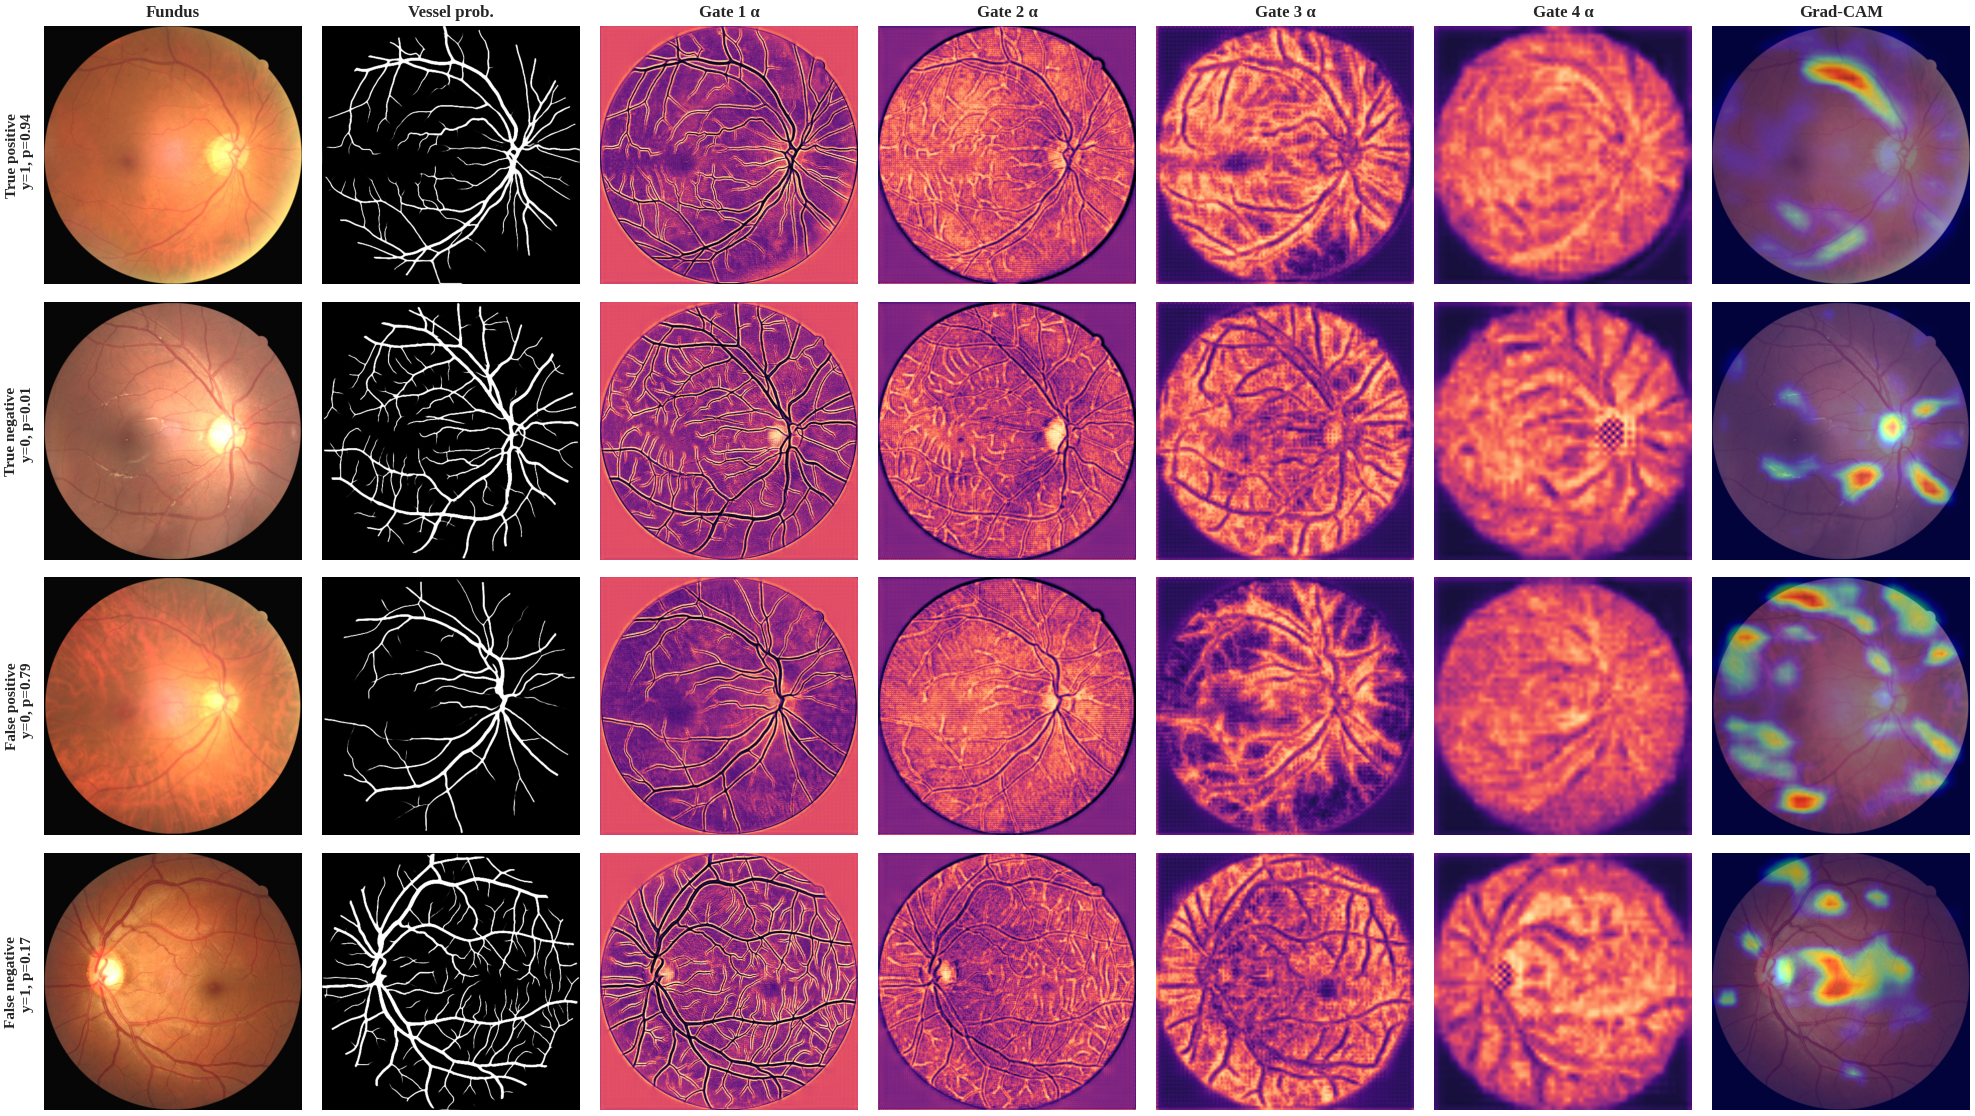

Region,Mean α (gate 1)
Vessel pixels (GT),0.2312
Background pixels,0.5237


In [29]:
# ============================================================
# 23.1  Attention-gate maps (forward hooks) + Grad-CAM of the CIMT classifier
# ============================================================
with safe("attention_gradcam"):
    y_all, p_all, yh_all = te["label"].values.astype(int), te["cls_prob"].values, te["pred_label"].values.astype(int)
    def _pick(mask, largest=True):
        ids = np.where(mask)[0]
        return None if len(ids) == 0 else int(ids[np.argmax(p_all[ids]) if largest else np.argmin(p_all[ids])])
    picks = [("True positive", _pick((y_all == 1) & (yh_all == 1), True)), ("True negative", _pick((y_all == 0) & (yh_all == 0), False)),
             ("False positive", _pick((y_all == 0) & (yh_all == 1), True)), ("False negative", _pick((y_all == 1) & (yh_all == 0), False))]
    picks = [(n, i) for n, i in picks if i is not None]

    cap, act = {}, {}
    gates = [model.att1, model.att2, model.att3, model.att4]
    hooks = [g_.register_forward_hook(lambda m_, i_, o_, k=k: cap.__setitem__(k, o_[1].detach().float().cpu())) for k, g_ in enumerate(gates)]
    def _bn_hook(m_, i_, o_):
        act["a"] = o_; o_.register_hook(lambda gr: act.__setitem__("g", gr))
    hooks.append(model.bottleneck.register_forward_hook(_bn_hook))

    ncol = 7
    fig, axes = plt.subplots(len(picks), ncol, figsize=(2.6 * ncol, 2.6 * len(picks)), squeeze=False)
    model.eval()
    for r_, (name, i) in enumerate(picks):
        item = test_ds[i]
        img, clin = item[0], item[4]
        x = img.unsqueeze(0).to(device).float(); c = clin.unsqueeze(0).to(device).float()
        model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            out = model(x, c)
            out["cls"].sum().backward()
        H, W = x.shape[2:]
        w = act["g"].mean((2, 3), keepdim=True)
        cam = F.relu((w * act["a"]).sum(1, keepdim=True)).detach()
        cam = F.interpolate(cam, size=(H, W), mode="bilinear", align_corners=False)[0, 0].float().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        vessel = torch.sigmoid(out["seg"].detach().float())[0, 0].cpu().numpy()
        im = img.permute(1, 2, 0).numpy()
        panels = [("Fundus", im, None), ("Vessel prob.", vessel, "gray")]
        for k in range(4):
            a_ = F.interpolate(cap[k], size=(H, W), mode="bilinear", align_corners=False)[0, 0].numpy()
            panels.append((f"Gate {k + 1} α", a_, "magma"))
        panels.append(("Grad-CAM", None, None))
        for c_, (t_, arr, cmap_) in enumerate(panels):
            ax = axes[r_, c_]
            if t_ == "Grad-CAM":
                ax.imshow(im); ax.imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
            elif cmap_ is None:
                ax.imshow(arr)
            else:
                ax.imshow(arr, cmap=cmap_, vmin=0, vmax=1)
            ax.axis("off")
            if r_ == 0:
                ax.set_title(t_, fontsize=FS - 1, fontweight="bold")
        axes[r_, 0].text(-0.04, 0.5, f"{name}\ny={y_all[i]}, p={p_all[i]:.2f}", transform=axes[r_, 0].transAxes, rotation=90,
                         va="center", ha="right", fontsize=FS - 2, fontweight="bold")
    for h_ in hooks:
        h_.remove()
    model.zero_grad(set_to_none=True); model.eval()
    plt.tight_layout()
    save_fig(fig, "attention_gates_gradcam",
             "Explainability of the proposed Attention U-Net. Columns: fundus image, vessel probability map, attention coefficients α of the four "
             "attention gates (Gate 1 = full resolution … Gate 4 = coarsest; bright = skip features passed to the decoder), and Grad-CAM of the CIMT "
             "classifier on the bottleneck. Rows: most confident true positive, true negative, false positive and false negative.")

    # quantitative companion: mean attention inside vessel vs. background (gate 1, test subset)
    try:
        n_eval = min(40, len(test_ds)); inside, outside = [], []
        for i in range(n_eval):
            item = test_ds[i]; x = item[0].unsqueeze(0).to(device).float(); m_ = item[1][0].numpy() > 0.5
            h2 = model.att1.register_forward_hook(lambda m__, i__, o__: cap.__setitem__("g1", o__[1].detach().float().cpu()))
            with torch.no_grad():
                model(x, item[4].unsqueeze(0).to(device).float())
            h2.remove()
            a1 = cap["g1"][0, 0].numpy()
            if a1.shape != m_.shape:
                a1 = F.interpolate(torch.from_numpy(a1)[None, None], size=m_.shape, mode="bilinear", align_corners=False)[0, 0].numpy()
            inside.append(a1[m_].mean()); outside.append(a1[~m_].mean())
        t_att = pd.DataFrame([{"Region": "Vessel pixels (GT)", "Mean α (gate 1)": float(np.mean(inside))},
                              {"Region": "Background pixels", "Mean α (gate 1)": float(np.mean(outside))}])
        show_table(t_att, "attention_inside_outside", f"Mean attention coefficient of the highest-resolution gate inside and outside the vessel mask ({n_eval} test images).",
                   precision=4, align="left", note="A higher α on vessels than on background shows that the gate emphasises vessel structures.")
    except Exception as e:
        print("(attention inside/outside table skipped:", type(e).__name__, e, ")")

## 24. Robustness to image degradation

The trained model is evaluated on the test set after perturbing the input image (values in [0, 1]) with Gaussian noise, brightness and contrast changes and Gaussian blur. No re-training is involved. Set `Q1_RUN_ROBUSTNESS = False` to skip this section (about 1 min on a GPU, a few minutes on CPU).

  done: Clean
  done: Noise σ = 0.02
  done: Noise σ = 0.05
  done: Brightness ×0.7
  done: Brightness ×1.3
  done: Contrast ×0.7
  done: Contrast ×1.3
  done: Blur σ = 1
  done: Blur σ = 2


Condition,AUC,Accuracy,MAE (mm),Vessel Dice,A/V mean Dice
Clean,0.9472,0.8950,0.0989,0.9311,0.9143
Noise σ = 0.02,0.9466,0.9000,0.1001,0.9101,0.8800
Noise σ = 0.05,0.9431,0.8550,0.1142,0.8401,0.7625
Brightness ×0.7,0.9445,0.8900,0.1007,0.9264,0.8968
Brightness ×1.3,0.9420,0.8850,0.0989,0.9114,0.8914
Contrast ×0.7,0.9486,0.7750,0.1012,0.9267,0.9013
Contrast ×1.3,0.9528,0.9000,0.1000,0.9228,0.9084
Blur σ = 1,0.9446,0.8550,0.1011,0.9054,0.8712
Blur σ = 2,0.9481,0.8050,0.1035,0.7544,0.6964


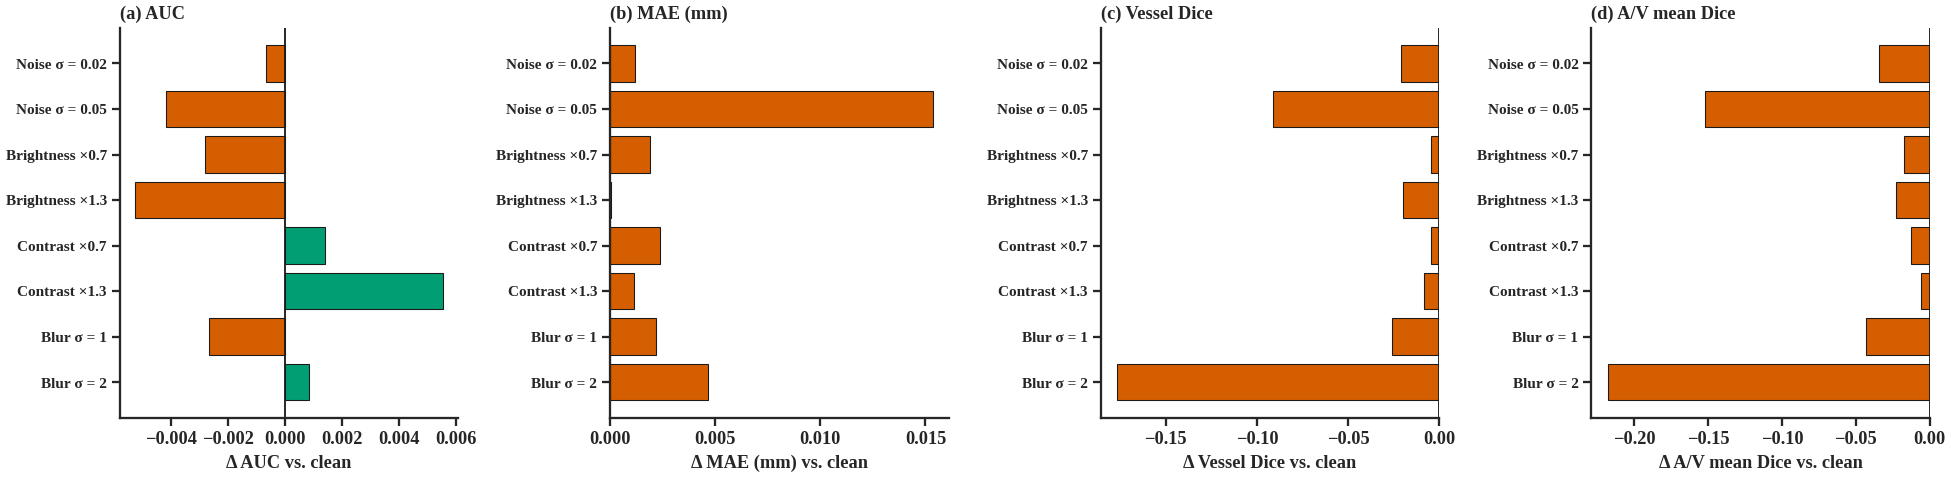

In [30]:
# ============================================================
# 24.1  Robustness: noise / brightness / contrast / blur
# ============================================================
Q1_RUN_ROBUSTNESS = True

def _gblur(x, sigma):
    k = int(2 * math.ceil(3 * sigma) + 1); ch = x.shape[1]
    ax_ = torch.arange(k, device=x.device, dtype=x.dtype) - k // 2
    ker = torch.exp(-(ax_ ** 2) / (2 * sigma ** 2)); ker = ker / ker.sum()
    kh = ker.view(1, 1, 1, k).repeat(ch, 1, 1, 1); kv = ker.view(1, 1, k, 1).repeat(ch, 1, 1, 1)
    x = F.conv2d(F.pad(x, (k // 2, k // 2, 0, 0), mode="reflect"), kh, groups=ch)
    return F.conv2d(F.pad(x, (0, 0, k // 2, k // 2), mode="reflect"), kv, groups=ch)

def _noise(s):
    def f(x):
        g = torch.Generator(device=x.device); g.manual_seed(CFG["seed"])
        return (x + s * torch.randn(x.shape, device=x.device, generator=g)).clamp(0, 1)
    return f

PERTURB = [("Clean", lambda x: x),
           ("Noise σ = 0.02", _noise(0.02)), ("Noise σ = 0.05", _noise(0.05)),
           ("Brightness ×0.7", lambda x: (x * 0.7).clamp(0, 1)), ("Brightness ×1.3", lambda x: (x * 1.3).clamp(0, 1)),
           ("Contrast ×0.7", lambda x: ((x - x.mean((1, 2, 3), keepdim=True)) * 0.7 + x.mean((1, 2, 3), keepdim=True)).clamp(0, 1)),
           ("Contrast ×1.3", lambda x: ((x - x.mean((1, 2, 3), keepdim=True)) * 1.3 + x.mean((1, 2, 3), keepdim=True)).clamp(0, 1)),
           ("Blur σ = 1", lambda x: _gblur(x, 1.0)), ("Blur σ = 2", lambda x: _gblur(x, 2.0))]

@torch.no_grad()
def eval_perturbed(fn):
    model.eval(); P, Y, R_, T_, D, AVd = [], [], [], [], [], []
    for batch in test_loader:
        img, mask, av, has_av, clin, lab, thick = [b.to(device) for b in batch]
        with autocast_ctx():
            o = model(fn(img), clin)
        pr = torch.sigmoid(o["seg"].float()); pb = (pr > 0.5).float()
        inter = (pb * mask).sum((1, 2, 3)); den = pb.sum((1, 2, 3)) + mask.sum((1, 2, 3))
        D.append(((2 * inter + 1e-6) / (den + 1e-6)).cpu())
        ap = o["av"].argmax(1)
        a = [(2 * ((ap == c) & (av == c)).sum((1, 2)).float() + 1e-6) / ((ap == c).sum((1, 2)).float() + (av == c).sum((1, 2)).float() + 1e-6) for c in (1, 2)]
        AVd.append(((a[0] + a[1]) / 2).cpu())
        P.append(torch.sigmoid(o["cls"].float()).cpu()); Y.append(lab.cpu()); R_.append(o["reg"].float().cpu()); T_.append(thick.cpu())
    P, Y, R_, T_ = [torch.cat(v).numpy() for v in (P, Y, R_, T_)]
    return {"AUC": roc_auc_score(Y, P), "Accuracy": accuracy_score(Y, (P >= THRESH).astype(int)),
            "MAE (mm)": float(np.abs(R_ - T_).mean() * SCALER["t_sd"]),
            "Vessel Dice": float(torch.cat(D).mean()), "A/V mean Dice": float(torch.cat(AVd).mean())}

if not Q1_RUN_ROBUSTNESS:
    print("Q1_RUN_ROBUSTNESS = False -> robustness analysis skipped.")
else:
    with safe("robustness"):
        rows_ = []
        for name, fn in PERTURB:
            r = eval_perturbed(fn); rows_.append({"Condition": name, **r}); print(f"  done: {name}")
        rob = pd.DataFrame(rows_)
        show_table(rob, "robustness", "Robustness of the proposed Attention U-Net to input degradation (test set, no re-training).",
                   precision=4, align="center",
                   note="Classification threshold fixed at the validation-selected value. Perturbations applied to the [0, 1] RGB input.")
        base_ = rob.iloc[0]
        fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
        for ax, (m, tag) in zip(axes, [("AUC", "a"), ("MAE (mm)", "b"), ("Vessel Dice", "c"), ("A/V mean Dice", "d")]):
            d_ = rob[m] - base_[m]
            ax.barh(range(1, len(rob)), d_.values[1:], color=[PAL[3] if v * (1 if m != "MAE (mm)" else -1) < 0 else PAL[2] for v in d_.values[1:]],
                    edgecolor="k", linewidth=0.7)
            ax.set_yticks(range(1, len(rob))); ax.set_yticklabels(rob["Condition"].values[1:], fontsize=FS - 2); ax.invert_yaxis()
            ax.axvline(0, color="k", lw=1.2); ax.set_xlabel(f"Δ {m} vs. clean"); ttl(ax, tag, m)
        plt.tight_layout()
        save_fig(fig, "robustness",
                 "Change in test performance under input degradation relative to the clean images (orange = worse, green = better): "
                 "(a) AUC, (b) CIMT MAE, (c) vessel Dice, (d) A/V mean Dice.")

## 25. Ablation study → moved to Part 2 (separate notebook)

The ablation (7 variants **re-trained from scratch**, about 5.5 h) is in **`attention-u-net-Q1_part2_ablation.ipynb`** so that this notebook fits into one Kaggle session. Part 2 is self-contained (same data, split, seed, model, losses and metrics) and does not need the checkpoint of this notebook. Its figures / tables (`ablation_protocol`, `ablation_study`, `ablation_delta`, `ablation_dotplots`, `ablation_paired_delta`, `ablation_training_curves`) are exported there.

Note: the extended checklist in Section 26b of *this* notebook checks only what was produced here, so its two ablation rows will show ✘; they are covered by Part 2.

## 26. Optional: paired significance test against Swin-UNet

This cell is **inactive until you supply the Swin-UNet prediction file**; nothing is invented. Add this one line at the end of the Swin-UNet notebook (after the test evaluation) and upload the CSV as a Kaggle dataset or copy it to `/kaggle/working`:

```python
pd.DataFrame(dict(image=test_df["base"], label=y_te, prob=p_te, thickness_true_mm=tt_te,
                  thickness_pred_mm=tp_te, dice=test_R["dice"])).to_csv("/kaggle/working/swinunet_test_predictions.csv", index=False)
```

Then set `Q1_SWIN_PREDS` below to that path. The cell reports patient-level paired-bootstrap differences (AUC, MAE, Dice) and an exact McNemar test on the classification errors.

In [31]:
# ============================================================
# 26.1  Paired significance test vs Swin-UNet (optional)
# ============================================================
Q1_SWIN_PREDS = "/kaggle/working/swinunet_test_predictions.csv"     # path of the CSV described above
Q1_SWIN_THR   = 0.651                                                 # Swin-UNet's validation-selected threshold
with safe("paired_tests"):
    if not os.path.exists(Q1_SWIN_PREDS):
        print(f"{Q1_SWIN_PREDS} not found -> paired tests skipped (see the instructions above to enable).")
    else:
        sw = pd.read_csv(Q1_SWIN_PREDS)
        sw["image"] = sw["image"].astype(str).map(lambda s: os.path.splitext(s)[0]); sw = sw.drop_duplicates("image").set_index("image")
        base_ids = te["image_name"].astype(str).map(lambda s: os.path.splitext(s)[0]).values
        assert set(base_ids) <= set(sw.index), "image names of the CSV do not match the test set"
        sw = sw.loc[base_ids]
        assert np.array_equal(sw["label"].values.astype(int), y_te), "labels of the CSV differ from the test set"
        A = dict(lab=y_te, prob=p_te, true=te["thickness"].values, pred=te["reg_mm"].values, dice=te["dice"].values)
        S = dict(lab=y_te, prob=sw["prob"].values, true=sw["thickness_true_mm"].values, pred=sw["thickness_pred_mm"].values, dice=sw["dice"].values)
        def _m(d, idx):
            return dict(AUC=roc_auc_score(d["lab"][idx], d["prob"][idx]), MAE=float(np.mean(np.abs(d["pred"][idx] - d["true"][idx]))),
                        Dice=float(np.mean(d["dice"][idx])))
        rng = np.random.default_rng(CFG["seed"]); dl = {"AUC": [], "MAE": [], "Dice": []}
        for _ in range(N_BOOT_X):
            idx = np.concatenate([pat_idx[k] for k in rng.integers(0, len(pat_idx), len(pat_idx))])
            a, s = _m(A, idx), _m(S, idx)
            dl["AUC"].append(a["AUC"] - s["AUC"]); dl["MAE"].append(s["MAE"] - a["MAE"]); dl["Dice"].append(a["Dice"] - s["Dice"])
        a0, s0 = _m(A, np.arange(len(y_te))), _m(S, np.arange(len(y_te)))
        pt = {"AUC": a0["AUC"] - s0["AUC"], "MAE": s0["MAE"] - a0["MAE"], "Dice": a0["Dice"] - s0["Dice"]}
        rows_ = []
        for k, v in dl.items():
            v = np.asarray(v, dtype=float); lo, hi = np.nanpercentile(v, [2.5, 97.5])
            rows_.append({"Metric": {"MAE": "MAE (mm)"}.get(k, k), "Δ (positive = Attention U-Net better)": pt[k], "95% CI": f"{lo:.4f} to {hi:.4f}",
                          "p (paired bootstrap)": min(1.0, 2 * min(np.nanmean(v <= 0), np.nanmean(v >= 0)))})
        ok_a = (p_te >= THRESH).astype(int) == y_te; ok_s = (S["prob"] >= Q1_SWIN_THR).astype(int) == y_te
        b, c = int((ok_a & ~ok_s).sum()), int((~ok_a & ok_s).sum())
        p_mc = float(sps.binomtest(b, b + c, 0.5).pvalue) if b + c > 0 else 1.0
        show_table(pd.DataFrame(rows_), "paired_att_vs_swin", "Paired patient-level bootstrap comparison of the proposed Attention U-Net against Swin-UNet (test set).",
                   precision=4, align="center",
                   note=f"Δ for MAE = Swin-UNet − Attention U-Net, so a positive value always favours Attention U-Net. "
                        f"McNemar exact test on classification errors: Attention-only correct = {b}, Swin-only correct = {c}, p = {p_mc:.3f}.")

/kaggle/working/swinunet_test_predictions.csv not found -> paired tests skipped (see the instructions above to enable).


## 26a. Additional qualitative evidence: random cases and zoom-in (Q1 revision)

Fig. 4 shows the best / median / difficult / worst cases ranked by Dice. Reviewers usually also ask for **non-selected** examples, so the two cells below add (i) a figure with **randomly drawn** test cases (fixed seed; the four cases of Fig. 4 are excluded) in the same six-column layout, together with a per-case metric table, and (ii) a **zoom-in** on the densest vessel region of three of those cases. The zoom window is chosen from the ground-truth vessel skeleton only (never from the prediction or the error), so it is not cherry-picked. Nothing above this section is modified.

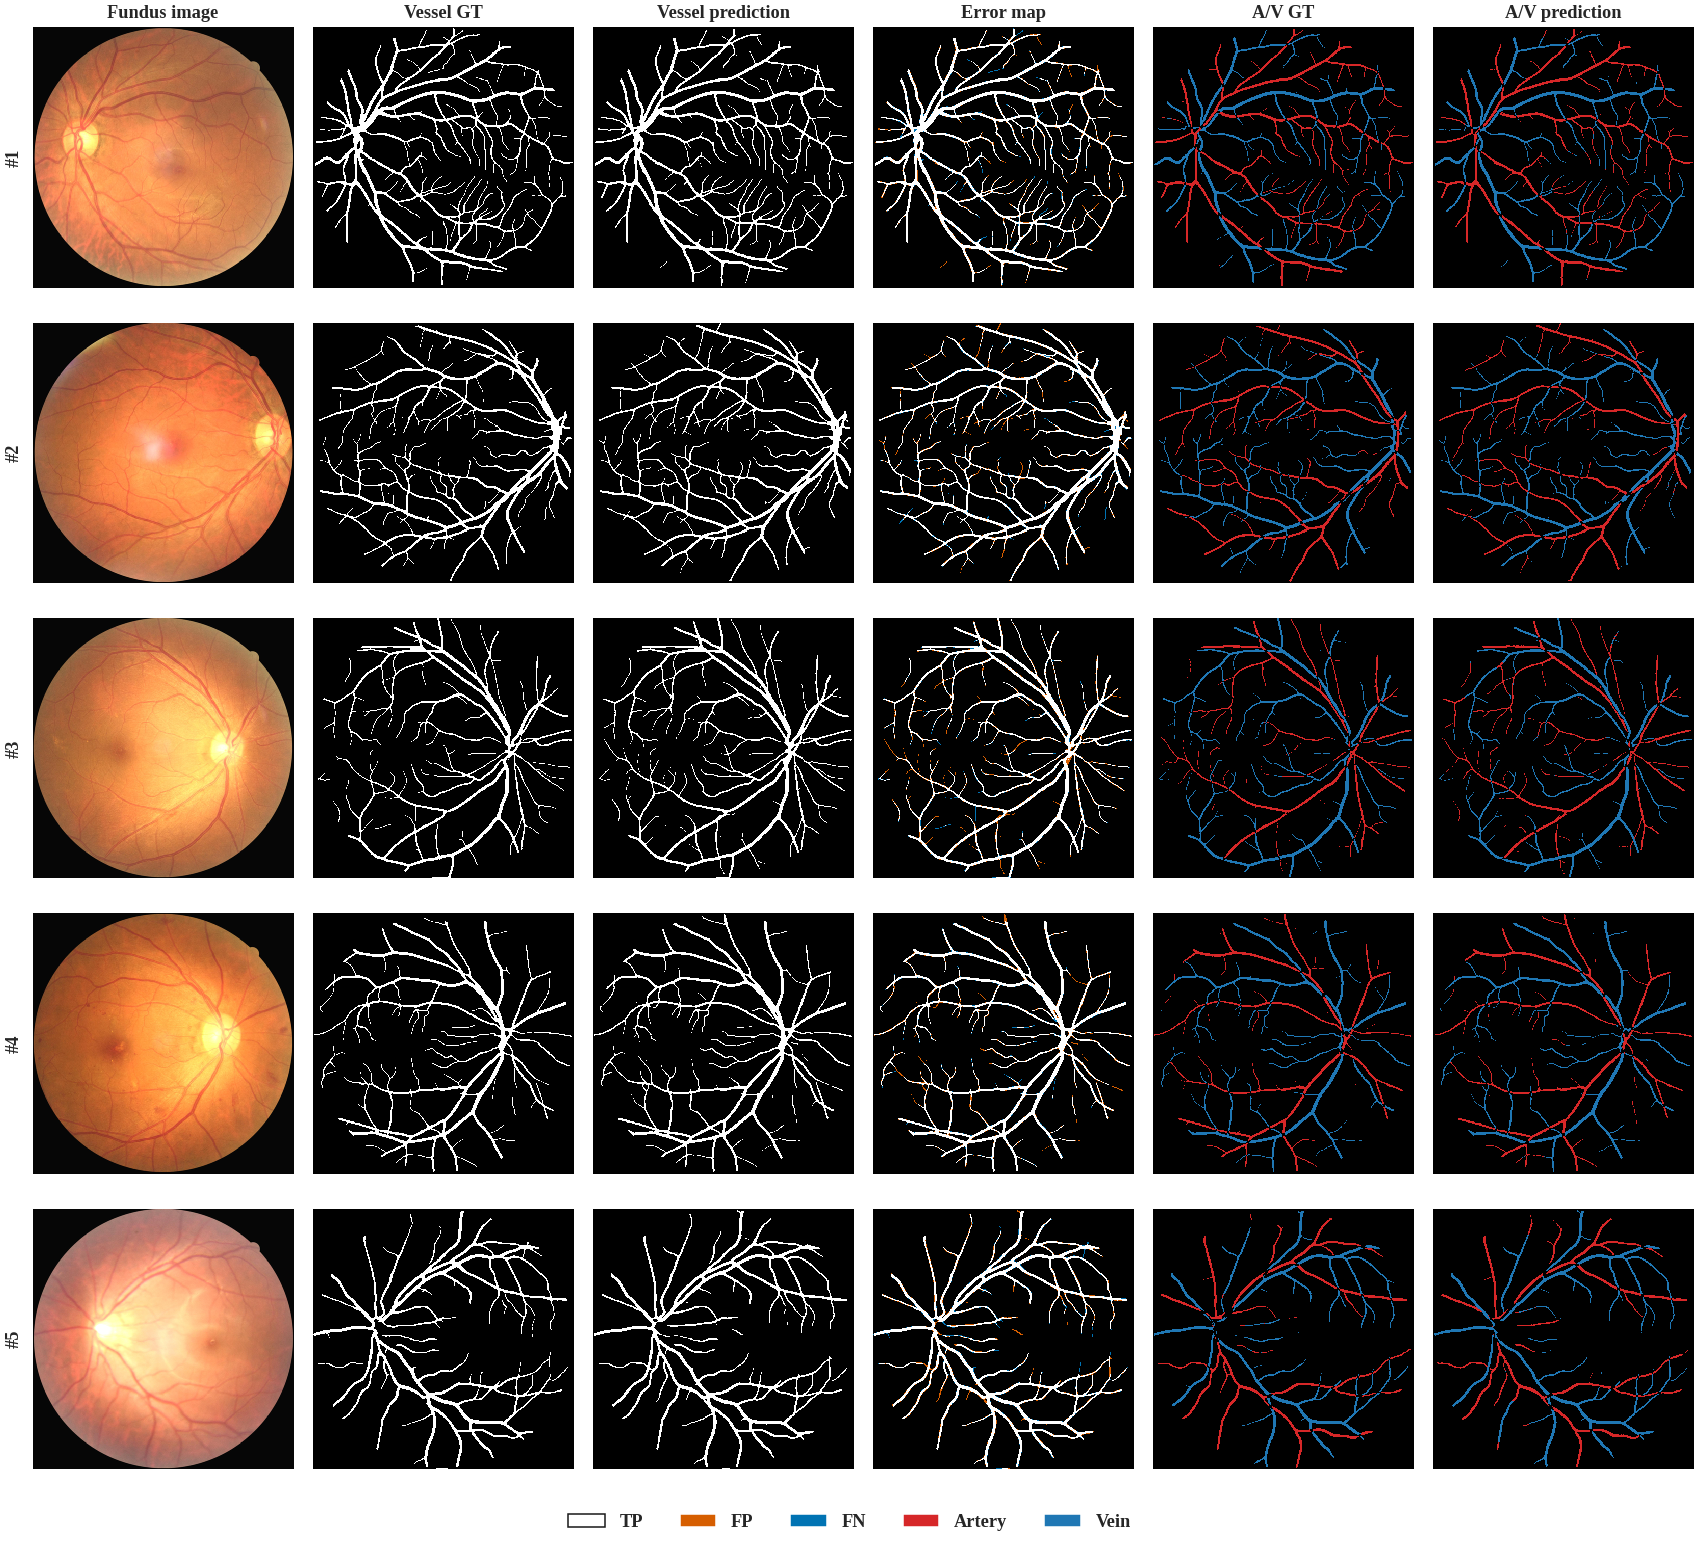

Case,Image,Dice,clDice,Thin-vessel recall,A/V Dice (mean),CIMT true (mm),CIMT pred. (mm)
#1,389178002_L.png,0.942,0.966,0.972,0.932,0.800,0.925
#2,369425001_R.png,0.936,0.956,0.977,0.927,0.800,0.921
#3,157612002_R.png,0.923,0.942,0.983,0.893,1.000,0.932
#4,181942004_R.png,0.933,0.958,0.980,0.920,1.000,1.002
#5,393007005_L.png,0.926,0.955,0.959,0.885,0.800,0.660
All test,–,0.931,0.954,0.966,0.914,–,–


In [32]:
# ============================================================
# 26a.1  Qualitative results on RANDOMLY drawn test cases (+ per-case metrics table)
# ============================================================
with safe("qualitative_random"):
    _need_q = ["te", "test_ds", "test_inf", "save_fig", "show_table", "FS", "CFG"]
    _miss_q = [v for v in _need_q if v not in globals()]
    assert not _miss_q, f"Run the sections above first. Missing: {_miss_q}"

    Q_AV_RGB = np.array([[0, 0, 0], [214, 39, 40], [31, 119, 180]], dtype=np.uint8)   # bg, artery (red), vein (blue)
    Q_N_CASES = 5

    def q_error_map(pm, gm):
        err = np.zeros((*pm.shape, 3), dtype=np.float32)
        err[pm & gm] = (1, 1, 1); err[pm & ~gm] = (0.84, 0.37, 0.0); err[~pm & gm] = (0.0, 0.45, 0.70)
        return err

    def q_panels(i):
        """fundus, vessel GT, vessel prediction, error map, A/V GT, A/V prediction for test image i"""
        img = (test_ds[i][0].permute(1, 2, 0).numpy() * 255).astype(np.uint8)
        pm, gm = test_inf["seg"][i, 0] > 127, test_inf["gt_mask"][i, 0] > 0
        return img, gm, pm, q_error_map(pm, gm), Q_AV_RGB[test_inf["gt_av"][i]], Q_AV_RGB[test_inf["av"][i]]

    # exclude the four cases already shown in Fig. 4 (same selection rule as Section 13)
    _c4 = te[te["has_av"]].sort_values("dice", ascending=False)
    if len(_c4) < 4:
        _c4 = te.sort_values("dice", ascending=False)
    _used = {_c4.index[k] for k in [0, len(_c4) // 2, int(len(_c4) * 0.85), len(_c4) - 1]}
    _pool = te[te["has_av"]].index.difference(list(_used))
    if len(_pool) < Q_N_CASES:
        _pool = te.index.difference(list(_used))
    _rng = np.random.RandomState(CFG["seed"])
    Q_RAND_IDX = [int(i) for i in _rng.choice(np.array(_pool), size=min(Q_N_CASES, len(_pool)), replace=False)]
    n_q = len(Q_RAND_IDX)

    heads_q = ["Fundus image", "Vessel GT", "Vessel prediction", "Error map", "A/V GT", "A/V prediction"]
    fig, axes = plt.subplots(n_q, 6, figsize=(16, 2.7 * n_q + 0.8), squeeze=False)
    for r, i in enumerate(Q_RAND_IDX):
        for c, pnl in enumerate(q_panels(i)):
            ax = axes[r, c]
            ax.imshow(pnl, cmap="gray" if pnl.ndim == 2 else None, interpolation="nearest"); ax.axis("off")
            if r == 0:
                ax.set_title(heads_q[c], fontsize=FS, fontweight="bold")
        axes[r, 0].text(-0.04, 0.5, f"#{r + 1}", transform=axes[r, 0].transAxes, rotation=90,
                        va="center", ha="right", fontsize=FS, fontweight="bold")
        if not te.loc[i, "has_av"]:
            axes[r, 4].text(0.5, 0.5, "no A/V GT", transform=axes[r, 4].transAxes, ha="center", color="w", fontweight="bold")
    leg_q = [Patch(fc="w", ec="k", label="TP"), Patch(fc=(0.84, 0.37, 0), label="FP"), Patch(fc=(0, 0.45, 0.70), label="FN"),
             Patch(fc=Q_AV_RGB[1] / 255, label="Artery"), Patch(fc=Q_AV_RGB[2] / 255, label="Vein")]
    fig.legend(handles=leg_q, loc="lower center", ncol=5, frameon=False, fontsize=FS)
    plt.tight_layout(rect=(0.02, 0.03, 1, 1))
    save_fig(fig, "qualitative_random_cases",
             f"Qualitative results on {n_q} randomly drawn test images (random seed {CFG['seed']}; the cases of Fig. 4 are excluded, so no "
             "selection by performance). Columns: fundus image, vessel ground truth, vessel prediction, error map (white = TP, orange = FP, "
             "blue = FN), A/V ground truth and A/V prediction (red = artery, blue = vein).")

    _cols = ["dice", "cldice", "thin_recall", "av_mean"]
    t_case = pd.DataFrame({
        "Case": [f"#{k + 1}" for k in range(n_q)],
        "Image": [str(te.loc[i, "image_name"]) for i in Q_RAND_IDX],
        "Dice": [te.loc[i, "dice"] for i in Q_RAND_IDX],
        "clDice": [te.loc[i, "cldice"] for i in Q_RAND_IDX],
        "Thin-vessel recall": [te.loc[i, "thin_recall"] for i in Q_RAND_IDX],
        "A/V Dice (mean)": [te.loc[i, "av_mean"] for i in Q_RAND_IDX],
        "CIMT true (mm)": [te.loc[i, "thickness"] for i in Q_RAND_IDX],
        "CIMT pred. (mm)": [te.loc[i, "reg_mm"] for i in Q_RAND_IDX],
    })
    t_case.loc[len(t_case)] = ["All test", "–", te["dice"].mean(), te["cldice"].mean(), te["thin_recall"].mean(),
                               te["av_mean"].mean(), np.nan, np.nan]
    show_table(t_case, "qualitative_random_metrics",
               "Per-image metrics of the randomly drawn test cases shown in the qualitative figure.",
               precision=3, align="center",
               note="Last row = mean over all test images (A/V Dice: images with A/V annotation only), to show that the displayed cases are "
                    "representative. – = not applicable.")

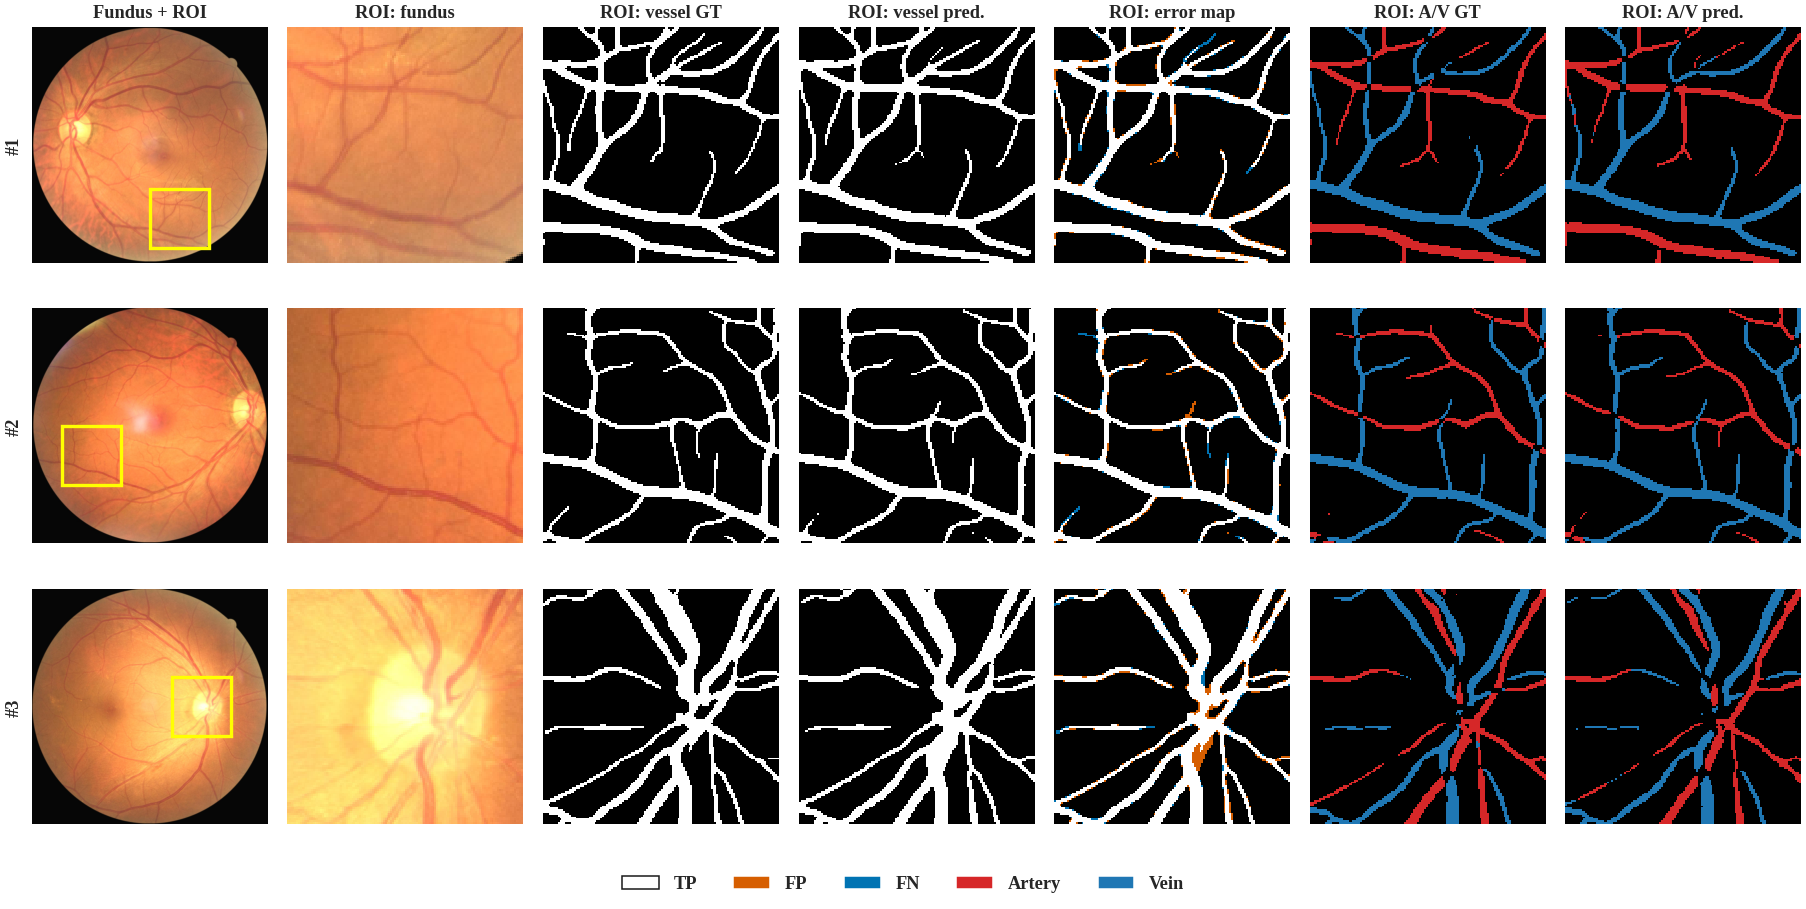

Case,"ROI (y, x)",ROI size (px),ROI vessel Dice,ROI A/V accuracy (GT vessel px),Whole-image Dice
#1,"(352, 256)",128,0.945,0.918,0.942
#2,"(256, 64)",128,0.940,0.933,0.936
#3,"(192, 304)",128,0.936,0.897,0.923


In [33]:
# ============================================================
# 26a.2  Zoom-in on the densest vessel region (ROI chosen from the ground-truth skeleton only)
# ============================================================
with safe("qualitative_zoom"):
    assert "Q_RAND_IDX" in globals(), "Run cell 26a.1 first."
    from matplotlib.patches import Rectangle
    from skimage.morphology import skeletonize

    Q_ZOOM_N = min(3, len(Q_RAND_IDX))
    sel_z = Q_RAND_IDX[:Q_ZOOM_N]
    H_z, W_z = test_inf["gt_mask"].shape[-2:]
    win = max(min(H_z, W_z) // 4, 32)            # ROI side length in pixels (128 px at 512 x 512)
    stride = max(win // 8, 4)

    def densest_window(gm, win, stride):
        """top-left corner of the win x win window that contains most ground-truth skeleton pixels"""
        sk = skeletonize(gm).astype(np.int64)
        ii = np.pad(sk.cumsum(0).cumsum(1), ((1, 0), (1, 0)))
        best, pos = -1, (0, 0)
        for y in range(0, gm.shape[0] - win + 1, stride):
            for x in range(0, gm.shape[1] - win + 1, stride):
                s = ii[y + win, x + win] - ii[y, x + win] - ii[y + win, x] + ii[y, x]
                if s > best:
                    best, pos = s, (y, x)
        return pos

    heads_z = ["Fundus + ROI", "ROI: fundus", "ROI: vessel GT", "ROI: vessel pred.", "ROI: error map", "ROI: A/V GT", "ROI: A/V pred."]
    fig, axes = plt.subplots(Q_ZOOM_N, 7, figsize=(17, 2.55 * Q_ZOOM_N + 0.9), squeeze=False)
    zrows = []
    for r, i in enumerate(sel_z):
        pn = q_panels(i)
        y0, x0 = densest_window(pn[1], win, stride)
        ax = axes[r, 0]
        ax.imshow(pn[0]); ax.axis("off")
        ax.add_patch(Rectangle((x0, y0), win, win, fill=False, ec="yellow", lw=2.2))
        for c, pnl in enumerate(pn):
            ax = axes[r, c + 1]
            crop = pnl[y0:y0 + win, x0:x0 + win]
            ax.imshow(crop, cmap="gray" if crop.ndim == 2 else None, interpolation="nearest"); ax.axis("off")
        for c in range(7):
            if r == 0:
                axes[r, c].set_title(heads_z[c], fontsize=FS, fontweight="bold")
        axes[r, 0].text(-0.04, 0.5, f"#{r + 1}", transform=axes[r, 0].transAxes, rotation=90,
                        va="center", ha="right", fontsize=FS, fontweight="bold")
        # local (ROI) metrics
        gm_c, pm_c = pn[1][y0:y0 + win, x0:x0 + win], pn[2][y0:y0 + win, x0:x0 + win]
        tp_, fp_, fn_ = int((gm_c & pm_c).sum()), int((~gm_c & pm_c).sum()), int((gm_c & ~pm_c).sum())
        roi_dice = 2 * tp_ / (2 * tp_ + fp_ + fn_) if (2 * tp_ + fp_ + fn_) > 0 else np.nan
        if te.loc[i, "has_av"] and gm_c.any():
            ga = test_inf["gt_av"][i][y0:y0 + win, x0:x0 + win]; pa = test_inf["av"][i][y0:y0 + win, x0:x0 + win]
            roi_av = float((ga[gm_c] == pa[gm_c]).mean())
        else:
            roi_av = np.nan
        zrows.append({"Case": f"#{r + 1}", "ROI (y, x)": f"({y0}, {x0})", "ROI size (px)": win,
                      "ROI vessel Dice": roi_dice, "ROI A/V accuracy (GT vessel px)": roi_av,
                      "Whole-image Dice": te.loc[i, "dice"]})
    leg_z = [Patch(fc="w", ec="k", label="TP"), Patch(fc=(0.84, 0.37, 0), label="FP"), Patch(fc=(0, 0.45, 0.70), label="FN"),
             Patch(fc=Q_AV_RGB[1] / 255, label="Artery"), Patch(fc=Q_AV_RGB[2] / 255, label="Vein")]
    fig.legend(handles=leg_z, loc="lower center", ncol=5, frameon=False, fontsize=FS)
    plt.tight_layout(rect=(0.02, 0.04, 1, 1))
    save_fig(fig, "qualitative_zoom",
             f"Zoom-in on the densest vessel region ({win} × {win} px window with the largest ground-truth skeleton length; chosen from the "
             "ground truth only, not from the prediction) of cases #1–#" + str(Q_ZOOM_N) + " of the random-case figure. First column: fundus image "
             "with the window (yellow box); remaining columns: zoomed fundus, vessel ground truth, vessel prediction, error map "
             "(white = TP, orange = FP, blue = FN), A/V ground truth and A/V prediction (red = artery, blue = vein).")

    show_table(pd.DataFrame(zrows), "qualitative_zoom_metrics",
               "Local metrics inside the zoom-in windows of the qualitative zoom figure.", precision=3, align="center",
               note="ROI A/V accuracy = fraction of ground-truth vessel pixels inside the window that receive the correct artery / vein label "
                    "(– when the image has no A/V annotation).")

## 26b. Limitations and reporting checklist

**Limitations to state in the manuscript** (reviewers will look for them):

1. Single dataset with a single patient-level split and one training seed; confidence intervals describe test-set sampling, not training variability.
2. The baseline models (Swin-UNet, ResUNet++, DCNU-AttUNet, Standard U-Net, DeepLabV3+) were trained in separate notebooks; their numbers are copied point estimates. Confusion matrices marked † are reconstructed from reported accuracy.
3. The ablation uses a reduced protocol (256 × 256, ≤ 20 epochs) to fit the compute budget; absolute values are therefore lower than the 512 × 512 headline results, only the *relative* changes are interpreted.
4. No external validation cohort; fundus-based CIMT estimation is a research prototype, not a clinical decision tool.
5. Artery–vein and vessel reference masks come from the dataset's own annotation pipeline and may contain annotation noise.

In [34]:
# ============================================================
# 26b.1  Extended reporting checklist (items are verified from what was actually produced)
# ============================================================
with safe("ext_checklist"):
    stems = {r["stem"] for r in FIG_REGISTRY} | {r["stem"] for r in TAB_REGISTRY}
    has = lambda *ss: all(s_ in stems for s_ in ss)
    items = [
        ("Patient-level split without overlap", len(p_tr & p_va) == 0 and len(p_tr & p_te) == 0 and len(p_va & p_te) == 0),
        ("Decision threshold chosen on validation only", True),
        ("95% patient-level bootstrap CIs", has("main_test_results")),
        ("Comparison with ≥ 4 baseline architectures", has("cross_model_comparison")),
        ("All confusion matrices in one figure", has("confusion_matrices_all_models")),
        ("Head-to-head comparison with CIs (Attention U-Net vs Swin-UNet)", has("head_to_head_att_vs_swin")),
        ("Ablation study with re-training and paired statistics", has("ablation_study", "ablation_delta")),
        ("Subgroup analysis", has("subgroup_analysis")),
        ("Pixel-level vessel metrics and A/V confusion matrix", has("pixel_level_vessel", "av_per_class")),
        ("Diagnostic metrics, threshold sensitivity, decision curve", has("diagnostic_metrics", "threshold_sensitivity", "diagnostic_threshold_dca")),
        ("Agreement (CCC, LoA) and calibration", has("regression_agreement", "calibration_metrics")),
        ("Explainability (attention gates, Grad-CAM)", has("attention_gates_gradcam")),
        ("Robustness to image degradation", has("robustness")),
        ("Model size / complexity reported", has("model_complexity", "complexity_att_vs_swin")),
        ("Fixed random seed and software versions logged", True),
        ("Limitations stated (Section 26b)", True),
    ]
    chk2 = pd.DataFrame([(a_, "✔" if b_ else "✘ (section skipped or failed)") for a_, b_ in items], columns=["Item", "Status"])
    show_table(chk2, "extended_checklist", "Extended reporting checklist of the study.", align="left")
    import platform
    print("python", platform.python_version(), "| torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| seed", CFG["seed"])


[WARNING] section 'ext_checklist' failed and was skipped: TypeError: unsupported operand type(s) for &: 'set' and 'float'


Traceback (most recent call last):
  File "/tmp/ipykernel_23/551471833.py", line 130, in safe
    yield
  File "/tmp/ipykernel_23/1070548969.py", line 8, in <cell line: 0>
    ("Patient-level split without overlap", len(p_tr & p_va) == 0 and len(p_tr & p_te) == 0 and len(p_va & p_te) == 0),
                                                                          ~~~~~^~~~~~
TypeError: unsupported operand type(s) for &: 'set' and 'float'


## 27. Extended export

Collects every new figure / table (CSV + LaTeX), writes `journal_captions_extended.md` and an extended zip package. The original `journal_package.zip` from Section 16 is not modified.

In [35]:
# ============================================================
# 27.1  Extended export: captions + zip
# ============================================================
with safe("extended_export"):
    cap_path = os.path.join(CFG["out_dir"], "journal_captions_extended.md")
    with open(cap_path, "w", encoding="utf-8") as f:
        f.write("# Figure captions\n\n")
        for r in FIG_REGISTRY:
            f.write(f"**{r['label']}.** {r['caption']}\n\n")
        f.write("# Table captions\n\n")
        for r in TAB_REGISTRY:
            f.write(f"**{r['label']}.** {r['caption']}" + (f" *{r['note']}*" if r.get("note") else "") + "\n\n")
    zip_path2 = os.path.join(CFG["out_dir"], "journal_package_extended.zip")
    with zipfile.ZipFile(zip_path2, "w", zipfile.ZIP_DEFLATED) as z:
        for d_ in (FIG_DIR, TAB_DIR):
            for fn in sorted(os.listdir(d_)):
                z.write(os.path.join(d_, fn), os.path.join(os.path.basename(d_), fn))
        for fn in ("test_predictions.csv", "training_history.csv", "summary_test.csv", "test_metrics_ci.json", "journal_captions_extended.md"):
            fp = os.path.join(CFG["out_dir"], fn)
            if os.path.exists(fp):
                z.write(fp, fn)
    print("Package:", zip_path2, f"({os.path.getsize(zip_path2) / 1e6:.1f} MB)")
    print("\nFigures:");  [print("  ", r["label"], "-", r["stem"]) for r in FIG_REGISTRY]
    print("Tables:");     [print("  ", r["label"], "-", r["stem"]) for r in TAB_REGISTRY]

Package: /kaggle/working/journal_package_extended.zip (306.6 MB)

Figures:
   Fig. 1 - dataset_overview
   Fig. 2 - architecture
   Fig. 3 - test_performance
   Fig. 4 - qualitative_results
   Fig. 5 - topology_quantitative
   Fig. 6 - training_curves
   Fig. 7 - confusion_matrices_all_models
   Fig. 8 - forest_att_vs_swin
   Fig. 9 - cross_model_dotplots
   Fig. 10 - accuracy_vs_complexity
   Fig. 11 - av_confusion_pixel_roc
   Fig. 12 - diagnostic_threshold_dca
   Fig. 13 - attention_gates_gradcam
   Fig. 14 - robustness
   Fig. 15 - qualitative_random_cases
   Fig. 16 - qualitative_zoom
Tables:
   Table 1 - dataset_characteristics
   Table 2 - implementation_details
   Table 3 - model_complexity
   Table 4 - main_test_results
   Table 5 - subgroup_analysis
   Table 6 - topology_thin_av_metrics
   Table 7 - q1_checklist
   Table 8 - cross_model_comparison
   Table 9 - confusion_counts
   Table 10 - head_to_head_att_vs_swin
   Table 11 - complexity_att_vs_swin
   Table 12 - model_rank

### Summary of the extension

- **Proposed model**: Attention U-Net (multi-task: vessel + artery–vein segmentation, CIMT classification and regression); all original cells unchanged.
- **Comparison**: six-model table, **all six confusion matrices in one figure**, head-to-head with Swin-UNet (95 % CIs, differences, forest plot, complexity), rank table, dot plots and accuracy–complexity plot.
- **Ablation (Section 25)**: seven re-trained variants (attention gates, topology loss, A/V task, CIMT tasks, clinical inputs, vessel-only) with CIs, paired bootstrap against the full model, dot-plot, Δ-plot and training curves; epochs are chosen automatically so that the notebook stays inside the 11-hour target; resumable.
- **Q1 additions**: pixel-level vessel metrics and A/V confusion matrix, diagnostic metrics with CI, threshold sensitivity and decision-curve analysis, Lin's CCC / limits of agreement, eye- vs patient-level performance, calibration, attention-gate maps + Grad-CAM, robustness analysis, optional paired test against Swin-UNet, limitations and extended checklist.
- **Honesty notes**: baseline rows are point estimates copied from their notebooks; confusion matrices marked † are reconstructed from reported accuracy only; overlapping CIs mean that differences in classification metrics versus Swin-UNet are not statistically established; ablation numbers come from the reduced protocol.
- **Classification**: Section 10a re-uses the selected Attention U-Net run (test AUC 0.9486, accuracy 0.885), so Table 4 and all comparisons use one consistent model; the training cell is skipped (about 3.5 h saved).